# Digit-k computation test on 30,000 training problems — Qwen2.5 7B → 0.5B (graft L17 ← L23)

STANDALONE, fresh pod. Run cell 1, RESTART the kernel, then run from cell 2 to the end.

**What this is.** The digit-k notebook (`Digitk_Computation_<pair>`) with every part unchanged, but trained on
30,000 problems instead of 3,000. The add-on run (A2) showed that a full-size map trained on 30,000 problems
delivers digit k on held-out problems much better than the 3,000-problem map. This notebook re-runs every test
with that much data: the first-token stitch, presence probes, memorisation, nulls, room, partner swaps, erasure,
the probe bottleneck and the continuation test. The last cell sets every result next to the 3,000-problem run.

**What changes. Nothing else does.**
- **Training problems:** the same 3,000 (Random(0)) plus 27,000 new ones (Random(7)), built as in A2. The eval set
  is identical to the 3,000-problem run's, so every eval bin is the same.
- **Every map is trained on all of them with the same recipe.** That covers sources, nulls, controls, writers,
  bottleneck readers and probes: ridge start, Adam 1e-3, batch 16, 6 epochs (20 for the long runs). Ten times
  the data is ten times the steps.
- **Held-out operand pairs.** Half of the eval problems' operand pairs {a, b} never appear in the 27,000 new
  problems (A2's HOLD_PAIRS). The key results are also reported split by this. On "held" pairs, the
  30,000-problem maps and probes have seen no more of that pair than the 3,000-problem ones, so a gain there
  isn't an (a, b) lookup.
- **Sanity checks.** GitHub checks that depend on the training set (S4 A/B/C, the first-token map's numbers) are
  printed next to the 3,000-problem run (INFO) instead of being checked. Eval-set checks (problem counts, bins,
  S2) still print PASS / CHECK. The PREFILL and MID_PRED maps are checked against the A2 maps they should reproduce.
- **Speed.** Training skips the recipient's layers below the graft. Their output doesn't depend on the graft, so
  it is computed once per training set and fed back in; the graft and every later layer run as before. Before any
  training, a check compares this with the full forward pass on the same batches (top-1, log-probabilities,
  gradients). If it fails, training falls back to the full forward pass automatically and prints so.
- **Part 1's "all training problems"** column is scored on a random 3,000. The training-bin numbers use every bin problem.
- **Extras, marked as such:** an MLP probe trained 4x longer at the prefill and predicting positions, and each
  map minus a lookup that knows a·b exactly but not c.

**Run.**
- Hardware: a 48 GB card and at least 48 GB of CPU RAM.
- Upload the 3,000-problem run's `digitk_computation_<pair>.json` next to this notebook for the comparisons
  (optional; for Qwen, the copy with the add-on results).
- Time: roughly 8-11 h for Gemma and 3-5 h for Qwen on an L40S; the speed check prints an estimate first.
  If the check fails, training takes about 2-3x longer. `RUN_LONG = False` saves about 2 h on Gemma, 40 min on Qwen.
- Results go to `digitk30k_<pair>.json` after every part, plots to `digitk30k_<pair>_plots/`.
- Maps are cached with a fingerprint, so a re-run after a crash skips finished training.
- `SMOKE_TEST = True` is a plumbing check only.

---
**The 3,000-problem notebook's description (every part is unchanged; read 'training problems' as all 30,000).**

**Question.** The donor's state is grafted where it has *not yet computed* digit k, and a map is
trained **directly to deliver digit k**. Transferring the donor's computation would then help, so the
training objective pushes for it. Does anything beyond the answer content transfer?

**Setup** (= CELL S4 of `Emergence_Gemma` / `Emergence_Qwen`, generalised to digit 3).
- The recipient reads the prompt plus the gold digits 1..k−1.
- The graft REPLACES its last-position state at layer `L_R`. The target is the digit-k token.
- One map per donor source, trained from scratch on digit k with S4's recipe: ridge init, Adam 1e-3,
  6 epochs, batch 16, CE on the digit-k token.
- Scope: single-position, mid-layer stitching only.

| source | donor state | role |
|---|---|---|
| `PREFILL` | the `=` token, graft layer (= S4's A) | test: digit k not computed yet |
| `MID_PRED` | the position that predicts digit k, graft layer | test: the donor is part-way to digit k |
| `MID_PRED_MID` | the same position, a layer between the graft layer and the last | dose-response: partly computed |
| `DEEP_PRED` | the same position, the donor's final (post-norm) output (= S4's B) | reference: digit k computed |
| `PRESENT` | after digit k is input, graft layer (= S4's C) | positive control: digit k present |
| `PREFILL_SP` | the space before digit 1, graft layer | probes only (the paper's first-token site) |

**Other maps.** All use the same recipe, data and number of steps; code-fed writers are ridge-initialised with λ = 1.
- `CONST`: one trained vector for every problem. The no-information null.
- `PREFIX`: a writer fed the gold digits 1..k−1, which the recipient already has. The graft wipes the
  current token, and a source may restore it, so this is the "restored the context" null.
- `SHUF_PFX`: the source's own map fed another bin problem's state that shares digits 1..k−1.
- Every source is compared with all three; the strongest is the null used.
- `PRODUCT`: a writer fed the digits of a·b plus the prefix. This is the **positive control for usable
  computation**: can the recipient finish the problem from a transferred intermediate result? It
  counts only if it beats both PREFIX and a lookup that guesses digit k from a·b and the prefix
  while ignoring c.
- `GOLD`: a writer fed gold digit k plus the prefix. This is the channel ceiling.
- `*_PFX`: a source state concatenated with the prefix. This is the fair comparator for the bottleneck.
- `*_s1`: a second training order.
- `*_MLP`: a nonlinear map.

**Bins.**
- The **eval bin** contains eval problems where the donor gets the first token AND digit k right
  (teacher-forced), and the recipient natively gets digit k wrong.
- S4's population (the donor's first token right, the recipient wrong) is scored for the GitHub sanity check.

| part | answers |
|---|---|
| 0 | **The paper's basic first-token stitch**, replicated (EXP2/EXP3, seed 0) and checked against GitHub, with its training-loss curve; the same run continues to 20 epochs to show whether the loss plateaus. |
| P | **Was digit k (or an intermediate, a·b's digit) computed at the source?** Held-out linear and MLP probes against baselines, a logit-lens ceiling (≈1 on the bin by construction) and a depth sweep. |
| T | Trains the maps; checks S4 and S2 against GitHub. PREFILL, MID_PRED, CONST and PREFIX run to 20 epochs; their 6-epoch snapshot is what every other part uses. |
| L | **Training-loss graphs** for every digit-k map (per batch and per epoch, training vs held-out), a plateau read-out, and whether 20 epochs lifts held-out conferral above the nulls. |
| 1 | **Could it just memorise?** The map vs its fair null on its OWN training problems and on the eval bin, plus per-epoch curves. |
| 2 | **Above the fair nulls?** Seed-averaged primary test; positive controls PRESENT, GOLD and PRODUCT; results split by answer length. |
| 3 | **Room to do better?** SVD truncation of dW (primary) and W, on eval and training; the MLP map vs the linear map. |
| 4 | **What content drives it?** Partner swaps (AM / PM / AB) with gating. |
| 5 | **Erasure** of digit k from the source: class-mean (primary) and orthogonalised INLP, with permuted-label and random controls. |
| 6 | **Probe bottleneck**: cross-fitted digit-k readout plus prefix, against the state+prefix map. |
| 7 | **Continuation** (= GitHub's same-bin completion test, CELL SB): on problems the recipient natively gets digit k right, does the digit-k graft help it with digit k+1? Teacher-forced on all such problems (primary), plus GitHub's free-generation paired reading; against native, no-information grafts and a matched shuffle. |
| S | Summary: each claim, its numbers and a mechanical label. Labels are a reading aid; the numbers are the result. |

**Statistics.**
- A "no effect" claim needs the upper 95% bound below the smallest effect of interest, `SESOI` = 0.05.
- The primary above-null test is Holm-corrected over the 4 primary cells (2 sources × 2 digits).
- The Part 3–6 contrasts (MLP vs linear, swap contrasts, bottleneck vs map) use 99% intervals. All
  other intervals are 95% and unadjusted.
- Parts 3–6 print a label only if the map is above its fair null; otherwise they print UNINFORMATIVE.


In [3]:
# === CELL 1: install into THIS kernel's Python (run once, then RESTART THE KERNEL) ===
# Installs with the kernel's own interpreter (sys.executable). On vast.ai (and some other hosts) the `pip` on the
# PATH belongs to a different Python than the notebook kernel, so `!pip install` leaves the kernel without
# numpy / torch. Pins = the Emergence notebooks' (transformers 4.46.3). torch: the image's build is kept if the
# kernel has one; otherwise one matched to the GPU is installed (GitHub's runs used torch 2.4.1 + CUDA 12.4;
# Blackwell cards, compute capability 12.x such as RTX 5090 / RTX PRO 6000, need a CUDA 12.8 build).
import sys, subprocess, shutil, importlib.util
print("kernel python:", sys.executable)
def _pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args])
    if r.returncode != 0:                      # a bare venv without pip: bootstrap it once and retry
        subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"])
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)
def _have(mod): return importlib.util.find_spec(mod) is not None
_cap = None
if shutil.which("nvidia-smi"):
    _out = subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap", "--format=csv,noheader"],
                          capture_output=True, text=
                          True).stdout.strip().splitlines()
    if _out:
        print("GPU:", _out[0]); _cap = float(_out[0].split(",")[-1])
if not _have("torch"):
    print("no torch in this kernel: installing one for compute capability", _cap)
    if _cap is not None and _cap >= 12:
        _pip("torch", "--index-url", "https://download.pytorch.org/whl/cu128")
    else:
        _pip("torch==2.4.1", "--index-url", "https://download.pytorch.org/whl/cu124")
_pip("transformers==4.46.3", "accelerate", "matplotlib", "huggingface_hub", "hf_transfer",
     *([] if _have("numpy") else ["numpy<2"]))
# torchvision / torchaudio from the image can clash with the torch above when transformers imports them
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision", "torchaudio"])
print("deps installed into", sys.executable, "-> RESTART THE KERNEL now, then continue from CELL 2")

kernel python: /usr/bin/python
GPU: NVIDIA L40S, 8.9



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


deps installed into /usr/bin/python -> RESTART THE KERNEL now, then continue from CELL 2


In [4]:
# === CELL 2: imports + RUN CONFIG ===
import os
os.environ.setdefault("HF_HUB_ENABLE_HF_TRANSFER", "1")
import json, math, random, time, gc, re, collections, contextlib
from fractions import Fraction
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
try: _ncpu = len(os.sched_getaffinity(0))
except AttributeError: _ncpu = os.cpu_count() or 1
torch.set_num_threads(max(1, min(8, _ncpu)))       # CPU probes on 30,000 problems; too many threads stalls some hosts
_GPU = (torch.cuda.get_device_name(0), list(torch.cuda.get_device_capability(0))) if torch.cuda.is_available() else ("cpu", None)
if torch.cuda.is_available():                  # does this torch build carry kernels for this GPU generation?
    _majors = {int(m_.group(1)[:-1]) for a_ in torch.cuda.get_arch_list() for m_ in [re.match(r"sm_(\d{2,3})", a_)] if m_}
    assert not _majors or _GPU[1][0] in _majors, (
        f"this torch ({torch.__version__}) has no kernels for {_GPU[0]} (compute capability {_GPU[1]}). In a cell run:\n"
        f"  import sys, subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '--upgrade', 'torch', "
        f"'--index-url', 'https://download.pytorch.org/whl/cu128'])\nthen RESTART THE KERNEL and run from CELL 2.")
print(f"torch {torch.__version__} | transformers {transformers.__version__} (want 4.46.3) | {_GPU[0]} cap {_GPU[1]} "
      f"(GitHub's run: torch 2.4.1+cu124, cap (8, 9))")

PAIR = "qwen"            # "gemma" or "qwen"
SMOKE_TEST = False             # True = plumbing check with tiny sizes; numbers meaningless

_PAIRS = {   # = MODEL_2B / MODEL_9B / SINGLE_PAIR (recipient layer, donor layer) in the Emergence notebooks
    "gemma": dict(MODEL_R="google/gemma-2-2b", MODEL_D="google/gemma-2-9b", L_R=20, L_D=34),
    "qwen":  dict(MODEL_R="Qwen/Qwen2.5-0.5B", MODEL_D="Qwen/Qwen2.5-7B", L_R=17, L_D=23),
}
MODEL_R, MODEL_D, L_R, L_D = (_PAIRS[PAIR][x] for x in ("MODEL_R", "MODEL_D", "L_R", "L_D"))

# --- Emergence S4 recipe, unchanged ---
N_TRAIN, N_EVAL = 3000, 2000      # = the 3,000-problem run's training problems (Random(0)) and the same eval set
N_EXTRA = 27000                   # new training problems, built as in A2: 30,000 in all
ARITH_BATCH = BATCH = 16          # recipient batches: states, training, scoring
COLLECT_BATCH = 8                 # donor batches (= collect_states_multi)
TASK_EPOCHS, RIDGE_LAMBDA = 6, 1e3
K_LIST = [2, 3]                   # digit 2 (= S4) and digit 3 (new)

# --- what to run (cut from the bottom of this list first if time is short) ---
RUN_EXTRA_SEED = True             # PREFILL and MID_PRED with a second training order (used in the primary test)
RUN_MLP_MAP = True                # nonlinear map: ridge-initialised linear map + zero-initialised MLP residual
RUN_SWAPS = True                  # Part 4 (and its partner extraction in CELL 8)
RUN_ERASURE = True                # Part 5
RUN_BOTTLENECK = True             # Part 6
RUN_CONTINUATION = True           # Part 7 (same-bin completion: does the digit-k graft help digit k+1?)
RUN_FIRST_TOKEN = True            # Part 0: the paper's basic first-token stitch (EXP2/EXP3), with loss curves
FT_SEEDS = [0]                    # first-token task-map seeds (the paper trained 5; seed 0 is the one it scores)
RUN_LONG = True                   # continue PREFILL, MID_PRED, CONST, PREFIX (and the first-token map) to LONG_EPOCHS
LONG_EPOCHS = 20                  # the 6-epoch snapshot of the same run is the map every other part uses
FREE_DONOR = True                 # drop the donor from the GPU once every donor state is extracted
CACHE_MAPS = True                 # trained maps saved with a fingerprint; a re-run loads matching ones
FAST_TRAIN = True                 # training skips the recipient layers below the graft (cached once); checked first
TRAIN_ALL_SAMPLE = 3000           # Part 1's 'all training problems' is scored on this many (random); bins use every problem
EXTRA_SEED, HOLD_SEED = 7, 11     # = A2: new problems from Random(7); held-out operand pairs from Random(11)
PROBE_MLP_STEPS_LONG = 3000       # extra (Part P): the MLP digit-k probe trained longer, at PREFILL / PREFILL_SP / MID_PRED

# --- test settings ---
SESOI = 0.05                      # smallest effect of interest (conferral points)
WRITER_LAMBDA = 1.0               # ridge lambda for code-fed writers (one-hot / softmax inputs)
MLP_MAP_HIDDEN = 1024
SVD_RANKS = [1, 2, 4, 8, 16, 32, 64, 128, 256]       # + 0 and full
INLP_RANKS = [10, 20, 40, 80, 160]                    # 10 directions per round (a 10-way digit probe)
SHUF_SEEDS = [0, 1, 2]
TRAIN_SAMPLE = 800                # training-bin problems scored per SVD rank
MONITOR_SAMPLE = 600              # training-bin problems scored after every epoch
PROBE_MLP_STEPS = 800             # = probe_mlp (Followup3_MLPprobe)
N_FOLDS = 5                       # cross-fitted bottleneck readers
SWAP_SEED, N_CAND, MIN_GAP = 1234, 3, 2               # partner swaps: up to N_CAND tries, digit-k gap >= MIN_GAP
BN_SEED = 0
LONG_MAPS = ("PREFILL", "MID_PRED", "CONST", "PREFIX")
MAX_NEW_ARITH = 8                 # = Emergence: greedy tokens for full-answer generation (Part 0)
MIN_CONT_N = 30                   # Part 7 needs at least this many solvable-bin problems
CONT_MAX_NEW = 6                  # greedy tokens generated after digit k-1 (answers have <= 4 digits)
BOOT_B = 4000
CODE_VERSION = "digitk30k-v1"
if SMOKE_TEST:
    N_TRAIN, N_EVAL, TASK_EPOCHS = 300, 250, 2
    N_EXTRA, TRAIN_ALL_SAMPLE, PROBE_MLP_STEPS_LONG = 600, 200, 100
    SVD_RANKS, INLP_RANKS, SHUF_SEEDS = [1, 4, 16], [10, 20], [0, 1]
    TRAIN_SAMPLE, MONITOR_SAMPLE, PROBE_MLP_STEPS, MLP_MAP_HIDDEN, N_CAND, BOOT_B = 80, 60, 60, 64, 2, 500
    MIN_CONT_N = 5
    LONG_EPOCHS = TASK_EPOCHS + 2
assert SHUF_SEEDS and INLP_RANKS and SVD_RANKS

TAG = f"digitk30k_{PAIR}" + ("_SMOKE" if SMOKE_TEST else "")
REF3K_JSON = f"digitk_computation_{PAIR}" + ("_SMOKE" if SMOKE_TEST else "") + ".json"   # the 3,000-problem run (optional)
OUT_JSON = TAG + ".json"
CACHE_DIR = f"{TAG}_maps_{CODE_VERSION}"
PLOT_DIR = f"{TAG}_plots"
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(PLOT_DIR, exist_ok=True)
SANITY = {}
RESULTS = {"_config": dict(pair=PAIR, donor=MODEL_D, recipient=MODEL_R, L_R=L_R, L_D=L_D, n_train=N_TRAIN,
                           n_eval=N_EVAL, epochs=TASK_EPOCHS, k_list=K_LIST, smoke=SMOKE_TEST, sesoi=SESOI,
                           mlp_map_hidden=MLP_MAP_HIDDEN, min_gap=MIN_GAP, code_version=CODE_VERSION,
                           long_epochs=LONG_EPOCHS if RUN_LONG else None, ft_seeds=FT_SEEDS,
                           torch=torch.__version__, transformers=transformers.__version__,
                           gpu=_GPU[0], cuda_capability=_GPU[1]),
           "SANITY": SANITY}
RESULTS["_config"].update(n_extra=N_EXTRA, n_train_total=N_TRAIN + N_EXTRA, train_all_sample=TRAIN_ALL_SAMPLE,
                          extra_seed=EXTRA_SEED, hold_seed=HOLD_SEED, fast_train_requested=FAST_TRAIN)
PER_ITEM = {}
def save(tag=""):
    with open(OUT_JSON, "w") as f:
        json.dump({**RESULTS, "per_item": PER_ITEM, "_last": tag}, f, indent=1, default=str)
    print(f"  [saved {OUT_JSON}{' after ' + tag if tag else ''}]")

# --- what the GitHub Emergence runs got (sanity targets) ---
_REF = {
    "gemma": dict(n_donor_solved=1693,
                  ft=dict(n_unsolv=632, task_first=0.886, recon_first=0.191, native_full=0.003, recon_full=0.034,
                          task_full=0.127, final_batch_ce=0.008, task_solv_first=0.951, recon_cos_recon=0.981,
                          recon_cos_task=0.219, shuffle_first=0.102),
                  s4=dict(n_eval=1693, n_fail=1233, A=0.234, B=0.515, C=0.999, C_shuffle=0.102),
                  s2_n=1384, s2={34: dict(prefill_d2=0.16, diag_d2=0.182, diag_d3=0.585),
                                 37: dict(prefill_d2=0.22, diag_d2=0.364, diag_d3=0.71),
                                 41: dict(prefill_d2=0.24, diag_d2=0.455, diag_d3=0.73)}),
    "qwen": dict(n_donor_solved=1681,
                 ft=dict(n_unsolv=568, task_first=0.794, recon_first=0.134, native_full=0.000, recon_full=0.005,
                         task_full=0.038, final_batch_ce=0.094, task_solv_first=0.868, recon_cos_recon=0.991,
                         recon_cos_task=0.071, shuffle_first=0.178),
                 s4=dict(n_eval=1681, n_fail=1240, A=0.149, B=0.436, C=0.998, C_shuffle=0.106),
                 s2_n=1379, s2={23: dict(prefill_d2=0.157, diag_d2=0.171, diag_d3=0.335),
                                25: dict(prefill_d2=0.204, diag_d2=0.233, diag_d3=0.546),
                                27: dict(prefill_d2=0.228, diag_d2=0.394, diag_d3=0.583)}),
}
REF = _REF[PAIR]
def check(name, got, want, tol, warn=None, ref="github"):
    """PASS within tol; WARN within warn (a bf16 argmax tie or a different GPU can move a few items); CHECK
    beyond. SMOKE runs record SKIP (tiny data, nothing to compare)."""
    if SMOKE_TEST: st = "SKIP"
    else:
        d = abs(got - want)
        st = "PASS" if d <= tol else ("WARN" if warn is not None and d <= warn else "CHECK")
    SANITY[name] = {ref: want, "this_run": got, "status": st}
    print(f"  {st:5s} {name:52s} {ref} {want}   this run {got}")
print("PAIR =", PAIR, "| SMOKE_TEST =", SMOKE_TEST, "| device", DEVICE)

# --- the 3,000-problem run (optional upload), and the A2 maps the 30,000-problem PREFILL / MID_PRED maps should match ---
REF3K, REF3K_PATH = None, None
for _cand in (REF3K_JSON, REF3K_JSON[:-5] + " (1).json"):      # a browser download may carry " (1)"; prefer the copy with A2
    if os.path.exists(_cand):
        with open(_cand) as _f: _j = json.load(_f)
        if REF3K is None or ("ADDON" in _j and "ADDON" not in REF3K): REF3K, REF3K_PATH = _j, _cand
if REF3K is not None:
    print(f"3,000-problem results loaded from {REF3K_PATH} (code {REF3K.get('_config', {}).get('code_version')}, "
          f"add-on (A2) results {'present' if 'ADDON' in REF3K else 'ABSENT: upload the copy made after the add-on'})")
else:
    print(f"no {REF3K_JSON} here: the comparisons with the 3,000-problem run are skipped (upload it to get them)")
def ref3k_get(*path):
    """A value from the 3,000-problem run's JSON by key path, or None."""
    v = REF3K
    for p_ in path:
        if not isinstance(v, dict) or p_ not in v: return None
        v = v[p_]
    return v
_A2_FALLBACK = {   # held-out eval-bin conferral of A2's 30,000-problem maps (the add-on runs), if the JSON lacks them
    "gemma": {"d2/PREFILL": 0.4974, "d2/MID_PRED": 0.5858, "d3/PREFILL": 0.425, "d3/MID_PRED": 0.8885},
    "qwen": {"d2/PREFILL": 0.2134, "d2/MID_PRED": 0.3536, "d3/PREFILL": 0.4364, "d3/MID_PRED": 0.6198}}
def a2_ref(k, S):
    v = ref3k_get("ADDON", "bigdata", f"d{k}", S, f"vs_{TASK_EPOCHS}-epoch_nulls", "eval_bin", "rate")
    return v if v is not None else _A2_FALLBACK.get(PAIR, {}).get(f"d{k}/{S}")
VS3K = {}; RESULTS["vs_3k_sanity"] = VS3K
def info3k(name, got, ref3k, github=None):
    """A number that depends on the training set, next to the 3,000-problem run's (and GitHub's): reported, not checked."""
    VS3K[name] = {"this_run_30k": got, "run_3k": ref3k, **({"github_3k": github} if github is not None else {})}
    print(f"  INFO  {name:52s} 30k {got}   3k run {ref3k}" + (f"   GitHub (3k) {github}" if github is not None else ""))

torch 2.4.1+cu124 | transformers 4.46.3 (want 4.46.3) | NVIDIA L40S cap [8, 9] (GitHub's run: torch 2.4.1+cu124, cap (8, 9))
PAIR = qwen | SMOKE_TEST = False | device cuda
no digitk_computation_qwen.json here: the comparisons with the 3,000-problem run are skipped (upload it to get them)


In [ ]:
# === CELL 3: Hugging Face login (Gemma is gated; Qwen is not) ===
from huggingface_hub import login
_tok = os.environ.get("") or ""   # paste, run, then clear before sharing
if PAIR == "gemma" or not _tok.startswith("hf_PASTE"):
    login(_tok); print("logged in")
else:
    print("no token set; Qwen is not gated, continuing")
del _tok

logged in


In [6]:
# === CELL 4: statistics helpers ===
def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"),) * 3
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = (z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / d
    return p, max(0.0, c - h), min(1.0, c + h)
def wilson_bools(b, z=1.96):
    b = np.asarray(b, bool); return wilson(int(b.sum()), int(b.size), z)
def fmt(tr): p, lo, hi = tr; return f"{p:.3f} [{lo:.3f}, {hi:.3f}]"
def rate(v):
    v = [x for x in v if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return round(float(np.mean(v)), 4) if len(v) else None
def mcnemar_exact(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01 = int((~a & b).sum()); n10 = int((a & ~b).sum()); n = n01 + n10
    if n == 0: return dict(n01=0, n10=0, p=1.0)
    k = min(n01, n10); tot = Fraction(0)
    for i in range(0, k + 1): tot += Fraction(math.comb(n, i))
    return dict(n01=n01, n10=n10, p=min(1.0, float(2 * tot / Fraction(2) ** n)))
def R(ok):
    """Rate with a Wilson 95% interval."""
    ok = [bool(x) for x in ok]
    if not ok: return {"n": 0, "rate": None, "ci": None}
    return {"n": len(ok), "rate": round(float(np.mean(ok)), 4), "ci": fmt(wilson_bools(ok))}
def paired(a, b, seed=0, alpha=0.05):
    """b minus a on the same items (NaN pairs dropped): mean difference, percentile-bootstrap interval at
    level 1-alpha, two-sided bootstrap p; exact McNemar when both are 0/1."""
    a = np.asarray(a, float); b = np.asarray(b, float); keep = ~(np.isnan(a) | np.isnan(b)); a, b = a[keep], b[keep]
    d = b - a
    if len(d) == 0: return {"n": 0, "diff": None, "lo": None, "hi": None, "ci": None, "p_boot": None, "level": 1 - alpha}
    rng = np.random.default_rng(seed); m = d[rng.integers(0, len(d), (BOOT_B, len(d)))].mean(1)
    lo, hi = np.percentile(m, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = float(min(1.0, 2 * min((m <= 0).mean(), (m >= 0).mean())))
    out = {"n": int(len(d)), "diff": round(float(d.mean()), 4), "lo": round(float(lo), 4), "hi": round(float(hi), 4),
           "ci": f"{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]", "p_boot": round(p, 5), "level": 1 - alpha}
    if set(np.unique(a)) <= {0.0, 1.0} and set(np.unique(b)) <= {0.0, 1.0}:
        mc = mcnemar_exact(a > 0.5, b > 0.5); out.update(only_a=mc["n10"], only_b=mc["n01"], mcnemar_p=mc["p"])
    return out
def holm(pvals):
    """Holm step-down adjusted p-values for a dict name -> p."""
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out = {}; run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p)); out[k] = round(run, 5)
    return out
def effect_label(p, what="effect"):
    """Three-way: ABOVE (interval > 0) / BELOW (< 0) / no detectable effect, with its upper bound; 'equivalent
    to none' only when the upper bound is below SESOI."""
    if p is None or p.get("lo") is None: return "n/a"
    if p.get("only_a") == 0 and p.get("only_b") == 0:
        return f"identical on all {p['n']} items (no discordant pairs; the interval is degenerate)"
    if p["lo"] > 0: return f"ABOVE ({p['ci']})"
    if p["hi"] < 0: return f"BELOW ({p['ci']})"
    return (f"no detectable {what}: at most {p['hi']:+.3f}" +
            (f" (< SESOI {SESOI}: equivalent to none)" if p["hi"] < SESOI else f" (cannot rule out {SESOI})"))
def above(p): return p is not None and p.get("lo") is not None and p["lo"] > 0
print("stats ready")

stats ready


In [7]:
# === CELL 5: shared helpers (= Emergence CELL 5, the parts S4 uses) ===
PATCH_POS = -1
def _hid(o): return o[0] if isinstance(o, tuple) else o
def _pack(o, h): return (h,) + tuple(o[1:]) if isinstance(o, tuple) else h
def left_pad(id_list, pad_id):
    L = max(t.numel() for t in id_list)
    ids = torch.full((len(id_list), L), pad_id, dtype=torch.long)
    m = torch.zeros((len(id_list), L), dtype=torch.long)
    for i, t in enumerate(id_list):
        t = t.flatten(); ids[i, L - t.numel():] = t; m[i, L - t.numel():] = 1
    return ids, m
def fit_ridge(X9, X2, lam=RIDGE_LAMBDA):
    mu9, mu2 = X9.mean(0), X2.mean(0)
    A, B = X9 - mu9, X2 - mu2
    W = torch.linalg.solve(A.T @ A + lam * torch.eye(A.shape[1]), A.T @ B)
    return mu9, mu2, W
FEWSHOT = ("2 + 5 = 7\n6 * 3 = 18\n4 * 7 + 2 = 30\n9 * 8 = 72\n"
           "3 * 4 + 5 = 17\n40 * 20 = 800\n")
def _aprompt(expr): return f"{FEWSHOT}{expr} ="
def _aencode(tok, expr, ans):
    p = tok(_aprompt(expr)).input_ids
    f = tok(_aprompt(expr) + " " + str(ans)).input_ids
    if f[:len(p)] != p or len(f) <= len(p): return None, None
    j = len(p)
    while j < len(f) and not any(ch.isdigit() for ch in tok.decode([f[j]])): j += 1
    if j >= len(f): return None, None
    return torch.tensor(f[:j]), f[j]
def gen_arith(tok, n, rng, exclude=None):
    exclude = exclude or set(); out, seen = [], set()
    tries = 0
    while len(out) < n and tries < n * 120:
        tries += 1
        a, b, c = rng.randint(2, 40), rng.randint(2, 40), rng.randint(1, 99)
        expr, ans = f"{a} * {b} + {c}", a * b + c
        if expr in seen or expr in exclude: continue
        seen.add(expr)
        ids, tok_id = _aencode(tok, expr, ans)
        if tok_id is None: continue
        out.append(dict(expr=expr, ans=ans, ids=ids, tok=tok_id))
    return out
@torch.inference_mode()
def states_and_top(model, layers, prob_ids, batch=ARITH_BATCH):
    acc = {L: [] for L in layers}; top = []
    for i in range(0, len(prob_ids), batch):
        ids, m = left_pad(prob_ids[i:i + batch], tokenizer.pad_token_id)
        out = model(ids.to(DEVICE), attention_mask=m.to(DEVICE), output_hidden_states=True)
        for L in layers: acc[L].append(out.hidden_states[L + 1][:, -1, :].float().cpu())
        top += out.logits[:, -1, :].argmax(-1).cpu().tolist()
    return {L: torch.cat(v) for L, v in acc.items()}, top
_graft = {"vec": None}
def patch_vec_batch(_m, _i, o):
    h = _hid(o); vec = _graft["vec"]
    if vec is None or h.shape[1] <= 1 or h.shape[0] != vec.shape[0]:
        return o
    h2 = torch.cat([h[:, :-1, :], vec.to(h.dtype).unsqueeze(1)], 1)
    return _pack(o, h2)
_EXPR_RE = re.compile(r"^(\d+) \* (\d+) \+ (\d+)$")
def _ex(a, b, c): return f"{a} * {b} + {c}"
def _parse_first_int(text):
    """Arithmetic answers: the FIRST integer the model emits after '=' (= Emergence CELL 5)."""
    m = re.search(r"-?\d+", text)
    return float(m.group()) if m else None
@torch.inference_mode()
def arith_fullanswer_correct(model, layer, probs, vecs=None, batch=ARITH_BATCH):
    """= Emergence CELL 5: generate the full number, compare to gold; vecs[i] grafted at the last prompt
    position of problem i during prefill."""
    ok, handle = [], None
    if vecs is not None:
        handle = model.model.layers[layer].register_forward_hook(patch_vec_batch)
    try:
        for i in range(0, len(probs), batch):
            chunk = probs[i:i + batch]
            ids, m = left_pad([p["ids"] for p in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            _graft["vec"] = (torch.stack(vecs[i:i + len(chunk)]).to(DEVICE) if vecs is not None else None)
            gen = model.generate(ids, attention_mask=m, max_new_tokens=MAX_NEW_ARITH,
                                 do_sample=False, pad_token_id=tokenizer.eos_token_id)
            txt = tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True)
            for p, t in zip(chunk, txt):
                pred = _parse_first_int(t)
                ok.append(pred is not None and abs(pred - p["ans"]) < 0.5)
    finally:
        if handle: handle.remove()
        _graft["vec"] = None
    return ok
def _fwd_kwargs(model):
    """For the recipient's logits-only forwards: no KV cache, and logits for the last position only if this
    transformers supports it. The scores are the same; it is faster and needs far less memory."""
    import inspect
    ps = inspect.signature(model.forward).parameters; kw = {"use_cache": False}
    for nm in ("num_logits_to_keep", "logits_to_keep"):
        if nm in ps: kw[nm] = 1; break
    return kw
_FWD_KW = {}
print("helpers ready")

helpers ready


In [8]:
# === CELL 6: load both models (bf16, eager attention), assert a shared tokenizer (= Emergence CELL 6) ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_R)
tokenizer.padding_side = "left"
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
model_r = AutoModelForCausalLM.from_pretrained(MODEL_R, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_d = AutoModelForCausalLM.from_pretrained(MODEL_D, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_r.requires_grad_(False); model_d.requires_grad_(False)
with torch.inference_mode():
    _hl = model_d(tokenizer("The capital of France is", return_tensors="pt").to(DEVICE).input_ids).logits[0, -1, :]
assert not torch.isnan(_hl).any() and not torch.isinf(_hl).any(), "donor produced NaN/Inf logits"
del _hl
_t1, _t2 = AutoTokenizer.from_pretrained(MODEL_R), AutoTokenizer.from_pretrained(MODEL_D)
_probe = "3 * 12 + 7 = 43\nThe answer is 256."
assert _t1(_probe).input_ids == _t2(_probe).input_ids, "tokenizer mismatch: positions would not align"
del _t1, _t2
print("loaded:", model_r.config.num_hidden_layers, "recipient layers,", model_d.config.num_hidden_layers, "donor layers")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

... (10 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

loaded: 24 recipient layers, 28 donor layers


In [9]:
# === CELL 7: problems; the eval side (bins); Part 4's partners; then the 27,000 new training problems ===
# Problems: = Emergence CELL 8 (train Random(0), eval Random(1) excluding train, eval kept if the donor's
# first answer token is right). Items: = S4's _prep, generalised to digit k. Donor states: = S4's
# collect_states_multi (right-padded, batch 8, hidden_states[L+1]), several layers per forward. DEEP is
# hidden_states[num_layers] = the donor's final post-norm output, exactly S4's B.
# ORDER (30,000-problem version). The eval side and the partner search depend only on the eval problems and the
# 3,000 original training problems, so they run first, exactly as in the 3,000-problem run. The 27,000 new problems
# are then drawn with A2's exclusions, which include those partners: the training set is exactly A2's and the
# partners are exactly the 3,000-problem run's (none of them, or its twin, is a training problem). CELL 8 does the
# training side on all 30,000.
D_R, D_D = model_r.config.hidden_size, model_d.config.hidden_size
DEEP = model_d.config.num_hidden_layers - 1
SWEEP = sorted(set([L_D, L_D + (DEEP - L_D) // 2, DEEP]))      # = Emergence S2's depth sweep
POS_KEYS = ("eq", "sp", "pred", "post")
SRC = {"PREFILL": ("eq", L_D), "PREFILL_SP": ("sp", L_D), "MID_PRED": ("pred", L_D),
       "DEEP_PRED": ("pred", DEEP), "PRESENT": ("post", L_D)}
if len(SWEEP) == 3: SRC["MID_PRED_MID"] = ("pred", SWEEP[1])
SRC_NOTE = {"PREFILL": "'=' token, graft layer (= S4 A)", "PREFILL_SP": "space before digit 1, graft layer",
            "MID_PRED": "position predicting digit k, graft layer",
            "MID_PRED_MID": f"position predicting digit k, layer {SWEEP[1] if len(SWEEP) == 3 else '-'}",
            "DEEP_PRED": "same position, donor final post-norm output (= S4 B)",
            "PRESENT": "after digit k is input, graft layer (= S4 C)"}

def _digit_toks(full, base_len, ans):            # = S4
    dg = []
    for j in range(base_len, len(full)):
        for ch in tokenizer.decode([full[j]]):
            if ch.isdigit() and len(dg) < len(ans): dg.append(j)
    return dg
def prep_one(expr, ans, k, src=None):
    """S4's _prep for one problem, digit k: context = prompt + gold digits 1..k-1, target = digit-k token."""
    astr = str(abs(int(ans)))
    if len(astr) < k: return None
    base = tokenizer(_aprompt(expr)).input_ids
    full = tokenizer(_aprompt(expr) + " " + astr).input_ids
    if full[:len(base)] != base: return None
    dg = _digit_toks(full, len(base), astr)
    if len(dg) < k or len(set(dg[:k])) < k: return None          # each of digits 1..k is its own token
    pk = dg[k - 1]
    a, b, c = (int(x) for x in _EXPR_RE.match(expr).groups())
    return dict(src=src, expr=expr, abc=(a, b, c), lens=(len(str(a)), len(str(b)), len(str(c))), ans=int(ans),
                astr=astr, k=k, dk=int(astr[k - 1]), prefix=astr[:k - 1],
                pdig=(a * b // 10 ** (len(astr) - k)) % 10,              # digit of a*b at digit k's place value
                ctx=torch.tensor(full[:pk]), tgt=full[pk], full=torch.tensor(full),
                dpos=dg[:k], pos=dict(eq=len(base) - 1, sp=dg[0] - 1, pred=pk - 1, post=pk))

@torch.inference_mode()
def donor_collect(items, layers, pos_keys, batch=COLLECT_BATCH):
    """Donor states at several (position, layer) pairs, one forward per batch (right-padded, batch 8, as
    S4). Also sets it['tf']: is the donor's teacher-forced top-1 right on each of digits 1..k."""
    out = {(pk, L): [] for pk in pos_keys for L in layers}
    for i in range(0, len(items), batch):
        chunk = items[i:i + batch]
        T = max(it["full"].numel() for it in chunk)
        ids = torch.full((len(chunk), T), tokenizer.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(chunk), T), dtype=torch.long)
        for r, it in enumerate(chunk):
            n = it["full"].numel(); ids[r, :n] = it["full"]; att[r, :n] = 1
        o = model_d(ids.to(DEVICE), attention_mask=att.to(DEVICE), output_hidden_states=True)
        for r, it in enumerate(chunk):
            for L in layers:
                hs = o.hidden_states[L + 1]
                for pk in pos_keys: out[(pk, L)].append(hs[r, it["pos"][pk]].cpu())
            lp = torch.tensor([d - 1 for d in it["dpos"]], device=o.logits.device)
            pred = o.logits[r, lp].argmax(-1).cpu().tolist()
            it["tf"] = [int(pv) == int(it["full"][d]) for pv, d in zip(pred, it["dpos"])]
    return {key: torch.stack(v) for key, v in out.items()}
@torch.inference_mode()
def collect_plain(seqs, pos_lists, layers, batch=COLLECT_BATCH):
    """= Emergence S0 collect_states_multi (right-padded, batch 8) for several layers: {L: [N, npos, d]}."""
    out = {L: [] for L in layers}
    for i in range(0, len(seqs), batch):
        chunk = seqs[i:i + batch]; plists = pos_lists[i:i + batch]
        T = max(s.numel() for s in chunk)
        ids = torch.full((len(chunk), T), tokenizer.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(chunk), T), dtype=torch.long)
        for r, s in enumerate(chunk): ids[r, :s.numel()] = s; att[r, :s.numel()] = 1
        hs = model_d(ids.to(DEVICE), attention_mask=att.to(DEVICE), output_hidden_states=True).hidden_states
        for L in layers:
            for r, pl in enumerate(plists):
                out[L].append(hs[L + 1][r, torch.tensor(pl, device=hs[L + 1].device), :].cpu())
    return {L: torch.stack(v) for L, v in out.items()}

def digit_onehot(digs_list, n_digits):
    out = torch.zeros(len(digs_list), 10 * n_digits)
    for r, ds in enumerate(digs_list):
        for j, d in enumerate(ds): out[r, 10 * j + int(d)] = 1.0
    return out
def prefix_code(items, k): return digit_onehot([it["prefix"] for it in items], k - 1)

t0 = time.time()
_FWD_KW.update(_fwd_kwargs(model_r)); print("recipient logits-only forward kwargs:", _FWD_KW)
train = gen_arith(tokenizer, N_TRAIN, random.Random(0))                                   # = the 3,000-problem run
evalp_all = gen_arith(tokenizer, N_EVAL, random.Random(1), {p["expr"] for p in train})    # = the same eval set
TRAIN3K_EXPRS = {p["expr"] for p in train}
TRAIN_EXPRS = set(TRAIN3K_EXPRS)        # the 3,000 until the new problems are added: the partners are chosen against these
# donor states at the last prompt position (= Emergence CELL 8's X9e), kept for Part 0
_X9e_all, _dtop_ev = states_and_top(model_d, [L_D], [p["ids"] for p in evalp_all])
_keep_ev = [i for i, (p, t) in enumerate(zip(evalp_all, _dtop_ev)) if t == p["tok"]]
evalp = [evalp_all[i] for i in _keep_ev]
X9E_FT = _X9e_all[L_D][_keep_ev]; del _X9e_all
print(f"arith: {len(evalp_all)} eval generated, donor first token right on {len(evalp)}")
print("SANITY (problems vs GitHub Emergence CELL 8):")
check("eval problems the donor solves (first token)", len(evalp), REF["n_donor_solved"], 0, warn=2)
# held-out operand pairs (= A2): a random half of the eval problems' pairs {a, b}; no new training problem uses one
def _ab(e): a, b, c = (int(x) for x in _EXPR_RE.match(e).groups()); return a, b, c
EVAL_EXPRS = {p["expr"] for p in evalp_all}
EVAL_TWINS = {_ex(b, a, c) for a, b, c in map(_ab, EVAL_EXPRS)}
EVAL_PAIRS = sorted({tuple(sorted(_ab(e)[:2])) for e in EVAL_EXPRS})
HOLD_PAIRS = set(random.Random(HOLD_SEED).sample(EVAL_PAIRS, len(EVAL_PAIRS) // 2))
HOLD_EXPRS = ({_ex(a, b, c) for a, b in HOLD_PAIRS for c in range(1, 100)} |
              {_ex(b, a, c) for a, b in HOLD_PAIRS for c in range(1, 100)})
EV_HELD = [tuple(sorted(_ab(p["expr"])[:2])) in HOLD_PAIRS for p in evalp]     # per kept eval problem (aligned with evalp)
DS = {}
for k in K_LIST:
    ev = [it for it in (prep_one(p["expr"], p["ans"], k, i) for i, p in enumerate(evalp)) if it is not None]
    for it in ev:
        a, b, c = it["abc"]; it["twin"] = a != b and _ex(b, a, c) in TRAIN_EXPRS    # b*a+c (same answer) was trained on
        it["held"] = EV_HELD[it["src"]]                                          # {a, b} never in the new problems
    X2ev, rtop_ev = states_and_top(model_r, [L_R], [it["ctx"] for it in ev]); X2ev = X2ev[L_R]
    Sev = donor_collect(ev, SWEEP, POS_KEYS)
    nat_ev = [t == it["tgt"] for t, it in zip(rtop_ev, ev)]
    S4FAIL = [i for i in range(len(ev)) if not nat_ev[i]]                       # = S4's `uns`
    BIN = [i for i in S4FAIL if ev[i]["tf"][k - 1]]                             # + donor right on digit k
    DS[k] = dict(ev=ev, Sev=Sev, X2ev=X2ev, nat_ev=nat_ev, S4FAIL=S4FAIL, BIN=BIN,
                 HELD_POS=[n for n, i in enumerate(BIN) if ev[i]["held"]], SEEN_POS=[n for n, i in enumerate(BIN) if not ev[i]["held"]])
    print(f"  digit {k}: {len(ev)} eval items | recipient native digit-{k} right {rate(nat_ev)} | donor teacher-forced digit-{k} right "
          f"{rate([it['tf'][k - 1] for it in ev])} | S4 population {len(S4FAIL)} | EVAL BIN {len(BIN)} "
          f"({len(DS[k]['HELD_POS'])} with a held-out operand pair)  [{time.time()-t0:.0f}s]")
    _n3 = ref3k_get("bins", f"d{k}", "n_eval_bin")
    if _n3 is not None: check(f"digit {k} eval bin n (= the 3,000-problem run)", len(BIN), _n3, 0, warn=4, ref="3k run")

# --- Part 4's partner problems (= CELL 8 of the 3,000-problem run, verbatim; chosen against its 3,000 training problems) ---
# For every eval-bin problem P and digit k, up to N_CAND candidate partners P' of each type. A partner is
# never a training problem or the commuted twin of one, and the donor must get it right (teacher-forced
# digits 1..k). AM and PM partners match P's operand digit counts (same prompt length). The recipient keeps
# reading P; only the grafted donor state comes from P'.
#   AM: same answer length and digits 1..k, different {a, b}
#   PM: same answer length and digits 1..k-1, digit k differs by >= MIN_GAP, different {a, b}
#   AB: same a and b (same product), c' with as many digits as c, same digits 1..k-1, digit k differs by >= MIN_GAP
t0 = time.time()
SPACE = [(a, b, c) for a in range(2, 41) for b in range(2, 41) for c in range(1, 100)]     # = gen_arith's range
def _bad_partner(a2, b2, c2): return _ex(a2, b2, c2) in TRAIN_EXPRS or _ex(b2, a2, c2) in TRAIN_EXPRS
def _cands(it, ptype, k, IDX, rng):
    a, b, c = it["abc"]; y = it["astr"]; dk = it["dk"]; pre = it["prefix"]
    if ptype == "AB":
        out = []
        for c2 in range(1, 100):
            if c2 == c or len(str(c2)) != len(str(c)): continue
            y2 = str(a * b + c2)
            if len(y2) != len(y) or y2[:k - 1] != pre or abs(int(y2[k - 1]) - dk) < MIN_GAP: continue
            if _bad_partner(a, b, c2): continue
            out.append((a, b, c2))
        rng.shuffle(out); return out[:N_CAND]
    pool = IDX[(len(y), y[:k])] if ptype == "AM" else IDX[(len(y), pre, "pre")]
    out, tried = [], 0
    while len(out) < N_CAND and tried < 1500 and pool:
        tried += 1
        a2, b2, c2 = pool[rng.randrange(len(pool))]
        if sorted((a2, b2)) == sorted((a, b)) or (a2, b2, c2) in out or _bad_partner(a2, b2, c2): continue
        if (len(str(a2)), len(str(b2)), len(str(c2))) != it["lens"]: continue
        if ptype == "PM" and abs(int(str(a2 * b2 + c2)[k - 1]) - dk) < MIN_GAP: continue
        out.append((a2, b2, c2))
    return out

PART = {}
if RUN_SWAPS:
    for k in K_LIST:
        D = DS[k]; IDX = collections.defaultdict(list)
        for (a, b, c) in SPACE:
            y = str(a * b + c)
            if len(y) < k: continue
            IDX[(len(y), y[:k])].append((a, b, c)); IDX[(len(y), y[:k - 1], "pre")].append((a, b, c))
        PART[k] = {}
        for t_i, ptype in enumerate(("AM", "PM", "AB")):
            rng = random.Random(SWAP_SEED + 100 * k + t_i)
            cand_items, owner = [], []
            for j, i in enumerate(D["BIN"]):
                for (a2, b2, c2) in _cands(D["ev"][i], ptype, k, IDX, rng):
                    it2 = prep_one(_ex(a2, b2, c2), a2 * b2 + c2, k)
                    if it2 is not None: cand_items.append(it2); owner.append(j)
            S = donor_collect(cand_items, SWEEP, POS_KEYS) if cand_items else {}
            chosen = {}
            for ci, (it2, j) in enumerate(zip(cand_items, owner)):
                if j not in chosen and all(it2["tf"]): chosen[j] = ci
            bp = sorted(chosen); ci_list = [chosen[j] for j in bp]
            PART[k][ptype] = dict(bin_pos=bp, items=[cand_items[c] for c in ci_list],
                                  IN={s: (S[SRC[s]][ci_list] if ci_list else None) for s in SRC})
            if ptype == "AM": assert all(D["ev"][D["BIN"][j]]["dk"] == p["dk"] for j, p in zip(bp, PART[k][ptype]["items"]))
            del S
            print(f"  digit {k} {ptype}: partner found for {len(bp)}/{len(D['BIN'])} bin problems "
                  f"({len(cand_items)} candidates run)  [{time.time()-t0:.0f}s]")
            RESULTS.setdefault("partners", {}).setdefault(f"d{k}", {})[ptype] = dict(n_with_partner=len(bp), n_bin=len(D["BIN"]))
# --- the 27,000 new training problems (= A2): never a training or eval problem, an eval problem's commuted twin, a
# problem with a held-out operand pair, or a Part 4 partner (or its twin) ---
PARTNER_EXPRS = set()
for k_ in PART:
    for pt in PART[k_].values():
        for it in pt["items"]:
            a, b, c = it["abc"]; PARTNER_EXPRS |= {_ex(a, b, c), _ex(b, a, c)}
_excl = TRAIN3K_EXPRS | EVAL_EXPRS | EVAL_TWINS | HOLD_EXPRS | PARTNER_EXPRS                 # = A2's exclusions
extra = gen_arith(tokenizer, N_EXTRA, random.Random(EXTRA_SEED), _excl)
assert not ({p["expr"] for p in extra} & _excl)
if len(extra) < N_EXTRA: print(f"  NOTE: only {len(extra)} new problems could be generated (asked for {N_EXTRA})")
train = train + extra; del _excl
TRAIN_EXPRS = {p["expr"] for p in train}
RESULTS["_config"]["n_train"] = len(train)
assert not (PARTNER_EXPRS & TRAIN_EXPRS), "a Part 4 partner (or its twin) is a training problem"
print(f"  training problems: {N_TRAIN} original + {len(extra)} new = {len(train)} | {len(HOLD_PAIRS)} of {len(EVAL_PAIRS)} eval operand "
      f"pairs held out of the new ones | {len(PARTNER_EXPRS)} partner problems (with twins) kept out")
save("partners")

recipient logits-only forward kwargs: {'use_cache': False, 'num_logits_to_keep': 1}
arith: 2000 eval generated, donor first token right on 1681
SANITY (problems vs GitHub Emergence CELL 8):
  PASS  eval problems the donor solves (first token)         github 1681   this run 1681
  digit 2: 1681 eval items | recipient native digit-2 right 0.2623 | donor teacher-forced digit-2 right 0.4789 | S4 population 1240 | EVAL BIN 478 (230 with a held-out operand pair)  [30s]
  digit 3: 1582 eval items | recipient native digit-3 right 0.3192 | donor teacher-forced digit-3 right 0.6271 | S4 population 1077 | EVAL BIN 605 (284 with a held-out operand pair)  [45s]
  digit 2 AM: partner found for 381/478 bin problems (1432 candidates run)  [12s]
  digit 2 PM: partner found for 394/478 bin problems (1434 candidates run)  [24s]
  digit 2 AB: partner found for 323/478 bin problems (1159 candidates run)  [33s]
  digit 3 AM: partner found for 373/605 bin problems (1814 candidates run)  [48s]
  digit 3 PM: p

In [10]:
# === CELL 8: the training side (all 30,000 problems): items, recipient + donor states, training bins; then free the donor ===
t0 = time.time()
# donor states at the last prompt position of the training problems (= Emergence CELL 8's X9t), kept for Part 0
_X9t, _dtop_tr = states_and_top(model_d, [L_D], [p["ids"] for p in train])
X9T_FT = _X9t[L_D]; del _X9t
D_FIRST_TR = [t == p["tok"] for t, p in zip(_dtop_tr, train)]
print(f"arith: {len(train)} train, {len(evalp_all)} eval generated, donor first token right on {len(evalp)} eval")
RESULTS["problems"] = dict(n_train=len(train), n_train_original=N_TRAIN, n_train_new=len(extra), n_eval_operand_pairs=len(EVAL_PAIRS),
                           n_held_operand_pairs=len(HOLD_PAIRS), n_partner_exprs_kept_out=len(PARTNER_EXPRS),
                           n_eval_generated=len(evalp_all), n_eval_donor_first_token_right=len(evalp),
                           donor_first_token_right_on_train=rate(D_FIRST_TR))
for k in K_LIST:
    D = DS[k]; ev, BIN, S4FAIL, nat_ev, Sev = D["ev"], D["BIN"], D["S4FAIL"], D["nat_ev"], D["Sev"]
    tr = [it for it in (prep_one(p["expr"], p["ans"], k, i) for i, p in enumerate(train)) if it is not None]
    X2tr, rtop_tr = states_and_top(model_r, [L_R], [it["ctx"] for it in tr]); X2tr = X2tr[L_R]
    Str = donor_collect(tr, SWEEP, POS_KEYS)
    nat_tr = [t == it["tgt"] for t, it in zip(rtop_tr, tr)]
    TRBIN = [i for i in range(len(tr)) if not nat_tr[i] and tr[i]["tf"][k - 1] and D_FIRST_TR[tr[i]["src"]]]
    if not SMOKE_TEST: assert len(BIN) >= 100 and len(TRBIN) >= 100, (len(BIN), len(TRBIN))
    IN = {"tr": {s: Str[SRC[s]] for s in SRC}, "ev": {s: Sev[SRC[s]] for s in SRC}}
    IN["tr"]["PREFIX"], IN["ev"]["PREFIX"] = prefix_code(tr, k), prefix_code(ev, k)
    D.update(tr=tr, Str=Str, X2tr=X2tr, nat_tr=nat_tr, TRBIN=TRBIN, IN=IN, PFX_SCALE={},
             TRAIN_ALL_SAMPLE=sorted(random.Random(2).sample(range(len(tr)), min(TRAIN_ALL_SAMPLE, len(tr)))))
    RESULTS.setdefault("bins", {})[f"d{k}"] = dict(
        n_train_items=len(tr), n_eval_items=len(ev),
        recipient_native_digit_k_train=rate(nat_tr), recipient_native_digit_k_eval=rate(nat_ev),
        donor_teacher_forced_digit_k_train=rate([it["tf"][k - 1] for it in tr]),
        donor_teacher_forced_digit_k_eval=rate([it["tf"][k - 1] for it in ev]),
        n_S4_population_recipient_wrong=len(S4FAIL), n_eval_bin=len(BIN), n_train_bin=len(TRBIN),
        n_eval_bin_with_twin_in_training=sum(ev[i]["twin"] for i in BIN),
        eval_bin_answer_lengths=dict(collections.Counter(len(ev[i]["astr"]) for i in BIN)),
        n_train_items_with_space_token_before_digit1=sum(it["pos"]["sp"] != it["pos"]["eq"] for it in tr),
        n_eval_bin_held_operand_pair=len(D["HELD_POS"]), n_eval_bin_seen_operand_pair=len(D["SEEN_POS"]),
        eval_bin_exprs=[ev[i]["expr"] for i in BIN])
    print(f"  digit {k}: {len(tr)} train / {len(ev)} eval items | recipient native digit-{k} right: train "
          f"{rate(nat_tr)}, eval {rate(nat_ev)} | donor teacher-forced digit-{k} right: train "
          f"{rate([it['tf'][k-1] for it in tr])}, eval {rate([it['tf'][k-1] for it in ev])} | S4 population "
          f"{len(S4FAIL)} | EVAL BIN {len(BIN)} | TRAIN BIN {len(TRBIN)}  [{time.time()-t0:.0f}s]")
    if rate([it["tf"][k - 1] for it in tr]) < 0.85:
        print(f"  NOTE: the donor is wrong on digit {k} for >15% of training problems; the gold-label objective then"
              " also rewards the map for beating the donor there")


DIGIT_TOK = {}
for k in K_LIST:
    for it in DS[k]["tr"] + DS[k]["ev"]:
        DIGIT_TOK.setdefault(it["dk"], it["tgt"])
        assert DIGIT_TOK[it["dk"]] == it["tgt"], "a digit maps to two different tokens"
assert sorted(DIGIT_TOK) == list(range(10)), DIGIT_TOK
print("digit tokens:", {d: DIGIT_TOK[d] for d in sorted(DIGIT_TOK)})
# logit-lens ceiling for DEEP_PRED (final post-norm output): the donor's own unembedding rows for the 10 digits
WU_DIG = model_d.lm_head.weight[[DIGIT_TOK[d] for d in range(10)]].detach().float().cpu()

# S2's own states (its batches contain only the 3-digit eval items), for the S2 sanity check
S2_STATES = None
if 2 in K_LIST and 3 in K_LIST:
    _ev3 = DS[3]["ev"]; _t3 = [i for i, it in enumerate(_ev3) if len(it["astr"]) == 3]
    S2_STATES = dict(items=_t3, X=collect_plain([_ev3[i]["full"] for i in _t3],
                                                [[_ev3[i]["dpos"][j] - 1 for j in range(3)] for i in _t3], SWEEP))
if 2 in K_LIST:
    print("SANITY (digit-2 items vs GitHub S4):")
    check("S4 n_eval", len(DS[2]["ev"]), REF["s4"]["n_eval"], 0, warn=2)
    check("S4 n_recipient_fails_d2", len(DS[2]["S4FAIL"]), REF["s4"]["n_fail"], 0, warn=3)
if FREE_DONOR:
    del model_d; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    print("  donor freed")
save("states")

arith: 30000 train, 2000 eval generated, donor first token right on 1681 eval
  digit 2: 29997 train / 1681 eval items | recipient native digit-2 right: train 0.2856, eval 0.2623 | donor teacher-forced digit-2 right: train 0.513, eval 0.4789 | S4 population 1240 | EVAL BIN 478 | TRAIN BIN 7741  [501s]
  NOTE: the donor is wrong on digit 2 for >15% of training problems; the gold-label objective then also rewards the map for beating the donor there
  digit 3: 28030 train / 1582 eval items | recipient native digit-3 right: train 0.3208, eval 0.3192 | donor teacher-forced digit-3 right: train 0.6164, eval 0.6271 | S4 population 1077 | EVAL BIN 605 | TRAIN BIN 8946  [772s]
  NOTE: the donor is wrong on digit 3 for >15% of training problems; the gold-label objective then also rewards the map for beating the donor there
digit tokens: {0: 15, 1: 16, 2: 17, 3: 18, 4: 19, 5: 20, 6: 21, 7: 22, 8: 23, 9: 24}
SANITY (digit-2 items vs GitHub S4):
  PASS  S4 n_eval                                    

In [11]:
# === CELL 9: map machinery (S4's _train / _confer, generalised), nulls, probes ===
def apply_map(M, x, W=None):
    """graft = (x - mu) @ W + b  [+ MLP residual]. W overrides the weights (SVD truncation); bias kept."""
    x = x.to(DEVICE).float()
    W_ = M["W"] if W is None else W
    h = (x - M["mu"]) @ W_ + M["b"] if W_ is not None else M["b"].unsqueeze(0).expand(x.shape[0], -1)
    if M.get("W1") is not None:
        h = h + F.gelu(((x - M["mu"]) / M["sd"]) @ M["W1"] + M["b1"]) @ M["W2"] + M["b2"]
    return h

@torch.inference_mode()
def score(fn, items, X=None, want_ce=False):
    """Recipient top-1 at the last context position, fn(X rows) grafted at L_R (fn None: no graft)."""
    if fn is not None: assert X.shape[0] == len(items)
    h = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch) if fn is not None else None
    tops, ces = [], []
    try:
        for i in range(0, len(items), BATCH):
            chunk = items[i:i + BATCH]
            if fn is not None: _graft["vec"] = fn(X[i:i + len(chunk)])
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), **_FWD_KW).logits[:, -1, :].float()
            tops += lg.argmax(-1).cpu().tolist()
            if want_ce:
                ces += F.cross_entropy(lg, torch.tensor([it["tgt"] for it in chunk], device=lg.device),
                                       reduction="none").cpu().tolist()
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return (tops, ces) if want_ce else tops

MAPS = {k: {} for k in K_LIST}       # MAPS[k][name] = (map, input source)
def conf(k, name, split, idx, inp=None, W=None, want_ce=False):
    """Conferral (top-1 == gold digit-k token) of map `name` on DS[k][split] items idx. inp replaces the
    map's own inputs (a tensor aligned with idx); W replaces its weights."""
    M, src = MAPS[k][name]; D = DS[k]; items = [D[split][i] for i in idx]
    if not items: return ([], [], []) if want_ce else ([], [])
    X = D["IN"][split][src][idx] if inp is None else inp
    out = score(lambda x: apply_map(M, x, W), items, X, want_ce)
    tops = out[0] if want_ce else out
    ok = [t == it["tgt"] for t, it in zip(tops, items)]
    return (ok, tops, out[1]) if want_ce else (ok, tops)

# --- FAST_TRAIN: skip the recipient layers below the graft during training ---
# The graft replaces the output of layer L_R at the last position. Nothing at earlier layers, or at earlier positions,
# depends on it. So the output of layer L_R for every training context is computed ONCE (left-padded batches of 16, as
# everywhere else) and fed back in: layers 0..L_R-1 become pass-throughs, layer L_R returns the cached states (the graft
# hook then replaces the last position exactly as before), and layers L_R+1.. run as before, with the same masks and
# positions. Only training uses this; every score in every part uses the full forward pass. fast_path_check() compares
# the two on the same batches before any training and sets FAST_TRAIN = False if they disagree.
_inject = {"h": None}
_LAYER_TUPLE = {"v": True}         # do this transformers' decoder layers return tuples? (read from a real forward)
class _Skip(nn.Module):
    def __init__(self, like):
        super().__init__()
        if hasattr(like, "attention_type"): self.attention_type = like.attention_type    # newer transformers read it
    def forward(self, hidden_states, *a, **kw): return (hidden_states,) if _LAYER_TUPLE["v"] else hidden_states
class _Inject(_Skip):
    def forward(self, hidden_states, *a, **kw):
        h = _inject["h"]
        assert h is not None and tuple(h.shape) == tuple(hidden_states.shape), "fast path: cached states missing or misaligned"
        h = h.to(hidden_states.dtype)
        return (h,) if _LAYER_TUPLE["v"] else h
_FAST_ON = {"v": False}
@contextlib.contextmanager
def fast_layers(on=True):
    """While active, model_r.model.layers = [pass-through x L_R, cached-state injector, layers L_R+1..] (rebuilt each
    time from the current model, so a reloaded model is never mixed with old layers)."""
    if not on:
        yield; return
    assert not _FAST_ON["v"], "fast_layers is not re-entrant"
    orig = model_r.model.layers; ol = list(orig)
    model_r.model.layers = nn.ModuleList([_Skip(ol[i]) for i in range(L_R)] + [_Inject(ol[L_R])] + ol[L_R + 1:])
    _FAST_ON["v"] = True
    try:
        yield
    finally:
        model_r.model.layers = orig; _FAST_ON["v"] = False
class _CtxCache:
    """The output of recipient layer L_R at every real position of every context (left padding stripped)."""
    def __init__(self, items):
        self.items = items; self.lens = [int(it["ctx"].numel()) for it in items]
        self.off = [0]
        for n in self.lens: self.off.append(self.off[-1] + n)
        d = model_r.config.hidden_size; dt = next(model_r.parameters()).dtype
        need = self.off[-1] * d * torch.tensor([], dtype=dt).element_size(); dev = "cpu"
        if torch.cuda.is_available() and need < torch.cuda.mem_get_info()[0] - 8e9: dev = DEVICE
        self.flat = torch.empty(self.off[-1], d, dtype=dt, device=dev)
        t1 = time.time(); cap = {}
        probe_layer = model_r.model.layers[min(L_R + 1, len(model_r.model.layers) - 1)]
        def _cap(_m, _i, o): cap.setdefault("tuple", isinstance(o, tuple))      # returns None: leaves the output alone
        hcap = probe_layer.register_forward_hook(_cap)
        try:
            with torch.no_grad():
                for i in range(0, len(items), BATCH):
                    chunk = items[i:i + BATCH]
                    ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
                    hs = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), output_hidden_states=True,
                                 **_FWD_KW).hidden_states[L_R + 1]                  # = the output of layer L_R
                    for r in range(len(chunk)):
                        n = self.lens[i + r]; o = self.off[i + r]
                        self.flat[o:o + n] = hs[r, hs.shape[1] - n:].to(dev)
        finally:
            hcap.remove()
        _LAYER_TUPLE["v"] = cap.get("tuple", True)
        print(f"    [fast path] cached layer-{L_R} outputs for {len(items)} contexts ({need / 1e9:.1f} GB on {dev})  [{time.time()-t1:.0f}s]")
    def inject(self, sub, T):
        h = torch.zeros(len(sub), T, self.flat.shape[1], dtype=self.flat.dtype, device=DEVICE)
        for r, j in enumerate(sub):
            n = self.lens[j]; o = self.off[j]; h[r, T - n:] = self.flat[o:o + n].to(DEVICE)
        _inject["h"] = h
_FC = {"obj": None}
def fast_cache_clear():
    _FC["obj"] = None; _inject["h"] = None; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
def fast_cache(items):
    """The cached layer-L_R outputs for this item list (one set kept at a time), or None on failure."""
    c = _FC["obj"]
    if c is not None and c.items is items: return c
    fast_cache_clear()
    try:
        _FC["obj"] = _CtxCache(items)
    except Exception as e:                                   # e.g. out of memory: these maps train on the full pass
        print(f"    [fast path] could not cache these contexts ({type(e).__name__}: {e}); full forward pass for them")
        fast_cache_clear(); return None
    return _FC["obj"]
def fast_path_check(n=128):
    """Before any training: fast path vs the full forward pass on the same batches and graft vectors (another
    problem's own recipient state): top-1, target log-probability and the gradient w.r.t. the graft. Yardsticks:
    the full pass under a different batching (bf16 padding noise), and the full pass without the logits-only
    kwargs (= the 3,000-problem notebook's forward). Sets FAST_TRAIN; prints a training-time estimate."""
    global FAST_TRAIN
    k0 = K_LIST[0]; D = DS[k0]; N = min(n, len(D["tr"])); items = D["tr"][:N]
    V = D["X2tr"][:N][torch.randperm(N, generator=torch.Generator().manual_seed(0))].float()
    def run(fast, groups, kw, cache=None):
        lp, top, gr, dt = {}, {}, {}, 0.0
        for grp in groups:
            vec = V[grp].to(DEVICE).clone().requires_grad_(True)
            ids, m = left_pad([items[j]["ctx"] for j in grp], tokenizer.pad_token_id)
            if fast: cache.inject(grp, ids.shape[1])
            t1 = time.time()
            with fast_layers(fast):
                hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch)
                try:
                    _graft["vec"] = vec
                    lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), **kw).logits[:, -1, :].float()
                finally:
                    hk.remove(); _graft["vec"] = None; _inject["h"] = None
            t = torch.tensor([items[j]["tgt"] for j in grp], device=lg.device)
            l_ = F.log_softmax(lg, -1); g_, = torch.autograd.grad(F.nll_loss(l_, t, reduction="sum"), vec)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            dt += time.time() - t1
            for r, j in enumerate(grp):
                lp[j] = float(l_[r, t[r]]); top[j] = int(lg[r].argmax()); gr[j] = g_[r].detach().float().cpu()
        return lp, top, gr, dt / max(1, len(groups))
    def cmp(x, y):
        js = sorted(x[0]); d = [abs(x[0][j] - y[0][j]) for j in js]
        cs = [float(F.cosine_similarity(x[2][j], y[2][j], dim=0)) for j in js]
        return {"top1_agreement": rate([x[1][j] == y[1][j] for j in js]), "max_abs_diff_target_logprob": round(max(d), 5),
                "mean_abs_diff_target_logprob": round(float(np.mean(d)), 6), "median_grad_cosine": round(float(np.median(cs)), 5),
                "min_grad_cosine": round(min(cs), 4)}
    import traceback
    res = {"n": N, "requested": FAST_TRAIN}
    G1 = [list(range(i, min(i + BATCH, N))) for i in range(0, N, BATCH)]          # the order the cache is built in
    rot = list(range(BATCH // 2, N)) + list(range(min(BATCH // 2, N)))
    G2 = [rot[i:i + BATCH] for i in range(0, N, BATCH)]                           # other batches, other padding (as in training)
    a = None
    try:                                                     # 1. the full pass, with and without the logits-only kwargs
        run(False, G1[:1], _FWD_KW)                          #    (warm-up, untimed)
        a = run(False, G1, _FWD_KW); b = run(False, G2, _FWD_KW); c0 = run(False, G1, {})
    except Exception as e:
        _FWD_KW.clear(); FAST_TRAIN = False; res["error_full_pass"] = f"{type(e).__name__}: {e}"
        print(f"  the logits-only full pass raised {res['error_full_pass']}: dropped; plain forward passes, no fast path\n{traceback.format_exc()}")
    if a is not None:
        noise, nokw = cmp(a, b), cmp(a, c0)
        res.update({"full_vs_full_other_batching (noise yardstick)": noise,
                    "full_with_vs_without_logits_only_kwargs": nokw, "sec_per_step_full": round(a[3], 4)})
        tol = lambda q: (q["top1_agreement"] >= noise["top1_agreement"] - 0.02 and
                         q["max_abs_diff_target_logprob"] <= 2 * noise["max_abs_diff_target_logprob"] + 0.05 and
                         q["median_grad_cosine"] >= min(0.98, noise["median_grad_cosine"] - 0.01))
        res["logits_only_kwargs_ok"] = bool(tol(nokw))
        if not res["logits_only_kwargs_ok"]:
            _FWD_KW.clear(); FAST_TRAIN = False
            print("  CHECK: the logits-only kwargs changed the scores; dropped, and training uses the full forward pass")
        if FAST_TRAIN:
            try:                                             # 2. the fast path: same batching, and training's situation
                cache = _CtxCache(items)                     #    (cache built in G1 order, used with other batches)
                c = run(True, G1, _FWD_KW, cache); c2 = run(True, G2, _FWD_KW, cache); del cache
                fd, fd2 = cmp(a, c), cmp(b, c2)
                res.update({"fast_vs_full_same_batching": fd, "fast_vs_full_other_batching (as in training)": fd2,
                            "sec_per_step_fast": round(c[3], 4)})
                FAST_TRAIN = bool(tol(fd) and tol(fd2))
            except Exception as e:
                FAST_TRAIN = False; res["error_fast_path"] = f"{type(e).__name__}: {e}"
                print(f"  the fast path raised {res['error_fast_path']}: training uses the full forward pass\n{traceback.format_exc()}")
    res["verdict"] = ("PASS: training uses the fast path" if FAST_TRAIN else
                      "full forward pass (fast path off, failed, or not requested)")
    RESULTS["fast_path_check"] = res; RESULTS["_config"]["fast_train_used"] = FAST_TRAIN
    if res["requested"]:
        SANITY["fast training path matches the full forward pass"] = {
            "reference": "full forward pass", "this_run": res.get("fast_vs_full_other_batching (as in training)"),
            "status": "PASS" if FAST_TRAIN else "CHECK"}
    print(f"  FAST PATH CHECK ({N} training contexts, graft = another problem's recipient state):")
    for kk in ("full_vs_full_other_batching (noise yardstick)", "full_with_vs_without_logits_only_kwargs",
               "fast_vs_full_same_batching", "fast_vs_full_other_batching (as in training)"):
        if kk in res: print(f"     {kk}: {res[kk]}")
    print(f"     s/step: full {res.get('sec_per_step_full')} | fast {res.get('sec_per_step_fast')} -> {res['verdict']}")
    sec = res.get("sec_per_step_fast") if FAST_TRAIN else res.get("sec_per_step_full")
    if sec:                       # rough: the maps CELL 11 / 17 / 9b will train (mirrors their plans)
        steps = 0; long_extra = (LONG_EPOCHS - TASK_EPOCHS) if RUN_LONG and LONG_EPOCHS > TASK_EPOCHS else 0
        for k in K_LIST:
            n_maps = 6 + 2 * RUN_EXTRA_SEED + 2 * ("MID_PRED_MID" in SRC) + 4 + 2 * RUN_MLP_MAP
            n_maps += (4 + ("MID_PRED_MID" in SRC) + 1) if RUN_BOTTLENECK else 0
            steps += math.ceil(len(DS[k]["tr"]) / BATCH) * (n_maps * TASK_EPOCHS + len(LONG_MAPS) * long_extra)
        if RUN_FIRST_TOKEN: steps += math.ceil(len(train) / BATCH) * (TASK_EPOCHS + long_extra)
        res["estimated_training_steps"] = steps
        print(f"     training ahead: about {steps / 1000:.0f}k optimiser steps -> about {steps * sec / 3600:.1f} h "
              f"(+ scoring, probes and the generation tests)")
def by_pair(k, a, b=None):
    """Split over the eval bin by operand pair. 'held' = {a, b} never in the 27,000 new problems, so the 30,000-problem
    maps have seen no more of it than the 3,000-problem ones; 'seen' = the rest. With b: b minus a, paired."""
    D = DS[k]; out = {}
    for lab, pos in (("held", D["HELD_POS"]), ("seen", D["SEEN_POS"])):
        out[lab] = ({"n": len(pos), "rate": rate([a[n] for n in pos])} if b is None else
                    paired([a[n] for n in pos], [b[n] for n in pos]))
    return out

def train_map(tag, kind, items, S_tr, X2_tr, seed=0, epochs=None, monitor=None, lam=RIDGE_LAMBDA, snapshot_epochs=()):
    """S4 _train: W from the ridge map (lambda `lam`), b from the recipient mean, Adam lr 1e-3, CE on the
    digit-k token, batch 16, order = S4's in-place shuffle with random.Random(ep) each epoch (seed 0, = S4)
    or random.Random(seed*100 + ep). kind: 'linear' | 'const' (W = 0, b only) | 'mlp' (linear + zero-init
    MLP residual). Code-fed writers are 'linear' with lam = WRITER_LAMBDA. Records every batch's loss
    (step_loss) and the per-epoch mean; snapshot_epochs = epochs after which the weights are also kept
    (snapshot_map() turns one into a map identical to stopping there)."""
    epochs = TASK_EPOCHS if epochs is None else epochs; snapshot_epochs = tuple(sorted(snapshot_epochs))
    fp = dict(v=CODE_VERSION, kind=kind, seed=seed, epochs=epochs, n=len(items), d_in=int(S_tr.shape[1]),
              d_out=int(X2_tr.shape[1]), s_sum=f"{float(S_tr.double().sum()):.6e}", t_sum=int(sum(it["tgt"] for it in items)),
              lam=lam, hid=MLP_MAP_HIDDEN if kind == "mlp" else None, batch=BATCH, L_R=L_R, L_D=L_D,
              x2_sum=f"{float(X2_tr.double().sum()):.6e}", snaps=list(snapshot_epochs), fast=bool(FAST_TRAIN))
    path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", f"{tag}_e{epochs}") + ".pt")
    if CACHE_MAPS and os.path.exists(path):
        try:
            M = torch.load(path, map_location=DEVICE)
            if M.get("fp") == fp:
                print(f"    [{tag}] loaded from {path}"); return M
            print(f"    [{tag}] cached map has a different fingerprint: retraining")
        except Exception as e:
            print(f"    [{tag}] cache unreadable ({e}): retraining")
    t1 = time.time()
    S_tr = S_tr.float().clone(); X2f = X2_tr.float().clone(); d_in = S_tr.shape[1]
    torch.manual_seed(0)
    M = dict(kind=kind, W0=None, W1=None)
    if kind in ("linear", "mlp"):
        mu, m2, Wr = fit_ridge(S_tr, X2f, lam=lam)
        M["W"] = Wr.clone().to(DEVICE).requires_grad_(True); M["W0"] = Wr.to(DEVICE); M["mu"] = mu.to(DEVICE)
    elif kind == "const":
        M["W"] = None; M["mu"] = S_tr.mean(0).to(DEVICE); m2 = X2f.mean(0)
    else:
        raise ValueError(kind)
    M["b"] = m2.clone().to(DEVICE).requires_grad_(True)
    params = ([M["W"]] if M["W"] is not None else []) + [M["b"]]
    if kind == "mlp":
        g = torch.Generator().manual_seed(seed); bd = 1.0 / math.sqrt(d_in)
        M["W1"] = ((torch.rand(d_in, MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["b1"] = ((torch.rand(MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["W2"] = torch.zeros(MLP_MAP_HIDDEN, X2f.shape[1], device=DEVICE, requires_grad=True)
        M["b2"] = torch.zeros(X2f.shape[1], device=DEVICE, requires_grad=True)
        M["sd"] = S_tr.std(0).clamp_min(1e-6).to(DEVICE)
        params += [M["W1"], M["b1"], M["W2"], M["b2"]]
    opt = torch.optim.Adam(params, lr=1e-3)
    idx = list(range(len(items))); ce, curve, steps, step_loss, snaps = [], [], 0, [], {}
    if monitor is not None: curve.append({"epoch": 0, **monitor(M)})
    fast = fast_cache(items) if FAST_TRAIN else None      # this item list's layer-L_R outputs (training only)
    for ep in range(epochs):
        random.Random(ep if seed == 0 else seed * 100 + ep).shuffle(idx)
        with fast_layers(fast is not None):
            hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch)
            run, nb = 0.0, 0
            try:
                for s in range(0, len(idx), BATCH):
                    sub = idx[s:s + BATCH]
                    _graft["vec"] = apply_map(M, S_tr[sub])
                    ids, m = left_pad([items[j]["ctx"] for j in sub], tokenizer.pad_token_id)
                    if fast is not None: fast.inject(sub, ids.shape[1])
                    lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), **_FWD_KW).logits[:, -1, :].float()
                    t = torch.tensor([items[j]["tgt"] for j in sub], device=DEVICE)
                    loss = F.cross_entropy(lg, t)
                    opt.zero_grad(); loss.backward(); opt.step()
                    lv = float(loss.detach()); run += lv; nb += 1; steps += 1; step_loss.append(float(f"{lv:.4g}"))
            finally:
                hk.remove(); _graft["vec"] = None; _inject["h"] = None
        ce.append(float(f"{run / max(1, nb):.4g}"))
        if ep + 1 in snapshot_epochs:
            snaps[ep + 1] = {kk: v.detach().clone() for kk, v in M.items() if torch.is_tensor(v) and kk not in ("W0", "mu", "sd")}
        if monitor is not None: curve.append({"epoch": ep + 1, **monitor(M)})
        print(f"    {tag} epoch {ep + 1}: mean CE {ce[-1]:.4g}" + (f" | {curve[-1]}" if monitor is not None else ""))
    M = {kk: (v.detach() if torch.is_tensor(v) else v) for kk, v in M.items()}
    M.update(ce=ce, curve=curve, steps=steps, n_train=len(items), fp=fp, step_loss=step_loss, snapshots=snaps,
             steps_per_epoch=math.ceil(len(items) / BATCH))
    if CACHE_MAPS:
        torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
    print(f"    [{tag}] {steps} steps  [{time.time()-t1:.0f}s]")
    del opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return M

def make_monitor(k, src):
    """After each epoch: accuracy AND mean cross-entropy on a fixed training-bin sample and on the eval bin
    (reporting only; nothing is selected on it)."""
    D = DS[k]
    tr_items = [D["tr"][i] for i in D["TRBIN_MON"]]; ev_items = [D["ev"][i] for i in D["BIN"]]
    Xtr = D["IN"]["tr"][src][D["TRBIN_MON"]]; Xev = D["IN"]["ev"][src][D["BIN"]]
    def _one(f, items, X):
        if not items: return None, None
        tops, ces = score(f, items, X, want_ce=True)
        return rate([t == it["tgt"] for t, it in zip(tops, items)]), round(float(np.mean(ces)), 4)
    def mon(M):
        f = lambda x: apply_map(M, x)
        a, ace = _one(f, tr_items, Xtr); b, bce = _one(f, ev_items, Xev)
        return {"train_bin": a, "eval_bin": b, "train_bin_CE": ace, "eval_bin_CE": bce}
    return mon
def snapshot_map(M, ep):
    """The map exactly as it was after epoch ep of its run (weights, loss log and monitor curve cut there)."""
    S = dict(M); S.update(M["snapshots"][ep]); spe = M["steps_per_epoch"]
    S.update(ce=M["ce"][:ep], curve=M["curve"][:ep + 1], step_loss=M["step_loss"][:ep * spe], steps=ep * spe,
             snapshots={}, snapshot_of_epoch=ep)
    return S
def plateau_readout(ce, window=3, thr=0.10):
    """A loss series by epoch: still falling (> thr relative drop over the last `window` epochs), rising,
    flattening, or at ~0. Also the log-loss slope per epoch over that window and the share of the whole drop
    (epoch 1 -> last) that happened in it. A flattening series is not necessarily a plateau: read the slope."""
    ce = [x for x in ce if x is not None]
    if len(ce) < window + 1: return {"epochs": len(ce), "label": "too few epochs to judge"}
    a, b = ce[-window - 1], ce[-1]
    if any(isinstance(x, float) and math.isnan(x) for x in (a, b)): return {"epochs": len(ce), "label": "NaN loss"}
    rel = (a - b) / a if a > 0 else 0.0
    slope = (math.log(b) - math.log(a)) / window if a > 0 and b > 0 else None
    share = (a - b) / (ce[0] - b) if ce[0] - b > 1e-12 else None
    lab = (f"at ~0 (CE {b} < 0.01: fits these problems)" if b < 0.01 else
           f"still falling ({rel:.0%} over the last {window} epochs)" if rel > thr else
           f"RISING ({-rel:.0%} over the last {window} epochs)" if rel < -thr else
           f"flattening ({rel:.0%} over the last {window} epochs)")
    return {"epochs": len(ce), "ce_epoch1": ce[0], f"ce_epoch{min(len(ce), TASK_EPOCHS)}": ce[min(len(ce), TASK_EPOCHS) - 1],
            "ce_last": b, f"relative_drop_last_{window}_epochs": round(rel, 3),
            "log_slope_per_epoch_last_window": None if slope is None else round(slope, 4),
            "share_of_total_drop_in_last_window": None if share is None else round(share, 3), "label": lab}
def _smooth(v, w):
    v = np.asarray(v, float)
    if len(v) == 0: return v
    w = max(1, min(w, len(v))); c = np.cumsum(np.insert(v, 0, 0.0)); return (c[w:] - c[:-w]) / w
_PALETTE = {"PREFILL": "#1f77b4", "MID_PRED": "#ff7f0e", "MID_PRED_MID": "#2ca02c", "DEEP_PRED": "#d62728",
            "PRESENT": "#9467bd", "CONST": "#7f7f7f", "PREFIX": "#8c564b", "PRODUCT": "#e377c2", "GOLD": "#17becf",
            "PREFILL_PFX": "#aec7e8", "MID_PRED_PFX": "#ffbb78", "MID_PRED_MID_PFX": "#98df8a", "PREFILL_MLP": "#393b79",
            "MID_PRED_MLP": "#8c6d31", "PREFILL_s1": "#6baed6", "MID_PRED_s1": "#fdae6b", "task": "#1f77b4"}
def _color_for(name):
    base = re.sub(r"_ep\d+$", "", name)
    if base in _PALETTE: return _PALETTE[base]
    if base.startswith("task"): return _PALETTE["task"]
    return plt.get_cmap("tab20")(sum(map(ord, base)) % 20)
def plot_run(M, label, ax_loss, ax_acc=None, ax_ce=None, w=50, raw=False, color=None):
    """Training loss per batch (running mean over w batches, at most half an epoch; raw batches optional) and
    per-epoch mean (dots); the monitored train-bin / eval-bin accuracy and CE per epoch (solid = eval bin,
    dashed = train bin). One colour per map across all panels."""
    spe = M.get("steps_per_epoch") or 1; sl = M.get("step_loss") or []
    color = color or _color_for(label); w = max(5, min(w, spe // 2))
    if sl:
        x = np.arange(1, len(sl) + 1) / spe
        if raw: ax_loss.plot(x, sl, alpha=0.18, lw=0.5, color=color)
        sm = _smooth(sl, w)
        ax_loss.plot(x[len(x) - len(sm):], sm, lw=1.6, label=label, color=color)
    if M.get("ce"):
        ax_loss.plot(np.arange(1, len(M["ce"]) + 1), M["ce"], "o", ms=3, color=color, label=None if sl else label)
    curve = M.get("curve") or []
    if curve:
        e = [c["epoch"] for c in curve]
        if ax_acc is not None:
            ax_acc.plot(e, [c["eval_bin"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_acc.plot(e, [c["train_bin"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
        if ax_ce is not None and curve[0].get("eval_bin_CE") is not None:
            ax_ce.plot(e, [c["eval_bin_CE"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_ce.plot(e, [c["train_bin_CE"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
    return color
def _finish(fig, axes, path, title):
    for a in axes:
        a.axvline(TASK_EPOCHS, ls=":", c="k", lw=1); a.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=130); plt.show(); plt.close(fig)
    print(f"  [plot saved {path}]")
def _sample(idx, n, seed=0):
    r = random.Random(seed); return sorted(r.sample(idx, min(n, len(idx))))

# --- shuffles and fair nulls ---
KEYS_LEN = [lambda it: it["ctx"].numel()]
KEYS_PFX = [lambda it: (it["ctx"].numel(), len(it["astr"]), it["prefix"]), lambda it: (len(it["astr"]), it["prefix"])]
def derange(items, idx, keys, seed):
    """Random single-cycle derangement of idx within groups sharing key(item), trying each key in turn for
    problems still unmatched. Returns the partner list and the positions left without a partner (fixed)."""
    rng = random.Random(seed); out = {}; left = list(idx)
    for key_fn in keys:
        by = {}
        for j in left: by.setdefault(key_fn(items[j]), []).append(j)
        left = []
        for g in by.values():
            if len(g) < 2: left += g; continue
            order = g[:]; rng.shuffle(order)
            out.update({order[i]: order[(i + 1) % len(order)] for i in range(len(order))})
    for j in left: out[j] = j
    perm = [out[j] for j in idx]
    return perm, [n for n, (j, p) in enumerate(zip(idx, perm)) if j == p]
def map_input(k, name, split, rows, own_rows=None):
    """Inputs of map `name` taken from items `rows` (a partner list); *_PFX maps keep the OWN problem's prefix."""
    M, src = MAPS[k][name]; D = DS[k]
    if src.endswith("_PFX"):
        base = src[:-4]; own = rows if own_rows is None else own_rows
        return torch.cat([D["IN"][split][base][rows].float(), D["PFX_SCALE"][base] * D["IN"][split]["PREFIX"][own]], 1)
    return D["IN"][split][src][rows]
TRAINED_NULLS = ("CONST", "PREFIX")
_NULLS, _TNULL = {}, {}
def null_vectors(k, name, split, idx, tag):
    """Per-item outcomes of the nulls for map `name` on items idx (cached under tag): CONST, PREFIX, and
    SHUF_PFX (the map fed another problem's state with the same digits 1..k-1; mean over SHUF_SEEDS; NaN
    where no partner existed). strongest() picks the one with the highest rate."""
    key = (k, name, split, tag)
    if key in _NULLS: return _NULLS[key]
    D = DS[k]; out = {}
    for nul in TRAINED_NULLS:
        if (k, nul, split, tag) not in _TNULL: _TNULL[(k, nul, split, tag)] = [float(x) for x in conf(k, nul, split, idx)[0]]
        out[nul] = _TNULL[(k, nul, split, tag)]
    acc = np.zeros(len(idx)); cnt = np.zeros(len(idx))
    for sd in SHUF_SEEDS:
        perm, fixed = derange(D[split], idx, KEYS_PFX, sd)
        ok, _ = conf(k, name, split, idx, inp=map_input(k, name, split, perm, idx))
        m = np.ones(len(idx), bool); m[fixed] = False
        acc[m] += np.asarray(ok, float)[m]; cnt[m] += 1
    out["SHUF_PFX"] = [float(a / c) if c else float("nan") for a, c in zip(acc, cnt)]
    _NULLS[key] = out
    return out
def strongest(nv): return max(nv, key=lambda n: -1.0 if rate(nv[n]) is None else rate(nv[n]))
def _nanavg(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return [float(np.nan) if (np.isnan(x) and np.isnan(y)) else float(x if np.isnan(y) else y if np.isnan(x) else (x + y) / 2)
            for x, y in zip(a, b)]

# --- probes (presence, bottleneck readers, erasure) ---
def lin_probe_fit(Xtr, ytr, steps=300, lr=1e-2):
    """= digit_probe (Emergence S0): zero-init 10-way linear probe on centered states, Adam lr 1e-2, CPU."""
    Xtr = Xtr.float().cpu().clone(); ytr = ytr.cpu()
    Pw = torch.zeros(Xtr.shape[1], 10, requires_grad=True)
    opt = torch.optim.Adam([Pw], lr=lr); mu = Xtr.mean(0); A = Xtr - mu
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(A @ Pw, ytr).backward(); opt.step()
    return (mu, Pw.detach())
def lin_probe_logits(P, X): mu, Pw = P; return (X.float().cpu() - mu) @ Pw
def digit_probe(Xtr, ytr, Xte, yte):                 # = Emergence S0 digit_probe (returns accuracy)
    P = lin_probe_fit(Xtr, ytr)
    return round(float((lin_probe_logits(P, Xte).argmax(1) == yte.cpu()).float().mean()), 3)
def mlp_probe_fit(Xtr, ytr, steps=None, hidden=256, wd=1e-3, seed=0):
    """= probe_mlp (Followup3_MLPprobe): standardise -> Linear-GELU-Linear, AdamW 1e-3, wd 1e-3, full batch."""
    torch.manual_seed(seed)
    Xtr = Xtr.float().to(DEVICE).clone(); ytr = ytr.to(DEVICE)
    mu, sd = Xtr.mean(0), Xtr.std(0).clamp_min(1e-6)
    A = (Xtr - mu) / sd
    net = nn.Sequential(nn.Linear(Xtr.shape[1], hidden), nn.GELU(), nn.Linear(hidden, 10)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=wd)
    for _ in range(PROBE_MLP_STEPS if steps is None else steps):
        opt.zero_grad(); F.cross_entropy(net(A), ytr).backward(); opt.step()
    net.eval().requires_grad_(False)
    return (net, mu, sd)
@torch.no_grad()
def mlp_probe_logits(P, X): net, mu, sd = P; return net((X.float().to(DEVICE) - mu) / sd).cpu()
def labels(k, split, idx=None, field="dk"):
    items = DS[k][split] if idx is None else [DS[k][split][i] for i in idx]
    return torch.tensor([it[field] for it in items])
print("machinery ready")
fast_path_check(); save("fast path check")

machinery ready
    [fast path] cached layer-17 outputs for 128 contexts (0.0 GB on cuda)  [0s]
  FAST PATH CHECK (128 training contexts, graft = another problem's recipient state):
     full_vs_full_other_batching (noise yardstick): {'top1_agreement': 1.0, 'max_abs_diff_target_logprob': 0.0, 'mean_abs_diff_target_logprob': 0.0, 'median_grad_cosine': 1.0, 'min_grad_cosine': 1.0}
     full_with_vs_without_logits_only_kwargs: {'top1_agreement': 1.0, 'max_abs_diff_target_logprob': 0.0, 'mean_abs_diff_target_logprob': 0.0, 'median_grad_cosine': 0.99993, 'min_grad_cosine': 0.9998}
     fast_vs_full_same_batching: {'top1_agreement': 1.0, 'max_abs_diff_target_logprob': 0.0, 'mean_abs_diff_target_logprob': 0.0, 'median_grad_cosine': 1.0, 'min_grad_cosine': 1.0}
     fast_vs_full_other_batching (as in training): {'top1_agreement': 1.0, 'max_abs_diff_target_logprob': 0.0, 'mean_abs_diff_target_logprob': 0.0, 'median_grad_cosine': 1.0, 'min_grad_cosine': 1.0}
     s/step: full 0.0415 | fast 0.027

    [fast path] cached layer-17 outputs for 30000 contexts (4.0 GB on cuda)  [46s]
    FT_task_s0 epoch 1: mean CE 0.5167 | {'epoch': 1, 'train_bin': 0.8667, 'eval_bin': 0.8609, 'train_bin_CE': 0.3778, 'eval_bin_CE': 0.3555}
    FT_task_s0 epoch 2: mean CE 0.3877 | {'epoch': 2, 'train_bin': 0.8433, 'eval_bin': 0.7817, 'train_bin_CE': 0.4215, 'eval_bin_CE': 0.5565}
    FT_task_s0 epoch 3: mean CE 0.3665 | {'epoch': 3, 'train_bin': 0.8367, 'eval_bin': 0.8046, 'train_bin_CE': 0.4136, 'eval_bin_CE': 0.5624}
    FT_task_s0 epoch 4: mean CE 0.3492 | {'epoch': 4, 'train_bin': 0.87, 'eval_bin': 0.8486, 'train_bin_CE': 0.3297, 'eval_bin_CE': 0.4317}
    FT_task_s0 epoch 5: mean CE 0.3249 | {'epoch': 5, 'train_bin': 0.8917, 'eval_bin': 0.8486, 'train_bin_CE': 0.267, 'eval_bin_CE': 0.4278}
    FT_task_s0 epoch 6: mean CE 0.3027 | {'epoch': 6, 'train_bin': 0.8833, 'eval_bin': 0.8257, 'train_bin_CE': 0.2961, 'eval_bin_CE': 0.4639}
    FT_task_s0 epoch 7: mean CE 0.281 | {'epoch': 7, 'train_bin': 0.

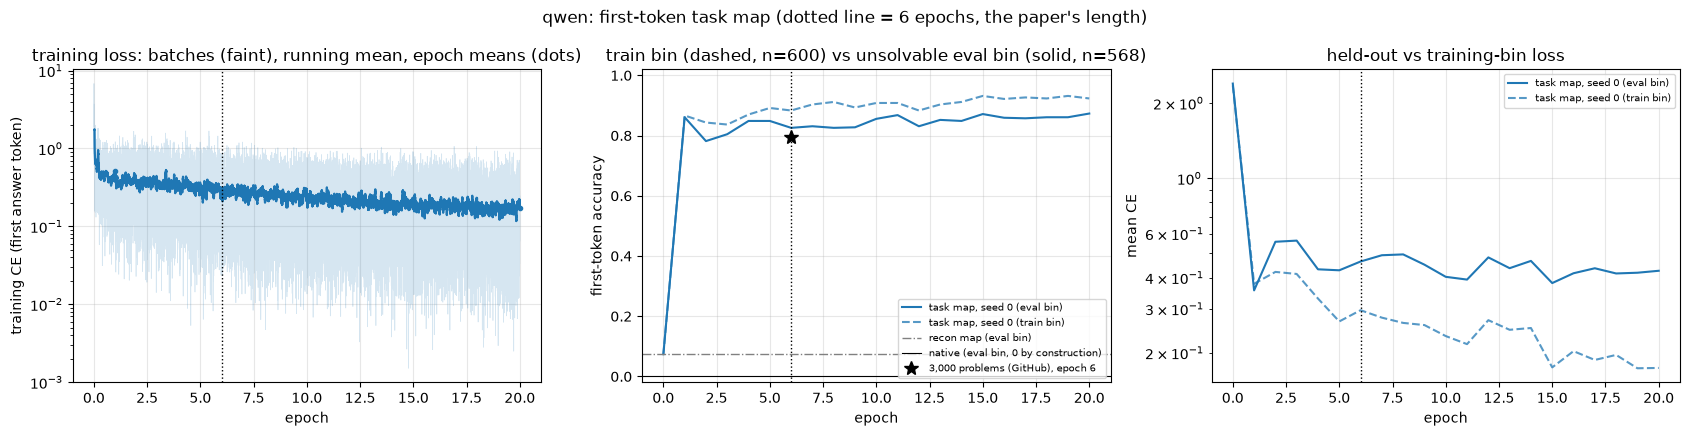

  [plot saved digitk30k_qwen_plots/P0_first_token_loss.png]
  [1223s]
  [saved digitk30k_qwen.json after 0]


In [12]:
# === CELL 9b: PART 0 — the basic first-token stitch (= GitHub EXP2/EXP3, seed 0), with training-loss curves ===
# Replicates the paper's first stitch (Gemma_eval_EXP13-21 / Qwen_eval_EXP13-19, CELLs 8-10): donor state at
# the last prompt position (states_and_top), ridge reconstruction map, task map trained on the FIRST answer
# token (W from ridge, b = recipient mean, Adam 1e-3, batch 16, order random.Random(seed*100 + ep), 6 epochs),
# scored on the unsolvable bin (the recipient's own first token wrong, the donor's right).
# New here: every batch's training loss is recorded, and after each epoch the training-bin accuracy / loss and
# the eval-bin conferral / loss. The seed-0 run then continues to LONG_EPOCHS so a plateau (or not) is visible;
# its epoch-6 snapshot is the replication, checked against GitHub.
t0 = time.time()
P0 = {}; RESULTS["P0_first_token"] = P0
if RUN_FIRST_TOKEN:
    ft_tr = [dict(ctx=p["ids"], tgt=p["tok"]) for p in train]
    ft_ev = [dict(ctx=p["ids"], tgt=p["tok"]) for p in evalp]
    X2t_ft, r_top_tr = states_and_top(model_r, [L_R], [p["ids"] for p in train]); X2t_ft = X2t_ft[L_R]
    X2e_ft, r_top_ev = states_and_top(model_r, [L_R], [p["ids"] for p in evalp]); X2e_ft = X2e_ft[L_R]
    solv_ft = [i for i in range(len(evalp)) if r_top_ev[i] == evalp[i]["tok"]]
    unsolv_ft = [i for i in range(len(evalp)) if r_top_ev[i] != evalp[i]["tok"]]
    trbin_ft = [i for i in range(len(train)) if D_FIRST_TR[i] and r_top_tr[i] != train[i]["tok"]]
    DS["FT"] = dict(tr=ft_tr, ev=ft_ev, IN={"tr": {"FT": X9T_FT}, "ev": {"FT": X9E_FT}}, X2tr=X2t_ft, X2ev=X2e_ft,
                    BIN=unsolv_ft, TRBIN=trbin_ft, TRBIN_MON=_sample(trbin_ft, MONITOR_SAMPLE))
    MAPS["FT"] = {}
    ep_total = LONG_EPOCHS if RUN_LONG and LONG_EPOCHS > TASK_EPOCHS else TASK_EPOCHS
    M = train_map("FT_task_s0", "linear", ft_tr, X9T_FT, X2t_ft, seed=0, epochs=ep_total, monitor=make_monitor("FT", "FT"),
                  snapshot_epochs=(TASK_EPOCHS,) if ep_total > TASK_EPOCHS else ())
    MAPS["FT"]["task_s0"] = (snapshot_map(M, TASK_EPOCHS) if ep_total > TASK_EPOCHS else M, "FT")
    if ep_total > TASK_EPOCHS: MAPS["FT"][f"task_s0_ep{ep_total}"] = (M, "FT")
    for sd in [x for x in FT_SEEDS if x != 0]:
        MAPS["FT"][f"task_s{sd}"] = (train_map(f"FT_task_s{sd}", "linear", ft_tr, X9T_FT, X2t_ft, seed=sd), "FT")
    M6 = MAPS["FT"]["task_s0"][0]
    MAPS["FT"]["recon"] = (dict(W=M6["W0"], b=X2t_ft.float().mean(0).to(DEVICE), mu=M6["mu"], W1=None), "FT")
    def _ft_first(name, idx): return R(conf("FT", name, "ev", idx)[0])
    def _ft_full(name, idx):
        vecs = list(apply_map(MAPS["FT"][name][0], X9E_FT[idx]).cpu()) if name else None
        return R(arith_fullanswer_correct(model_r, L_R, [evalp[j] for j in idx], vecs=vecs))
    P0.update(n_donor_solved=len(evalp), n_unsolvable=len(unsolv_ft), n_solvable=len(solv_ft),
              recon_first_unsolv=_ft_first("recon", unsolv_ft), recon_full_unsolv=_ft_full("recon", unsolv_ft),
              native_full_unsolv=_ft_full(None, unsolv_ft))
    for name in [n for n in MAPS["FT"] if n.startswith("task_")]:
        Mn = MAPS["FT"][name][0]
        P0[name] = {"epochs": len(Mn["ce"]), "first_unsolv": _ft_first(name, unsolv_ft), "full_unsolv": _ft_full(name, unsolv_ft),
                    "first_solv": _ft_first(name, solv_ft), "mean_CE_per_epoch": Mn["ce"], "plateau": plateau_readout(Mn["ce"])}
        _okn = [float(x) for x in conf("FT", name, "ev", unsolv_ft)[0]]
        P0[name]["first_unsolv_by_operand_pair"] = {lab: {"n": len(pos), "rate": rate([_okn[n] for n in pos])} for lab, pos in
                                                    (("held", [n for n, i in enumerate(unsolv_ft) if EV_HELD[i]]),
                                                     ("seen", [n for n, i in enumerate(unsolv_ft) if not EV_HELD[i]]))}
    spe = M["steps_per_epoch"]
    P0["training_loss"] = {"last_batch_CE_at_epoch_6 (= GitHub 'final batch CE')": M["step_loss"][TASK_EPOCHS * spe - 1],
                           "last_batch_size": len(train) - (spe - 1) * BATCH,
                           "mean_CE_per_epoch": M["ce"], "plateau": plateau_readout(M["ce"]),
                           "curve (per epoch: train-bin / eval-bin accuracy and CE)": M["curve"]}
    PER_ITEM["FT/step_loss_seed0"] = M["step_loss"]
    # the rest of GitHub CELL 10: cosine of the written vector to the recipient's own state (all eval problems),
    # and the shuffle control (task map fed another problem's state; GitHub's randperm after torch.manual_seed(4),
    # the last seed its training loop set; the permutation depends on how many eval problems were kept)
    _Mr, _Mt = MAPS["FT"]["recon"][0], MAPS["FT"]["task_s0"][0]
    with torch.no_grad():
        P0["recon_cos_recon"] = round(float(F.cosine_similarity(apply_map(_Mr, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
        P0["recon_cos_task"] = round(float(F.cosine_similarity(apply_map(_Mt, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
    _shuf = torch.randperm(len(evalp), generator=torch.Generator().manual_seed(4))
    _sh_rows = torch.cat([_shuf[i:i + len(unsolv_ft[i:i + BATCH])] for i in range(0, len(unsolv_ft), BATCH)])
    P0["shuffle_first_unsolv"] = R(conf("FT", "task_s0", "ev", unsolv_ft, inp=X9E_FT[_sh_rows])[0])
    print(f"  bins: donor solves {len(evalp)} | recipient natively solves {len(solv_ft)} | unsolvable n={len(unsolv_ft)}")
    print(f"  recon: first {P0['recon_first_unsolv']['ci']} full {P0['recon_full_unsolv']['ci']} | native full {P0['native_full_unsolv']['ci']} | "
          f"shuffle first {P0['shuffle_first_unsolv']['ci']} | recon cosine: recon map {P0['recon_cos_recon']}, task map {P0['recon_cos_task']}")
    for name in [n for n in MAPS["FT"] if n.startswith("task_")]:
        r_ = P0[name]
        print(f"  {name:16s} ({r_['epochs']} epochs): first {r_['first_unsolv']['ci']} | full {r_['full_unsolv']['ci']} | "
              f"solvable-bin first {r_['first_solv']['rate']} | training loss {r_['plateau']['label']}")
    print("  per-epoch (train-bin acc / eval-bin acc / train-bin CE / eval-bin CE): " +
          "  ".join(f"ep{c['epoch']} {c['train_bin']}/{c['eval_bin']}/{c['train_bin_CE']}/{c['eval_bin_CE']}" for c in M["curve"]))
    print("first-token stitch on 30,000 problems (eval-set counts checked; the rest next to the 3,000-problem run and GitHub):")
    F_ = REF["ft"]
    check("FT unsolvable bin n", len(unsolv_ft), F_["n_unsolv"], 2, warn=8)
    info3k("FT task first token (unsolvable)", P0["task_s0"]["first_unsolv"]["rate"], ref3k_get("P0_first_token", "task_s0", "first_unsolv", "rate"), F_["task_first"])
    info3k("FT recon first token (unsolvable)", P0["recon_first_unsolv"]["rate"], ref3k_get("P0_first_token", "recon_first_unsolv", "rate"), F_["recon_first"])
    info3k("FT task full answer (unsolvable; GitHub = 5-seed mean)", P0["task_s0"]["full_unsolv"]["rate"], ref3k_get("P0_first_token", "task_s0", "full_unsolv", "rate"), F_["task_full"])
    info3k("FT recon full answer (unsolvable)", P0["recon_full_unsolv"]["rate"], ref3k_get("P0_first_token", "recon_full_unsolv", "rate"), F_["recon_full"])
    check("FT native full answer (unsolvable)", P0["native_full_unsolv"]["rate"], F_["native_full"], 0.01, warn=0.02)
    info3k("FT task first token (solvable bin)", P0["task_s0"]["first_solv"]["rate"], ref3k_get("P0_first_token", "task_s0", "first_solv", "rate"), F_["task_solv_first"])
    info3k("FT recon cosine, recon map (all eval)", P0["recon_cos_recon"], ref3k_get("P0_first_token", "recon_cos_recon"), F_["recon_cos_recon"])
    info3k("FT recon cosine, task map (all eval)", P0["recon_cos_task"], ref3k_get("P0_first_token", "recon_cos_task"), F_["recon_cos_task"])
    info3k("FT shuffle control first token (unsolvable)", P0["shuffle_first_unsolv"]["rate"], ref3k_get("P0_first_token", "shuffle_first_unsolv", "rate"), F_["shuffle_first"])
    info3k("FT last-batch CE at epoch 6 (one batch; noisy)", P0["training_loss"]["last_batch_CE_at_epoch_6 (= GitHub 'final batch CE')"],
           ref3k_get("P0_first_token", "training_loss", "last_batch_CE_at_epoch_6 (= GitHub 'final batch CE')"), F_["final_batch_ce"])
    _bp0 = P0["task_s0"]["first_unsolv_by_operand_pair"]
    print(f"  first token on the unsolvable bin by operand pair: held {_bp0['held']} | seen {_bp0['seen']}")
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
    plot_run(M, "task map, seed 0", ax[0], ax[1], ax[2], raw=True, color=_PALETTE["task"])
    ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training CE (first answer token)")
    ax[0].set_title("training loss: batches (faint), running mean, epoch means (dots)")
    ax[1].axhline(P0["recon_first_unsolv"]["rate"], c="grey", ls="-.", lw=1, label="recon map (eval bin)")
    ax[1].axhline(0.0, c="k", lw=0.8, label="native (eval bin, 0 by construction)")
    ax[1].plot([TASK_EPOCHS], [REF["ft"]["task_first"]], "k*", ms=10, label="3,000 problems (GitHub), epoch 6")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("first-token accuracy"); ax[1].set_ylim(-0.02, 1.02)
    ax[1].set_title(f"train bin (dashed, n={len(DS['FT']['TRBIN_MON'])}) vs unsolvable eval bin (solid, n={len(unsolv_ft)})")
    ax[1].legend(fontsize=7, loc="lower right")
    ax[2].set_xlabel("epoch"); ax[2].set_ylabel("mean CE"); ax[2].set_yscale("log"); ax[2].legend(fontsize=7)
    ax[2].set_title("held-out vs training-bin loss")
    _finish(fig, ax, os.path.join(PLOT_DIR, "P0_first_token_loss.png"),
            f"{PAIR}: first-token task map (dotted line = {TASK_EPOCHS} epochs, the paper's length)")
fast_cache_clear()
print(f"  [{time.time()-t0:.0f}s]"); save("0")

In [13]:
# === CELL 10: PART P — was digit k (or an intermediate) computed at each source? (+ S2 sanity) ===
# Held-out probes, fit on ALL training items (gold labels), scored per item on the EVAL BIN.
# Baselines a probe must beat:
#   majority      the most common label in training
#   prefix        the most common label given the answer length and digits 1..k-1 (the recipient sees these)
#   recipient     the same probes on the RECIPIENT's own graft-site state (also reported on all eval items,
#                 since the bin is selected for recipient failure)
# Labels (paired bootstrap of the best probe vs the best baseline, per item):
#   PRESENT if the lower bound > SESOI; absent if the upper bound < SESOI; otherwise weak/uncertain.
# Also:
#   +prefix       a probe on [state, prefix one-hot] against the prefix lookup: beyond what the recipient has
#   intermediate  a·b's digit at digit k's place value: is there a partial result to transfer?
#   logit lens    DEEP_PRED through the donor's own unembedding: the decodability ceiling
t0 = time.time()
P = {}
if S2_STATES is not None:
    ev3 = DS[3]["ev"]; t3 = S2_STATES["items"]
    y = torch.tensor([[int(c) for c in ev3[i]["astr"]] for i in t3]); h = len(t3) // 2
    print("SANITY (Emergence S2: 3-digit eval answers in S2's own batches, first half -> second half, linear probe):")
    check("S2 n items", len(t3), REF["s2_n"], 0, warn=3)
    if not SMOKE_TEST: check("S2 sweep layers", float(SWEEP == sorted(REF["s2"])), 1.0, 0)
    P["S2_reproduction"] = {}
    for L in SWEEP:
        X = S2_STATES["X"][L].float()                                   # [n, 3 positions, d]
        g = {"prefill_d2": digit_probe(X[:h, 0], y[:h, 1], X[h:, 0], y[h:, 1]),
             "diag_d2": digit_probe(X[:h, 1], y[:h, 1], X[h:, 1], y[h:, 1]),
             "diag_d3": digit_probe(X[:h, 2], y[:h, 2], X[h:, 2], y[h:, 2])}
        P["S2_reproduction"][f"layer_{L}"] = g
        if L in REF["s2"]:
            for key, v in g.items(): check(f"S2 layer {L} {key}", v, REF["s2"][L][key], 0.02, warn=0.04)

# Which probe kind (linear / MLP) and which baseline is "best" is chosen on eval items OUTSIDE the bin
# (held out from training too), then tested on the bin, so the choice does not peek at the test items.
def _sel(k):
    D = DS[k]; bs = set(D["BIN"]); nb = [i for i in range(len(D["ev"])) if i not in bs]
    return nb if len(nb) >= 30 else D["BIN"]
def _lookup_vec(k, key_fn, field="dk", idx=None):
    tab = collections.defaultdict(collections.Counter)
    for it in DS[k]["tr"]: tab[key_fn(it)][it[field]] += 1
    maj = collections.Counter(it[field] for it in DS[k]["tr"]).most_common(1)[0][0]
    idx = DS[k]["BIN"] if idx is None else idx
    return [float((tab[key_fn(it)].most_common(1)[0][0] if tab[key_fn(it)] else maj) == it[field])
            for it in (DS[k]["ev"][i] for i in idx)]
def _probe_vecs(k, Xtr, Xev, field="dk"):
    """Linear + MLP probe: per-item correctness on the eval bin and on the selection items, rates on all eval."""
    D = DS[k]; ytr = labels(k, "tr", field=field); yev = labels(k, "ev", field=field); B = D["BIN"]; SL = _sel(k)
    pl = lin_probe_logits(lin_probe_fit(Xtr, ytr), Xev).argmax(1); pm = mlp_probe_logits(mlp_probe_fit(Xtr, ytr), Xev).argmax(1)
    return {"lin": [float(x) for x in (pl[B] == yev[B]).tolist()], "mlp": [float(x) for x in (pm[B] == yev[B]).tolist()],
            "lin_sel": rate((pl[SL] == yev[SL]).tolist()), "mlp_sel": rate((pm[SL] == yev[SL]).tolist()),
            "lin_all_eval": rate((pl == yev).tolist()), "mlp_all_eval": rate((pm == yev).tolist())}
def presence_label(p):
    if p["lo"] is None: return "n/a"
    if p["lo"] > SESOI: return "PRESENT"
    if p["hi"] < SESOI: return "absent (gain over baseline < SESOI)"
    return "weak / uncertain"
def _with_prefix(k, X, split, s):
    return torch.cat([X.float(), s * DS[k]["IN"][split]["PREFIX"]], 1)
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; out = {"digit_k": {}, "intermediate_product_digit": {}, "depth_sweep": {}}
    for field, tgt_key in (("dk", "digit_k"), ("pdig", "intermediate_product_digit")):
        SL = _sel(k)
        lk = {"majority": lambda it: 0, "prefix_lookup": lambda it: (len(it["astr"]), it["prefix"])}
        base = {n: _lookup_vec(k, f, field) for n, f in lk.items()}
        base_sel = {n: rate(_lookup_vec(k, f, field, SL)) for n, f in lk.items()}
        rv = _probe_vecs(k, D["X2tr"], D["X2ev"], field)
        base["recipient_linear"], base["recipient_mlp"] = rv["lin"], rv["mlp"]
        base_sel["recipient_linear"], base_sel["recipient_mlp"] = rv["lin_sel"], rv["mlp_sel"]
        bb = max(base, key=lambda n: base_sel[n])
        res = {"baselines": {n: rate(v) for n, v in base.items()}, "best_baseline": bb, "best_baseline_rate_on_bin": rate(base[bb]),
               "recipient_all_eval": {"lin": rv["lin_all_eval"], "mlp": rv["mlp_all_eval"]}, "sources": {}}
        res["baselines_by_operand_pair"] = {n_: by_pair(k, v_) for n_, v_ in base.items()}
        if field == "dk":
            sc2 = float(D["X2tr"].float().std(0).mean())
            rvp = _probe_vecs(k, _with_prefix(k, D["X2tr"], "tr", sc2), _with_prefix(k, D["X2ev"], "ev", sc2), field)
            pbase = {"prefix_lookup": base["prefix_lookup"], "recipient_linear+prefix": rvp["lin"], "recipient_mlp+prefix": rvp["mlp"]}
            pbase_sel = {"prefix_lookup": base_sel["prefix_lookup"], "recipient_linear+prefix": rvp["lin_sel"], "recipient_mlp+prefix": rvp["mlp_sel"]}
            pbb = max(pbase, key=lambda n: pbase_sel[n])
        for s in SRC:
            v = _probe_vecs(k, D["IN"]["tr"][s], D["IN"]["ev"][s], field)
            best = "lin" if v["lin_sel"] >= v["mlp_sel"] else "mlp"
            p = paired(base[bb], v[best])
            res["sources"][s] = {"lin": rate(v["lin"]), "mlp": rate(v["mlp"]), "lin_all_eval": v["lin_all_eval"],
                                 "mlp_all_eval": v["mlp_all_eval"], "best": best, "minus_best_baseline": p, "label": presence_label(p)}
            res["sources"][s]["by_operand_pair"] = {"lin": by_pair(k, v["lin"]), "mlp": by_pair(k, v["mlp"]),
                                                    "best_minus_best_baseline": by_pair(k, base[bb], v[best])}
            if field == "dk" and s in ("PREFILL", "PREFILL_SP", "MID_PRED"):            # extra: an MLP probe trained longer
                _pl = mlp_probe_logits(mlp_probe_fit(D["IN"]["tr"][s], labels(k, "tr"), steps=PROBE_MLP_STEPS_LONG), D["IN"]["ev"][s]).argmax(1)
                _vl = [float(x) for x in (_pl[B] == labels(k, "ev")[B]).tolist()]
                res["sources"][s]["mlp_long_extra"] = {"steps": PROBE_MLP_STEPS_LONG, "rate": rate(_vl), "by_operand_pair": by_pair(k, _vl),
                                                       "minus_best_baseline": paired(base[bb], _vl)}
            if field == "dk" and s in ("PREFILL", "MID_PRED"):
                sc = float(D["IN"]["tr"][s].float().std(0).mean())
                vp = _probe_vecs(k, _with_prefix(k, D["IN"]["tr"][s], "tr", sc), _with_prefix(k, D["IN"]["ev"][s], "ev", sc), field)
                bp_ = "lin" if vp["lin_sel"] >= vp["mlp_sel"] else "mlp"
                pp = paired(pbase[pbb], vp[bp_])
                res["sources"][s]["with_prefix"] = {"lin": rate(vp["lin"]), "mlp": rate(vp["mlp"]), "baseline": pbb,
                                                    "baseline_rate": rate(pbase[pbb]), "minus_baseline": pp, "label": presence_label(pp)}
        if field == "dk":
            ll = (D["IN"]["ev"]["DEEP_PRED"][B].float() @ WU_DIG.T).argmax(1)
            res["logit_lens_DEEP_PRED"] = rate((ll == labels(k, "ev", B)).tolist())
            ceil = max(res["logit_lens_DEEP_PRED"], res["sources"]["DEEP_PRED"]["lin"], res["sources"]["DEEP_PRED"]["mlp"])
            bbr = float(np.mean(base[bb]))
            for s, r in res["sources"].items():
                r["normalised_presence"] = round((max(r["lin"], r["mlp"]) - bbr) / (ceil - bbr), 3) if ceil - bbr > 0.02 else None
        out[tgt_key] = res
    for pk in ("eq", "sp", "pred"):
        for L in SWEEP:
            v = _probe_vecs(k, D["Str"][(pk, L)], D["Sev"][(pk, L)])
            out["depth_sweep"][f"{pk}@L{L}"] = {"lin": rate(v["lin"]), "mlp": rate(v["mlp"])}
    P[f"d{k}"] = out
    dk_, pd_ = out["digit_k"], out["intermediate_product_digit"]
    print(f"\n  DIGIT {k} (eval bin n={len(B)}) — digit-{k} baselines {dk_['baselines']} | logit lens DEEP_PRED {dk_['logit_lens_DEEP_PRED']}")
    for s, r in dk_["sources"].items():
        extra = f" | +prefix {r['with_prefix']['lin']}/{r['with_prefix']['mlp']} -> {r['with_prefix']['label']}" if "with_prefix" in r else ""
        print(f"     {s:13s} ({SRC_NOTE[s]:52s}) lin {r['lin']} mlp {r['mlp']} | minus best baseline "
              f"{r['minus_best_baseline']['ci']} -> {r['label']} | normalised {r['normalised_presence']}{extra}")
    for s in [s_ for s_ in ("PREFILL", "PREFILL_SP", "MID_PRED") if s_ in dk_["sources"]]:
        r = dk_["sources"][s]; bp_ = r["by_operand_pair"]
        print(f"     {s:13s} held operand pairs: lin {bp_['lin']['held']['rate']} mlp {bp_['mlp']['held']['rate']} (best minus baseline "
              f"{bp_['best_minus_best_baseline']['held']['ci']}) | seen: lin {bp_['lin']['seen']['rate']} mlp {bp_['mlp']['seen']['rate']}"
              + (f" | MLP probe x{PROBE_MLP_STEPS_LONG} steps {r['mlp_long_extra']['rate']} (held {r['mlp_long_extra']['by_operand_pair']['held']['rate']})"
                 if "mlp_long_extra" in r else ""))
    print(f"     intermediate (a*b digit) baselines {pd_['baselines']}: " +
          " | ".join(f"{s} {r['lin']}/{r['mlp']} -> {r['label']}" for s, r in pd_["sources"].items()))
    print("     depth sweep (lin/mlp): " + "  ".join(f"{kk} {v['lin']}/{v['mlp']}" for kk, v in out["depth_sweep"].items()))
RESULTS["P_presence"] = P
print(f"  [{time.time()-t0:.0f}s]"); save("P")

SANITY (Emergence S2: 3-digit eval answers in S2's own batches, first half -> second half, linear probe):
  PASS  S2 n items                                           github 1379   this run 1379
  PASS  S2 sweep layers                                      github 1.0   this run 1.0
  PASS  S2 layer 23 prefill_d2                               github 0.157   this run 0.157
  PASS  S2 layer 23 diag_d2                                  github 0.171   this run 0.171
  PASS  S2 layer 23 diag_d3                                  github 0.335   this run 0.335
  PASS  S2 layer 25 prefill_d2                               github 0.204   this run 0.204
  PASS  S2 layer 25 diag_d2                                  github 0.233   this run 0.233
  PASS  S2 layer 25 diag_d3                                  github 0.546   this run 0.546
  PASS  S2 layer 27 prefill_d2                               github 0.228   this run 0.228
  PASS  S2 layer 27 diag_d2                                  github 0.394   this 

In [14]:
# === CELL 11: PART T — train every map (S4's three first, then the S4 sanity check, then the rest) ===
t0 = time.time()
_NULLS.clear(); _TNULL.clear()
def _plan(k):
    plan = [("PREFILL", "linear", "PREFILL", 0, True), ("DEEP_PRED", "linear", "DEEP_PRED", 0, False),
            ("PRESENT", "linear", "PRESENT", 0, True), ("CONST", "const", "PREFILL", 0, True),
            ("PREFIX", "writer", "PREFIX", 0, True), ("MID_PRED", "linear", "MID_PRED", 0, True)]
    if RUN_EXTRA_SEED: plan += [("PREFILL_s1", "linear", "PREFILL", 1, False), ("MID_PRED_s1", "linear", "MID_PRED", 1, False)]
    if "MID_PRED_MID" in SRC: plan.append(("MID_PRED_MID", "linear", "MID_PRED_MID", 0, False))
    plan += [("PRODUCT", "writer", "PRODUCT", 0, False), ("GOLD", "writer", "GOLD", 0, False),
             ("PREFILL_PFX", "linear", "PREFILL_PFX", 0, False), ("MID_PRED_PFX", "linear", "MID_PRED_PFX", 0, False)]
    if "MID_PRED_MID" in SRC: plan.append(("MID_PRED_MID_PFX", "linear", "MID_PRED_MID_PFX", 0, False))
    if RUN_MLP_MAP: plan += [("PREFILL_MLP", "mlp", "PREFILL", 0, False), ("MID_PRED_MLP", "mlp", "MID_PRED", 0, False)]
    return plan
for k in K_LIST:
    D = DS[k]; D["TRBIN_MON"] = _sample(D["TRBIN"], MONITOR_SAMPLE)
    for split in ("tr", "ev"):
        items = D[split]
        D["IN"][split]["PRODUCT"] = torch.cat([digit_onehot([str(it["abc"][0] * it["abc"][1]).zfill(4) for it in items], 4),
                                               D["IN"][split]["PREFIX"]], 1)
        D["IN"][split]["GOLD"] = torch.cat([digit_onehot([[it["dk"]] for it in items], 1), D["IN"][split]["PREFIX"]], 1)
    for base in [b_ for b_ in ("PREFILL", "MID_PRED", "MID_PRED_MID") if b_ in SRC]:
        D["PFX_SCALE"][base] = float(D["IN"]["tr"][base].float().std(0).mean())   # puts the one-hots on the state's scale
        for split in ("tr", "ev"):
            D["IN"][split][base + "_PFX"] = torch.cat([D["IN"][split][base].float(),
                                                       D["PFX_SCALE"][base] * D["IN"][split]["PREFIX"]], 1)
    plan = _plan(k)
    print(f"\n  DIGIT {k}: training {[p[0] for p in plan]}")
    for name, kind, src, seed, mon in plan:
        kd, lam = ("linear", WRITER_LAMBDA) if kind == "writer" else (kind, RIDGE_LAMBDA)
        long_ = RUN_LONG and name in LONG_MAPS and LONG_EPOCHS > TASK_EPOCHS
        M = train_map(f"d{k}_{name}", kd, D["tr"], D["IN"]["tr"][src], D["X2tr"], seed=seed,
                      monitor=make_monitor(k, src) if mon else None, lam=lam,
                      epochs=LONG_EPOCHS if long_ else None, snapshot_epochs=(TASK_EPOCHS,) if long_ else ())
        if long_:                               # the epoch-6 snapshot is the map every other part uses
            MAPS[k][name] = (snapshot_map(M, TASK_EPOCHS), src); MAPS[k][f"{name}_ep{LONG_EPOCHS}"] = (M, src)
        else:
            MAPS[k][name] = (M, src)
        if k == 2 and name == "PRESENT":
            print("  digit-2 conferral on S4's population (depends on the training set: next to the 3,000-problem run and GitHub):")
            F4 = D["S4FAIL"]; s4 = {}
            for nm, key in (("A", "PREFILL"), ("B", "DEEP_PRED"), ("C", "PRESENT")):
                s4[nm] = rate(conf(2, key, "ev", F4)[0])
            order = list(F4); random.Random(0).shuffle(order)                  # = S4's shuffle (not a derangement)
            s4["C_shuffle"] = rate(conf(2, "PRESENT", "ev", F4, inp=D["IN"]["ev"]["PRESENT"][order])[0])
            for nm in ("A", "B", "C", "C_shuffle"):
                info3k(f"S4 {nm} digit-2 conferral", s4[nm], ref3k_get("S4_reproduction", nm), REF["s4"][nm])
            RESULTS["S4_reproduction"] = s4; save("S4 check")
    save(f"trained d{k}")
if 2 in K_LIST and RUN_EXTRA_SEED:
    RESULTS["S4_reproduction"]["A_seed1_same_population"] = rate(conf(2, "PREFILL_s1", "ev", DS[2]["S4FAIL"])[0])
    print(f"  training-order noise yardstick: PREFILL seed 0 {RESULTS['S4_reproduction']['A']} vs seed 1 "
          f"{RESULTS['S4_reproduction']['A_seed1_same_population']} on S4's population")
RESULTS["adam_steps"] = {f"d{k}/{n}": MAPS[k][n][0]["steps"] for k in K_LIST for n in MAPS[k]}
fast_cache_clear()
print(f"  [{time.time()-t0:.0f}s]"); save("T")


  DIGIT 2: training ['PREFILL', 'DEEP_PRED', 'PRESENT', 'CONST', 'PREFIX', 'MID_PRED', 'PREFILL_s1', 'MID_PRED_s1', 'MID_PRED_MID', 'PRODUCT', 'GOLD', 'PREFILL_PFX', 'MID_PRED_PFX', 'MID_PRED_MID_PFX', 'PREFILL_MLP', 'MID_PRED_MLP']
    [fast path] cached layer-17 outputs for 29997 contexts (4.0 GB on cuda)  [48s]
    d2_PREFILL epoch 1: mean CE 2.348 | {'epoch': 1, 'train_bin': 0.2233, 'eval_bin': 0.1423, 'train_bin_CE': 2.2104, 'eval_bin_CE': 2.4461}
    d2_PREFILL epoch 2: mean CE 2.191 | {'epoch': 2, 'train_bin': 0.2567, 'eval_bin': 0.205, 'train_bin_CE': 2.0262, 'eval_bin_CE': 2.344}
    d2_PREFILL epoch 3: mean CE 2.119 | {'epoch': 3, 'train_bin': 0.27, 'eval_bin': 0.1987, 'train_bin_CE': 1.9928, 'eval_bin_CE': 2.2585}
    d2_PREFILL epoch 4: mean CE 2.08 | {'epoch': 4, 'train_bin': 0.3167, 'eval_bin': 0.1736, 'train_bin_CE': 1.9275, 'eval_bin_CE': 2.3506}
    d2_PREFILL epoch 5: mean CE 2.009 | {'epoch': 5, 'train_bin': 0.3383, 'eval_bin': 0.2238, 'train_bin_CE': 1.8864, 'eval_

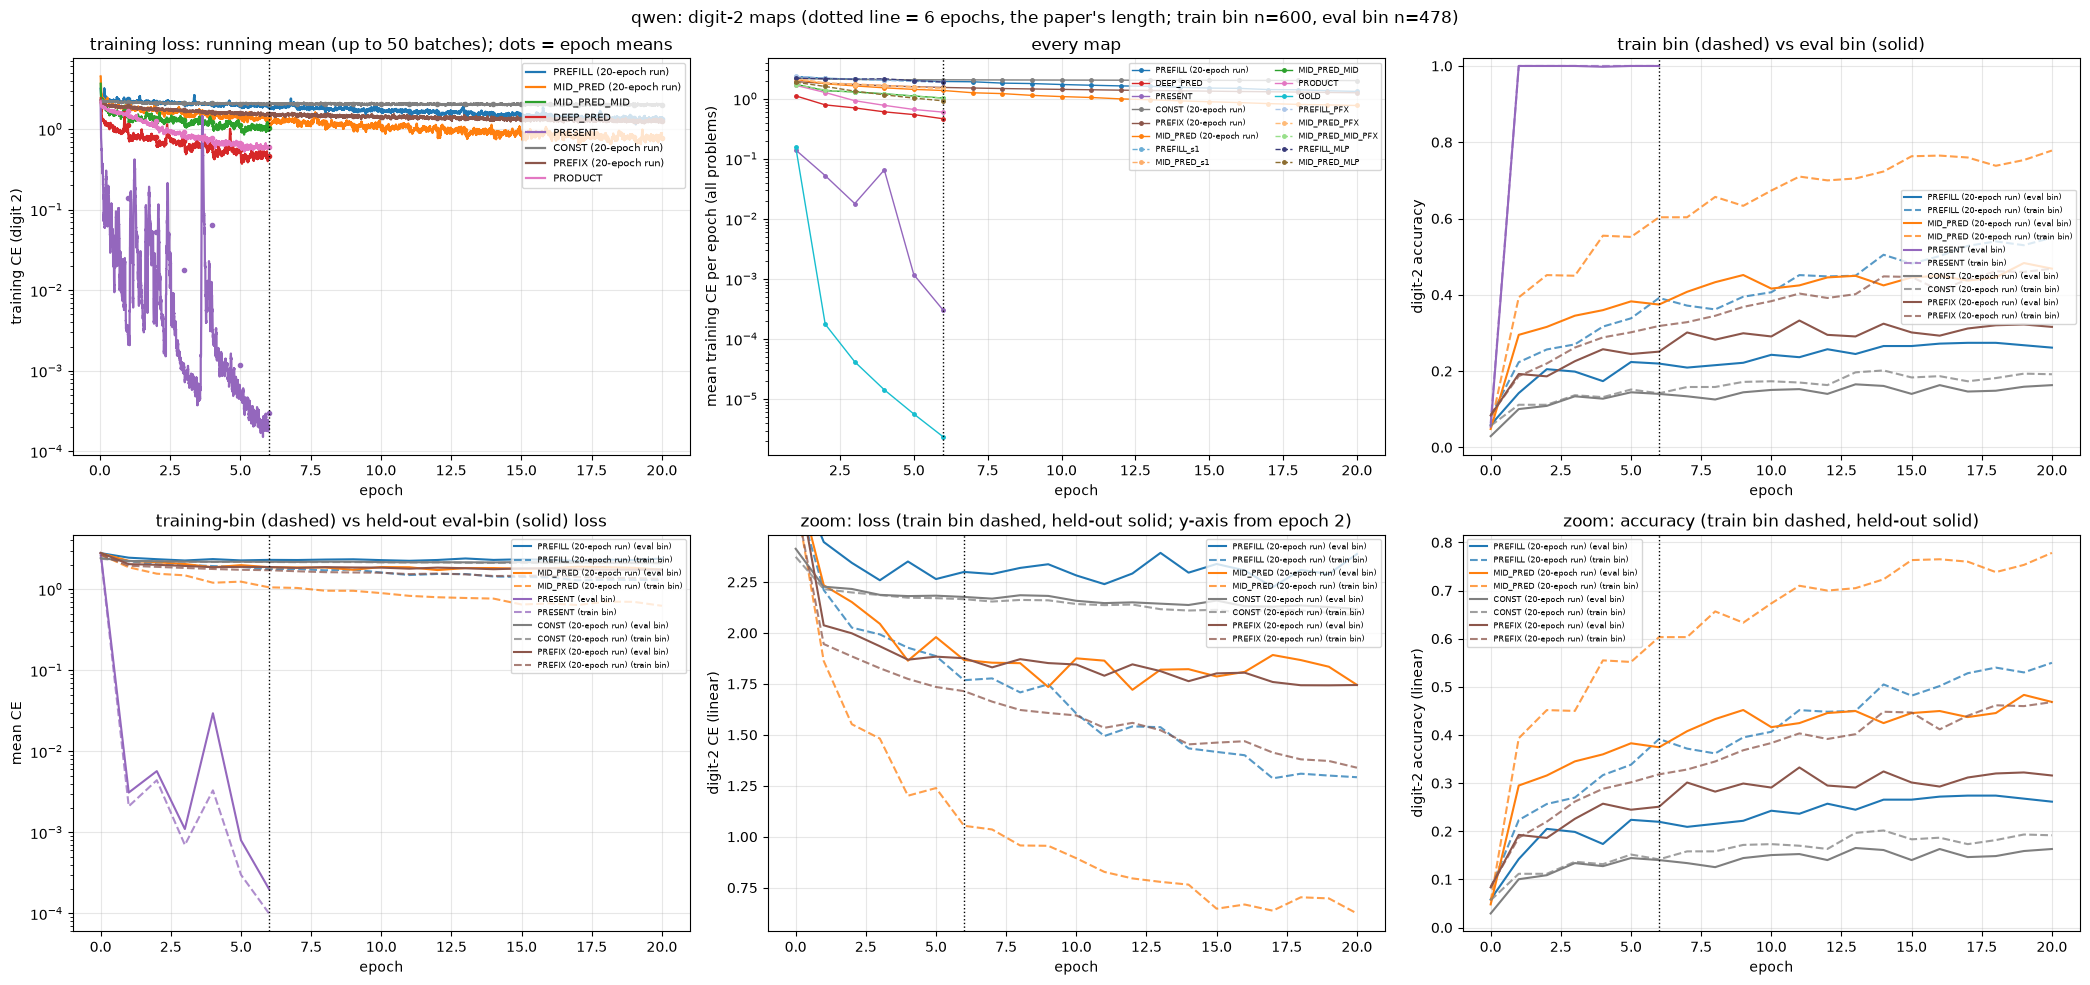

  [plot saved digitk30k_qwen_plots/PL_digit2_loss.png]

  DIGIT 2 — loss per epoch and plateau read-out (training-bin CE where monitored):
     PREFILL (20-epoch run)     [training-bin CE] [2.2104, 2.0262, 1.9928, 1.9275, 1.8864, 1.7682, 1.777, 1.7083, 1.748, 1.6047, 1.4942, 1.5413, 1.5376, 1.4336, 1.4163, 1.4, 1.2866, 1.3094, 1.3002, 1.2921] -> flattening (-0% over the last 3 epochs) (log-slope 0.0014, share of drop in last 3 epochs -0.006)
     DEEP_PRED                  [all-problem mean CE] [1.118, 0.7908, 0.7043, 0.6058, 0.5451, 0.4641] -> still falling (34% over the last 3 epochs) (log-slope -0.139, share of drop in last 3 epochs 0.367)
     PRESENT                    [training-bin CE] [0.0021, 0.0044, 0.0007, 0.0033, 0.0003, 0.0001] -> at ~0 (CE 0.0001 < 0.01: fits these problems) (log-slope -0.6486, share of drop in last 3 epochs 0.3)
     CONST (20-epoch run)       [training-bin CE] [2.2153, 2.1986, 2.1858, 2.1728, 2.1707, 2.1657, 2.1541, 2.1619, 2.1601, 2.1419, 2.1364, 2.1393

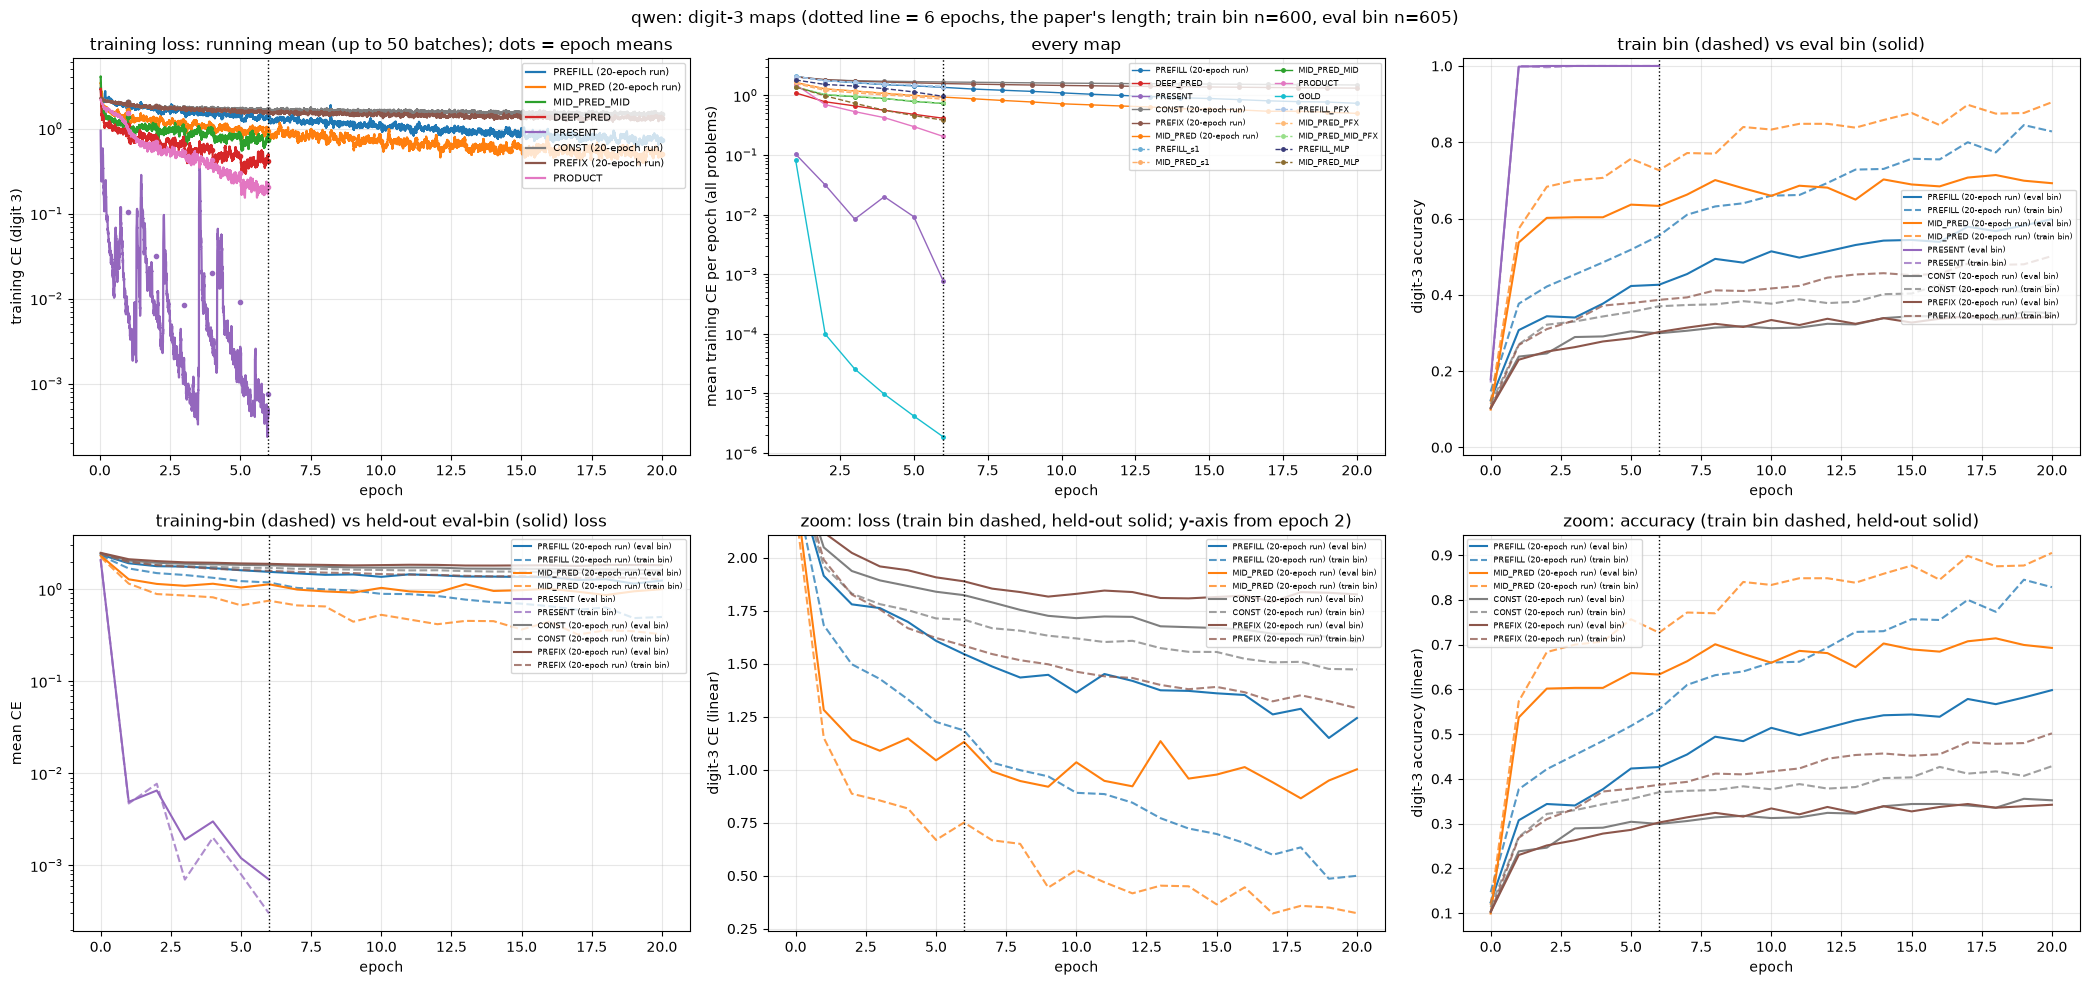

  [plot saved digitk30k_qwen_plots/PL_digit3_loss.png]

  DIGIT 3 — loss per epoch and plateau read-out (training-bin CE where monitored):
     PREFILL (20-epoch run)     [training-bin CE] [1.6816, 1.4971, 1.428, 1.3318, 1.2253, 1.1848, 1.0331, 0.9977, 0.9684, 0.8909, 0.885, 0.8444, 0.7714, 0.7226, 0.6968, 0.6537, 0.5987, 0.6337, 0.4858, 0.4996] -> still falling (17% over the last 3 epochs) (log-slope -0.0603, share of drop in last 3 epochs 0.084)
     DEEP_PRED                  [all-problem mean CE] [1.096, 0.7794, 0.6645, 0.5612, 0.4808, 0.4123] -> still falling (38% over the last 3 epochs) (log-slope -0.1591, share of drop in last 3 epochs 0.369)
     PRESENT                    [training-bin CE] [0.0047, 0.0077, 0.0007, 0.002, 0.0008, 0.0003] -> at ~0 (CE 0.0003 < 0.01: fits these problems) (log-slope -0.2824, share of drop in last 3 epochs 0.091)
     CONST (20-epoch run)       [training-bin CE] [1.9604, 1.8308, 1.7807, 1.7526, 1.7134, 1.7073, 1.6672, 1.6556, 1.6319, 1.619, 1.6021,

In [15]:
# === CELL 11b: PART L — training-loss curves for every digit-k map, and the plateau read-out ===
# Per digit (2 x 3 panels): (a) training loss per batch (running mean) and per epoch (dots), log scale, the main
# maps; (b) per-epoch mean training CE for every map; (c) accuracy per epoch on the training bin (dashed) and the
# eval bin (solid); (d) the same as mean CE; (e) and (f) LINEAR-scale zoom on the four maps that matter here
# (PREFILL, MID_PRED and the nulls CONST, PREFIX), side by side: loss and accuracy, each on the training bin
# (dashed) and the held-out eval bin (solid). Loss falling while accuracy stays flat = the map grows more
# confident without getting more problems right; training loss falling while held-out loss rises = memorising;
# held-out loss below the nulls' with flat accuracy = some digit-k information arriving below the argmax. PREFILL, MID_PRED, CONST
# and PREFIX run to LONG_EPOCHS ("20-epoch run"); their first 6 epochs ARE the 6-epoch maps used everywhere else.
# Plateau read-out (on the training-BIN CE, the hard problems, where the monitor has it; otherwise the all-problem
# mean): still falling / rising / flattening / at ~0, with the log-slope and the share of the whole drop in the
# last 3 epochs ("flattening" is not a proof of a plateau).
# Long runs vs the nulls, at epoch 6 and at LONG_EPOCHS: training-bin and eval-bin conferral and CE minus each null
# (CONST, PREFIX); the reference null is the stronger one ON THE TRAINING BIN (chosen away from the eval items).
# Mechanical label as in Part 1: fit and generalised / memorised / did not fit beyond the null. Descriptive:
# one seed, uncorrected. More epochs test the optimiser, not the capacity of a linear map.
t0 = time.time()
PL = {}; RESULTS["PL_loss_curves"] = PL
MAIN_PLOT = ["PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT", "CONST", "PREFIX", "PRODUCT"]
ZOOM = ["PREFILL", "MID_PRED", "CONST", "PREFIX"]
def _lab(n): return re.sub(r"_ep(\d+)$", r" (\1-epoch run)", n)
def _fit_label(tr, ev):
    tr_low = tr["hi"] is not None and tr["hi"] < SESOI
    if above(tr) and above(ev): return "fit training and generalised above the null"
    if above(tr): return "MEMORISED: training bin above the null, eval bin not"
    if tr_low and above(ev): return "did not fit training beyond the null, yet above it on eval (check)"
    if tr_low: return "did not fit its training problems beyond the null"
    return "inconclusive"
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; PL[f"d{k}"] = {"maps": {}, "long_vs_null": {}}
    lng = lambda n: f"{n}_ep{LONG_EPOCHS}" if f"{n}_ep{LONG_EPOCHS}" in MAPS[k] else n
    for name, (M, _) in MAPS[k].items():
        tb = [c.get("train_bin_CE") for c in (M.get("curve") or [])[1:]]
        PL[f"d{k}"]["maps"][name] = {"mean_CE_per_epoch (all training problems)": M["ce"],
                                     "train_bin_CE_per_epoch": tb if any(x is not None for x in tb) else None,
                                     "plateau": plateau_readout(tb if any(x is not None for x in tb) else M["ce"]),
                                     "plateau_on": "training-bin CE" if any(x is not None for x in tb) else "all-problem mean CE",
                                     "last_batch_CE": (M["step_loss"][-1] if M.get("step_loss") else None)}
        if not M.get("snapshot_of_epoch"): PER_ITEM[f"d{k}/{name}/step_loss"] = M.get("step_loss")
    fig, ax = plt.subplots(2, 3, figsize=(21, 10)); ax = ax.ravel()
    for n in [n for n in MAIN_PLOT if n in MAPS[k]]:
        plot_run(MAPS[k][lng(n)][0], _lab(lng(n)), ax[0], color=_color_for(n))
    for n, (M, _) in MAPS[k].items():
        if M.get("snapshot_of_epoch") or not M.get("ce"): continue
        ax[1].plot(np.arange(1, len(M["ce"]) + 1), M["ce"], marker="o", ms=2.5, lw=1, label=_lab(n), color=_color_for(n),
                   ls="--" if n.endswith(("_s1", "_MLP", "_PFX")) else "-")
    for n in [n for n in ("PREFILL", "MID_PRED", "PRESENT", "CONST", "PREFIX") if n in MAPS[k]]:
        Mn = MAPS[k][lng(n)][0]
        if Mn.get("curve"): plot_run({"curve": Mn["curve"]}, _lab(lng(n)), ax[0], ax[2], ax[3], color=_color_for(n))
    _zv = []                                            # loss values from epoch 2 on, to fit the zoom's y-axis
    for n in [n for n in ZOOM if n in MAPS[k]]:
        cv = MAPS[k][lng(n)][0].get("curve") or []
        if cv:
            _zv += [c[key] for c in cv if c["epoch"] >= 2 for key in ("eval_bin_CE", "train_bin_CE") if c.get(key) is not None]
            e = [c["epoch"] for c in cv]
            ax[4].plot(e, [c["eval_bin_CE"] for c in cv], "-", color=_color_for(n), label=f"{_lab(lng(n))} (eval bin)")
            ax[4].plot(e, [c["train_bin_CE"] for c in cv], "--", color=_color_for(n), alpha=0.75, label=f"{_lab(lng(n))} (train bin)")
            ax[5].plot(e, [c["eval_bin"] for c in cv], "-", color=_color_for(n), label=f"{_lab(lng(n))} (eval bin)")
            ax[5].plot(e, [c["train_bin"] for c in cv], "--", color=_color_for(n), alpha=0.75, label=f"{_lab(lng(n))} (train bin)")
    ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel(f"training CE (digit {k})"); ax[0].legend(fontsize=7, loc="upper right")
    ax[0].set_title("training loss: running mean (up to 50 batches); dots = epoch means")
    ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean training CE per epoch (all problems)")
    ax[1].legend(fontsize=6, ncol=2, loc="upper right"); ax[1].set_title("every map")
    ax[2].set_xlabel("epoch"); ax[2].set_ylabel(f"digit-{k} accuracy"); ax[2].set_ylim(-0.02, 1.02)
    ax[2].legend(fontsize=6, loc="center right"); ax[2].set_title("train bin (dashed) vs eval bin (solid)")
    ax[3].set_xlabel("epoch"); ax[3].set_ylabel("mean CE"); ax[3].set_yscale("log"); ax[3].legend(fontsize=6, loc="upper right")
    ax[3].set_title("training-bin (dashed) vs held-out eval-bin (solid) loss")
    ax[4].set_xlabel("epoch"); ax[4].set_ylabel(f"digit-{k} CE (linear)"); ax[4].legend(fontsize=6, loc="upper right")
    ax[4].set_title("zoom: loss (train bin dashed, held-out solid; y-axis from epoch 2)")
    if _zv:
        _pad = 0.05 * (max(_zv) - min(_zv) + 1e-9); ax[4].set_ylim(min(_zv) - _pad, max(_zv) + _pad)
    ax[5].set_xlabel("epoch"); ax[5].set_ylabel(f"digit-{k} accuracy (linear)"); ax[5].legend(fontsize=6, loc="upper left")
    ax[5].set_title("zoom: accuracy (train bin dashed, held-out solid)")
    _finish(fig, ax, os.path.join(PLOT_DIR, f"PL_digit{k}_loss.png"),
            f"{PAIR}: digit-{k} maps (dotted line = {TASK_EPOCHS} epochs, the paper's length; train bin n={len(D['TRBIN_MON'])}, eval bin n={len(B)})")
    # long runs vs the nulls at epoch 6 and at LONG_EPOCHS
    for n in [n for n in ("PREFILL", "MID_PRED") if f"{n}_ep{LONG_EPOCHS}" in MAPS[k]]:
        row = {}
        for tag, nm, nulls in ((f"epoch_{TASK_EPOCHS}", n, ("CONST", "PREFIX")),
                               (f"epoch_{LONG_EPOCHS}", f"{n}_ep{LONG_EPOCHS}", (f"CONST_ep{LONG_EPOCHS}", f"PREFIX_ep{LONG_EPOCHS}"))):
            nulls = [nu for nu in nulls if nu in MAPS[k]]
            m_tr, _, m_trce = conf(k, nm, "tr", D["TRBIN"], want_ce=True); m_ev, _, m_evce = conf(k, nm, "ev", B, want_ce=True)
            nv = {nu: (conf(k, nu, "tr", D["TRBIN"], want_ce=True), conf(k, nu, "ev", B, want_ce=True)) for nu in nulls}
            st = max(nv, key=lambda nu: np.mean(nv[nu][0][0]))             # stronger null ON THE TRAINING BIN
            per_null = {}
            for nu, ((t_ok, _, t_ce), (e_ok, _, e_ce)) in nv.items():
                per_null[nu] = {"train_bin_minus_null": paired([float(x) for x in t_ok], [float(x) for x in m_tr]),
                                "eval_bin_minus_null": paired([float(x) for x in e_ok], [float(x) for x in m_ev]),
                                "train_bin_CE_map_minus_null": round(float(np.mean(m_trce) - np.mean(t_ce)), 4),
                                "eval_bin_CE_map_minus_null": round(float(np.mean(m_evce) - np.mean(e_ce)), 4)}
            row[tag] = {"train_bin": rate(m_tr), "eval_bin": rate(m_ev), "train_bin_CE": round(float(np.mean(m_trce)), 4),
                        "eval_bin_CE": round(float(np.mean(m_evce)), 4), "reference_null (stronger on the training bin)": st,
                        "per_null": per_null,
                        "label": _fit_label(per_null[st]["train_bin_minus_null"], per_null[st]["eval_bin_minus_null"])}
        a6, aL = row[f"epoch_{TASK_EPOCHS}"], row[f"epoch_{LONG_EPOCHS}"]
        st6, stL = a6["reference_null (stronger on the training bin)"], aL["reference_null (stronger on the training bin)"]
        row["summary"] = (f"epoch {TASK_EPOCHS}: {a6['label']} (train {a6['per_null'][st6]['train_bin_minus_null']['ci']}, eval "
                          f"{a6['per_null'][st6]['eval_bin_minus_null']['ci']} vs {st6}) -> epoch {LONG_EPOCHS}: {aL['label']} (train "
                          f"{aL['per_null'][stL]['train_bin_minus_null']['ci']}, eval {aL['per_null'][stL]['eval_bin_minus_null']['ci']} vs {stL}) | "
                          f"training-bin CE {a6['train_bin_CE']} -> {aL['train_bin_CE']}, eval-bin CE {a6['eval_bin_CE']} -> {aL['eval_bin_CE']} "
                          f"| descriptive: one seed, uncorrected")
        PL[f"d{k}"]["long_vs_null"][n] = row
    print(f"\n  DIGIT {k} — loss per epoch and plateau read-out (training-bin CE where monitored):")
    for name, r_ in PL[f"d{k}"]["maps"].items():
        if MAPS[k][name][0].get("snapshot_of_epoch"): continue
        ser = r_["train_bin_CE_per_epoch"] or r_["mean_CE_per_epoch (all training problems)"]
        print(f"     {_lab(name):26s} [{r_['plateau_on']}] {ser} -> {r_['plateau']['label']} "
              f"(log-slope {r_['plateau'].get('log_slope_per_epoch_last_window')}, share of drop in last 3 epochs "
              f"{r_['plateau'].get('share_of_total_drop_in_last_window')})")
    for n, row in PL[f"d{k}"]["long_vs_null"].items():
        print(f"     LONG {n}: {row['summary']}")
print(f"  [{time.time()-t0:.0f}s]"); save("L")

In [16]:
# === CELL 12: PART 1 — could the map just memorise? Own training problems vs eval, against the fair null ===
# train_bin = the map's OWN training problems with the eval bin's filter. For each source map, the map minus
# its strongest fair null, on training and on eval:
#   train ~ null (upper bound < SESOI)       -> did not fit its training problems either (claim 2 holds)
#   train > null, eval not                    -> MEMORISED: fit training without anything generalisable
#   train > null and eval > null              -> fit and generalised
# 'curve' = conferral after each epoch (epoch 0 = the ridge starting map); max_*_above_trained_null compares
# it with the fair trained null's own curve.
t0 = time.time()
P1 = {}
FIT_MAPS = ["PREFILL", "MID_PRED", "MID_PRED_MID", "PREFILL_PFX", "MID_PRED_PFX"]
for k in K_LIST:
    D = DS[k]; P1[f"d{k}"] = {"maps": {}, "fit_vs_null": {}}
    print(f"\n  DIGIT {k} (train bin n={len(D['TRBIN'])}, eval bin n={len(D['BIN'])})")
    print(f"     {'map':13s} {'train bin':>22s} {'eval bin':>22s} | CE train/eval bin | train all | eval all | S4 population")
    for name in [n for n in MAPS[k] if not re.search(r"_ep\d+$", n)]:
        row = {}
        for lab, split, idx in (("train_bin", "tr", D["TRBIN"]), ("train_all", "tr", D["TRAIN_ALL_SAMPLE"]),
                                ("eval_bin", "ev", D["BIN"]), ("eval_all", "ev", list(range(len(D["ev"])))),
                                ("eval_S4_population", "ev", D["S4FAIL"])):
            ok, tops, ces = conf(k, name, split, idx, want_ce=True)
            row[lab] = {**R(ok), "mean_CE": round(float(np.mean(ces)), 4) if ces else None}
            if lab in ("train_bin", "eval_bin"): PER_ITEM[f"d{k}/{name}/{lab}"] = [int(x) for x in ok]
        M = MAPS[k][name][0]; row["ce_per_epoch"] = M["ce"]; row["curve"] = M["curve"]
        P1[f"d{k}"]["maps"][name] = row
        print(f"     {name:13s} {str(row['train_bin']['ci']):>22s} {str(row['eval_bin']['ci']):>22s} | "
              f"{row['train_bin']['mean_CE']} / {row['eval_bin']['mean_CE']} | {row['train_all']['rate']} | "
              f"{row['eval_all']['rate']} | {row['eval_S4_population']['rate']}")
    for S in [s for s in ("PREFILL", "MID_PRED") if s in P1[f"d{k}"]["maps"]]:
        if a2_ref(k, S) is not None:
            check(f"d{k} {S} eval-bin conferral vs A2's 30,000-problem map", P1[f"d{k}"]["maps"][S]["eval_bin"]["rate"], a2_ref(k, S),
                  0.04, warn=0.08, ref="A2")
        _a2v = ref3k_get("per_item", f"d{k}/{S}_big/eval_bin"); _mine = PER_ITEM[f"d{k}/{S}/eval_bin"]
        if _a2v is not None and len(_a2v) == len(_mine):       # same training problems in the same order: expect about 0
            P1[f"d{k}"].setdefault("this_map_minus_A2_map_paired", {})[S] = paired(_a2v, _mine)
            print(f"     {S}: this map minus A2's map on the same eval-bin problems (paired): "
                  f"{P1[f'd{k}']['this_map_minus_A2_map_paired'][S]['ci']}")
    for name in [n for n in FIT_MAPS if n in MAPS[k]]:
        r = {}
        for lab, split, idx in (("train_bin", "tr", D["TRBIN"]), ("eval_bin", "ev", D["BIN"])):
            nv = null_vectors(k, name, split, idx, lab); st = strongest(nv)
            r[lab] = {"map": rate(PER_ITEM[f"d{k}/{name}/{lab}"]), "nulls": {n: rate(v) for n, v in nv.items()},
                      "strongest_null": st, "map_minus_strongest": paired(nv[st], PER_ITEM[f"d{k}/{name}/{lab}"])}
            if lab == "eval_bin": r[lab]["map_minus_strongest_by_operand_pair"] = by_pair(k, nv[st], PER_ITEM[f"d{k}/{name}/{lab}"])
        tr_, ev_ = r["train_bin"]["map_minus_strongest"], r["eval_bin"]["map_minus_strongest"]
        tr_low = tr_["hi"] is not None and tr_["hi"] < SESOI
        if above(tr_) and above(ev_): lab_ = "fit training and generalised above the null"
        elif above(tr_): lab_ = "MEMORISED: fits training above the null, nothing above the null on eval (claim 2 false)"
        elif tr_low and above(ev_): lab_ = "did not fit training beyond the null, yet above it on eval (check)"
        elif tr_low: lab_ = "did not fit its training problems beyond the null (claim 2 holds)"
        else: lab_ = "inconclusive"
        r["label"] = lab_
        curve = MAPS[k][name][0]["curve"]; ncs = [MAPS[k][n][0]["curve"] for n in TRAINED_NULLS]
        if curve and all(nc and len(nc) == len(curve) for nc in ncs):
            r["max_eval_above_trained_nulls_over_epochs"] = round(max(c["eval_bin"] - max(nc[i]["eval_bin"] for nc in ncs) for i, c in enumerate(curve)), 4)
            r["max_train_above_trained_nulls_over_epochs"] = round(max(c["train_bin"] - max(nc[i]["train_bin"] for nc in ncs) for i, c in enumerate(curve)), 4)
        P1[f"d{k}"]["fit_vs_null"][name] = r
        print(f"     FIT {name:13s} train {r['train_bin']['map']} vs {r['train_bin']['strongest_null']} "
              f"{r['train_bin']['nulls'][r['train_bin']['strongest_null']]}: {tr_['ci']} | eval {r['eval_bin']['map']} vs "
              f"{r['eval_bin']['strongest_null']}: {ev_['ci']} -> {lab_}"
              + (f" | max over epochs eval/train above CONST/PREFIX {r.get('max_eval_above_trained_nulls_over_epochs')}/"
                 f"{r.get('max_train_above_trained_nulls_over_epochs')}" if "max_eval_above_trained_nulls_over_epochs" in r else ""))
        _bp = r["eval_bin"]["map_minus_strongest_by_operand_pair"]
        print(f"         eval minus {r['eval_bin']['strongest_null']} by operand pair: held {_bp['held']['ci']} | seen {_bp['seen']['ci']}")
    for name in [n for n in MAPS[k] if not re.search(r"_ep\d+$", n)]:
        if MAPS[k][name][0]["curve"]:
            print(f"     curve {name:9s}: " + "  ".join(f"ep{c['epoch']} {c['train_bin']}/{c['eval_bin']}" for c in MAPS[k][name][0]["curve"]))
RESULTS["P1_training_vs_eval"] = P1
print(f"  [{time.time()-t0:.0f}s]"); save("1")


  DIGIT 2 (train bin n=7741, eval bin n=478)
     map                        train bin               eval bin | CE train/eval bin | train all | eval all | S4 population
     PREFILL         0.346 [0.336, 0.357]   0.220 [0.185, 0.259] | 1.8018 / 2.2993 | 0.3457 | 0.2136 | 0.1653
     DEEP_PRED       0.924 [0.918, 0.930]   0.793 [0.754, 0.827] | 0.2189 / 0.5642 | 0.852 | 0.6597 | 0.6
     PRESENT         1.000 [1.000, 1.000]   1.000 [0.992, 1.000] | 0.0002 / 0.0002 | 1.0 | 1.0 | 1.0
     CONST           0.137 [0.129, 0.145]   0.140 [0.112, 0.174] | 2.1342 / 2.1767 | 0.197 | 0.1969 | 0.1177
     PREFIX          0.311 [0.301, 0.321]   0.251 [0.214, 0.292] | 1.696 / 1.876 | 0.384 | 0.3331 | 0.2484
     MID_PRED        0.594 [0.583, 0.605]   0.374 [0.332, 0.419] | 1.0923 / 1.8673 | 0.5673 | 0.3748 | 0.3137
     PREFILL_s1      0.399 [0.388, 0.409]   0.220 [0.185, 0.259] | 1.6706 / 2.3257 | 0.3753 | 0.2207 | 0.1734
     MID_PRED_s1     0.527 [0.516, 0.538]   0.354 [0.312, 0.397] | 1.2935 / 2

In [17]:
# === CELL 13: PART 2 — above the fair nulls? (+ positive controls, by answer length) ===
# PRIMARY (per digit, PREFILL and MID_PRED): the per-item mean of the seed-0 and seed-1 maps minus the strongest
# fair null (CONST or PREFIX, and SHUF_PFX), Holm-corrected over the 4 cells in the SUMMARY.
# Also every source map vs each null; SHUF_LEN (length-matched only) with its partner-following rate next
# to CONST's rate of emitting that partner digit (chance); the positive controls PRESENT / GOLD / PRODUCT
# minus PREFIX. PRODUCT above PREFIX means the recipient CAN finish the problem from a transferred
# intermediate at this site.
t0 = time.time()
P2 = {}
SOURCE_MAPS = ["PREFILL", "PREFILL_s1", "MID_PRED", "MID_PRED_s1", "MID_PRED_MID", "PREFILL_PFX", "MID_PRED_PFX",
               "MID_PRED_MID_PFX", "PREFILL_MLP", "MID_PRED_MLP", "DEEP_PRED", "PRESENT"]
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; P2[f"d{k}"] = {"sources": {}, "primary": {}, "controls": {}}
    const_ok, const_tops = conf(k, "CONST", "ev", B)
    pre_ok = PER_ITEM[f"d{k}/PREFIX/eval_bin"]
    print(f"\n  DIGIT {k} — eval bin n={len(B)} | CONST {rate(const_ok)} | PREFIX {rate(pre_ok)}")
    for name in [n for n in SOURCE_MAPS if n in MAPS[k]]:
        own = PER_ITEM[f"d{k}/{name}/eval_bin"]; nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
        row = {"own": R(own), "nulls": {n: rate(v) for n, v in nv.items()}, "strongest_null": st,
               "vs_null": {n: paired(v, own) for n, v in nv.items()}}
        row["label"] = effect_label(row["vs_null"][st], "gain over the fair nulls")
        row["vs_strongest_null_by_operand_pair"] = by_pair(k, nv[st], own)
        perm, fixed = derange(D["ev"], B, KEYS_LEN, 0)
        ok, tops = conf(k, name, "ev", B, inp=map_input(k, name, "ev", perm, B))
        diff = [n_ for n_, (j, pj) in enumerate(zip(B, perm)) if D["ev"][j]["dk"] != D["ev"][pj]["dk"]]
        row["SHUF_LEN"] = {"own_digit": R(ok), "follows_partner_digit": R([tops[n_] == DIGIT_TOK[D["ev"][perm[n_]]["dk"]] for n_ in diff]),
                           "CONST_emits_partner_digit (chance)": R([const_tops[n_] == DIGIT_TOK[D["ev"][perm[n_]]["dk"]] for n_ in diff])}
        row["by_answer_length"] = {}
        for L_ in sorted({len(D["ev"][j]["astr"]) for j in B}):
            sel = [n_ for n_, j in enumerate(B) if len(D["ev"][j]["astr"]) == L_]
            row["by_answer_length"][L_] = {"n": len(sel), "own": rate([own[n_] for n_ in sel]),
                                           "strongest_null": rate([nv[st][n_] for n_ in sel])}
        P2[f"d{k}"]["sources"][name] = row
        print(f"     {name:13s} own {row['own']['ci']} | nulls {row['nulls']} | minus {st} {row['vs_null'][st]['ci']} -> {row['label']} | "
              f"SHUF_LEN follows partner {row['SHUF_LEN']['follows_partner_digit']['rate']} (chance {row['SHUF_LEN']['CONST_emits_partner_digit (chance)']['rate']}) | "
              f"by length {row['by_answer_length']}")
    for S in ("PREFILL", "MID_PRED"):
        if S not in MAPS[k]: continue
        mv = np.asarray(PER_ITEM[f"d{k}/{S}/eval_bin"], float); seeds = [0]
        if f"{S}_s1" in MAPS[k]:
            mv = (mv + np.asarray(PER_ITEM[f"d{k}/{S}_s1/eval_bin"], float)) / 2; seeds = [0, 1]
        nv = dict(null_vectors(k, S, "ev", B, "eval_bin"))
        if f"{S}_s1" in MAPS[k]: nv["SHUF_PFX"] = _nanavg(nv["SHUF_PFX"], null_vectors(k, f"{S}_s1", "ev", B, "eval_bin")["SHUF_PFX"])
        st = strongest(nv); p = paired(nv[st], mv)
        P2[f"d{k}"]["primary"][S] = {"seeds_averaged": seeds, "map_mean": round(float(mv.mean()), 4), "strongest_null": st,
                                     "null_rate": rate(nv[st]), "map_minus_null": p, "p_boot": p["p_boot"]}
        P2[f"d{k}"]["primary"][S]["by_operand_pair"] = by_pair(k, nv[st], mv.tolist())
        print(f"     PRIMARY {S}: seed-mean {round(float(mv.mean()), 4)} minus {st} {rate(nv[st])}: {p['ci']} (p {p['p_boot']})")
        _bp = P2[f"d{k}"]["primary"][S]["by_operand_pair"]
        print(f"        by operand pair: held {_bp['held']['ci']} (n={_bp['held']['n']}) | seen {_bp['seen']['ci']} (n={_bp['seen']['n']})")
    for nm in ("PRESENT", "GOLD", "PRODUCT"):
        if nm in MAPS[k]:
            c_ok = PER_ITEM[f"d{k}/{nm}/eval_bin"]
            P2[f"d{k}"]["controls"][f"{nm}_minus_PREFIX"] = paired(pre_ok, c_ok)
            P2[f"d{k}"]["controls"][nm] = R(c_ok)
            print(f"     control {nm:8s} {R(c_ok)['ci']} | minus PREFIX {P2[f'd{k}']['controls'][f'{nm}_minus_PREFIX']['ci']}")
    if "PRODUCT" in MAPS[k]:
        # a writer told a*b and the prefix could guess digit k WITHOUT adding c: the best guess from (a*b, answer
        # length, prefix) over every c in [1, 99]. PRODUCT shows the recipient combined the intermediate with its own
        # c only if it beats both PREFIX and this lookup.
        def _c_ignorant_ok(it):
            a, b, _ = it["abc"]; cnt = collections.Counter()
            for c2 in range(1, 100):
                y2 = str(a * b + c2)
                if len(y2) == len(it["astr"]) and y2[:k - 1] == it["prefix"]: cnt[int(y2[k - 1])] += 1
            return float(bool(cnt) and cnt.most_common(1)[0][0] == it["dk"])
        lk_ok = [_c_ignorant_ok(D["ev"][i]) for i in B]; prod_ok = PER_ITEM[f"d{k}/PRODUCT/eval_bin"]
        ref_nm, ref_v = max((("PREFIX", [float(x) for x in pre_ok]), ("c_ignorant_lookup", lk_ok)), key=lambda t: np.mean(t[1]))
        P2[f"d{k}"]["controls"]["c_ignorant_lookup"] = rate(lk_ok)
        P2[f"d{k}"]["controls"]["PRODUCT_minus_strongest_reference"] = {"reference": ref_nm, **paired(ref_v, prod_ok)}
        P2[f"d{k}"]["controls"]["c_ignorant_lookup_by_operand_pair"] = by_pair(k, lk_ok)
        for S in [s for s in ("PREFILL", "MID_PRED") if s in MAPS[k]]:     # extra: the map vs knowing a*b exactly but not c
            sv = [float(x) for x in PER_ITEM[f"d{k}/{S}/eval_bin"]]
            P2[f"d{k}"]["controls"][f"{S}_minus_c_ignorant_lookup"] = {**paired(lk_ok, sv), "by_operand_pair": by_pair(k, lk_ok, sv)}
            print(f"     {S} minus the c-ignorant lookup: {P2[f'd{k}']['controls'][f'{S}_minus_c_ignorant_lookup']['ci']} "
                  f"(held pairs {P2[f'd{k}']['controls'][f'{S}_minus_c_ignorant_lookup']['by_operand_pair']['held']['ci']})")
        print(f"     control PRODUCT minus {ref_nm} (c-ignorant lookup {rate(lk_ok)}): "
              f"{P2[f'd{k}']['controls']['PRODUCT_minus_strongest_reference']['ci']}")
RESULTS["P2_nulls"] = P2
print(f"  [{time.time()-t0:.0f}s]"); save("2")


  DIGIT 2 — eval bin n=478 | CONST 0.1402 | PREFIX 0.251
     PREFILL       own 0.220 [0.185, 0.259] | nulls {'CONST': 0.1402, 'PREFIX': 0.251, 'SHUF_PFX': 0.105} | minus PREFIX -0.031 [-0.084, +0.019] -> no detectable gain over the fair nulls: at most +0.019 (< SESOI 0.05: equivalent to none) | SHUF_LEN follows partner 0.2062 (chance 0.0569) | by length {2: {'n': 43, 'own': 0.1395, 'strongest_null': 0.093}, 3: {'n': 394, 'own': 0.1701, 'strongest_null': 0.2462}, 4: {'n': 41, 'own': 0.7805, 'strongest_null': 0.4634}}
     PREFILL_s1    own 0.220 [0.185, 0.259] | nulls {'CONST': 0.1402, 'PREFIX': 0.251, 'SHUF_PFX': 0.1078} | minus PREFIX -0.031 [-0.084, +0.021] -> no detectable gain over the fair nulls: at most +0.021 (< SESOI 0.05: equivalent to none) | SHUF_LEN follows partner 0.2156 (chance 0.0569) | by length {2: {'n': 43, 'own': 0.186, 'strongest_null': 0.093}, 3: {'n': 394, 'own': 0.1675, 'strongest_null': 0.2462}, 4: {'n': 41, 'own': 0.7561, 'strongest_null': 0.4634}}
     MID_P

In [18]:
# === CELL 14: PART 3 — room to do better: SVD truncation (EXP10 method, + r = 0) and the MLP map ===
#   'dW' (primary): keep the ridge starting map, truncate only the learned update W - W_ridge (r = 0 = ridge)
#   'W'           : truncate the whole trained W (= EXP10; r = 0 = bias only)
# r90 = smallest rank recovering 90% of the full-rank gain over r = 0, on eval and on training problems.
# Eval r90 is only meaningful when the map is above its fair null; training r90 shows where any training
# fit (memorisation) lives. PRESENT is the capacity reference.
t0 = time.time()
P3 = {}
def _r90(rows, key):
    full, zero = rows["full"][key], rows[0][key]
    if full is None or zero is None or full - zero <= 0.02: return None
    return next(r for r, v in rows.items() if v[key] - zero >= 0.9 * (full - zero))
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; TS = _sample(D["TRBIN"], TRAIN_SAMPLE, seed=1); P3[f"d{k}"] = {}
    for name in [n for n in ("PREFILL", "MID_PRED", "PRESENT") if n in MAPS[k]]:
        M = MAPS[k][name][0]
        gate_ev = (RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"].get(name, {}).get("eval_bin", {}).get("map_minus_strongest")
                   if name != "PRESENT" else RESULTS["P2_nulls"][f"d{k}"]["sources"]["PRESENT"]["vs_null"][
                       RESULTS["P2_nulls"][f"d{k}"]["sources"]["PRESENT"]["strongest_null"]])
        gate_tr = RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"].get(name, {}).get("train_bin", {}).get("map_minus_strongest")
        P3[f"d{k}"][name] = {"full_rank": int(min(M["W"].shape)), "eval_above_null": above(gate_ev),
                             "train_above_null": above(gate_tr) if gate_tr else None}
        for mode in ("dW", "W"):
            base = (M["W"] - M["W0"] if mode == "dW" else M["W"]).float()
            U, Sv, Vh = torch.linalg.svd(base, full_matrices=False)
            energy = (Sv.pow(2).cumsum(0) / Sv.pow(2).sum()).tolist()
            rows = {}
            for r in [0] + [r for r in SVD_RANKS if r < Sv.numel()] + [Sv.numel()]:
                Wt = (U[:, :r] * Sv[:r]) @ Vh[:r] if r > 0 else torch.zeros_like(base)
                if mode == "dW": Wt = M["W0"].float() + Wt
                rows["full" if r == Sv.numel() else r] = {"energy": round(energy[r - 1], 3) if r > 0 else 0.0,
                                                          "eval_bin": rate(conf(k, name, "ev", B, W=Wt)[0]),
                                                          "train_bin_sample": rate(conf(k, name, "tr", TS, W=Wt)[0])}
                del Wt
            r90e, r90t = _r90(rows, "eval_bin"), _r90(rows, "train_bin_sample")
            P3[f"d{k}"][name][f"truncate_{mode}"] = {"ranks": rows, "r90_eval": r90e if P3[f"d{k}"][name]["eval_above_null"] else
                                                     f"n/a (map not above its fair null; raw r90 {r90e})", "r90_train": r90t}
            print(f"  d{k} {name:9s} truncate {mode:2s}: r90 eval {P3[f'd{k}'][name][f'truncate_{mode}']['r90_eval']} | r90 train {r90t} | " +
                  "  ".join(f"r{r}: {v['eval_bin']}/{v['train_bin_sample']}" for r, v in rows.items()) + "   (eval/train)")
            del U, Sv, Vh, base
    for lin, mlp in (("PREFILL", "PREFILL_MLP"), ("MID_PRED", "MID_PRED_MLP")):
        if lin in MAPS[k] and mlp in MAPS[k]:
            P3[f"d{k}"][f"{mlp}_minus_{lin}"] = {
                "eval_bin": paired(PER_ITEM[f"d{k}/{lin}/eval_bin"], PER_ITEM[f"d{k}/{mlp}/eval_bin"], alpha=0.01),
                "train_bin": paired(PER_ITEM[f"d{k}/{lin}/train_bin"], PER_ITEM[f"d{k}/{mlp}/train_bin"], alpha=0.01)}
            print(f"  d{k} MLP map minus linear map ({lin}), 99%: eval {P3[f'd{k}'][f'{mlp}_minus_{lin}']['eval_bin']['ci']} | "
                  f"train {P3[f'd{k}'][f'{mlp}_minus_{lin}']['train_bin']['ci']}")
RESULTS["P3_room"] = P3
print(f"  [{time.time()-t0:.0f}s]"); save("3")

  d2 PREFILL   truncate dW: r90 eval n/a (map not above its fair null; raw r90 64) | r90 train 128 | r0: 0.0795/0.125  r1: 0.0816/0.0988  r2: 0.0502/0.0675  r4: 0.1067/0.1275  r8: 0.1234/0.1562  r16: 0.1611/0.2162  r32: 0.205/0.2963  r64: 0.2176/0.3387  r128: 0.2238/0.3575  r256: 0.2238/0.36  rfull: 0.2238/0.3625   (eval/train)
  d2 PREFILL   truncate W : r90 eval n/a (map not above its fair null; raw r90 32) | r90 train 64 | r0: 0.0795/0.0788  r1: 0.0941/0.105  r2: 0.0607/0.0688  r4: 0.113/0.1313  r8: 0.1213/0.1487  r16: 0.1674/0.2188  r32: 0.2134/0.3  r64: 0.2134/0.3337  r128: 0.2218/0.3575  r256: 0.2218/0.3575  rfull: 0.2176/0.3563   (eval/train)
  d2 MID_PRED  truncate dW: r90 eval 64 | r90 train 64 | r0: 0.1234/0.1537  r1: 0.0858/0.1113  r2: 0.1318/0.1313  r4: 0.1485/0.1613  r8: 0.2364/0.2475  r16: 0.2699/0.3412  r32: 0.3285/0.5  r64: 0.3745/0.565  r128: 0.3808/0.5887  r256: 0.3849/0.6012  rfull: 0.3745/0.6088   (eval/train)
  d2 MID_PRED  truncate W : r90 eval 64 | r90 train 64 |

In [19]:
# === CELL 15: PART 4 — partner swaps: which content drives conferral? ===
# The recipient keeps reading its own problem P; only the donor state comes from P'.
#   ORIG own state | AM same digits 1..k, other operands | PM same digits 1..k-1, digit k differs, other operands
#   AB same a and b (same product), digit k differs
# 'own' = it emits P's digit k; 'partner' = it emits P''s digit k. Contrasts on bin problems that have all
# three partners and no commuted twin in training (paired, 99% intervals):
#   AM - PM     the partner's digit-k-relevant content (operands differ in both)
#   AB - PM     sharing a and b with P (digit k differs in both): the donor sends the product, the recipient adds its own c
#   ORIG - AM   problem-specific content beyond digit k
# READING. Answer transfer and transfer of the partner's *complete* computation predict the same pattern
# (AM ~ ORIG, partner-following in PM/AB). So at a source where Part P finds digit k PRESENT, partner-following
# is answer content; at a source where Part P finds it absent, partner-following means the map carried
# digit-k-relevant content the probes do not read (computation-like, or an unreadable answer; Part 6 decides).
# AB > PM detects only operand sharing. Nothing here is read unless ORIG is above the fair null on these items.
t0 = time.time()
P4 = {}
SWAP_SOURCES = ["PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT"]
if RUN_SWAPS:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P4[f"d{k}"] = {}
        const_ok, const_tops = conf(k, "CONST", "ev", B)
        for name in [n for n in SWAP_SOURCES if n in MAPS[k]]:
            src = MAPS[k][name][1]; orig_ok = PER_ITEM[f"d{k}/{name}/eval_bin"]; _, orig_tops = conf(k, name, "ev", B)
            nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
            res, own_by = {}, {"ORIG": dict(enumerate(orig_ok))}
            for ptype in ("AM", "PM", "AB"):
                PT = PART[k][ptype]; bp = PT["bin_pos"]
                if not bp: res[ptype] = {"n": 0}; continue
                idx = [B[j] for j in bp]
                sw_ok, sw_tops = conf(k, name, "ev", idx, inp=PT["IN"][src])
                ptok = [DIGIT_TOK[p["dk"]] for p in PT["items"]]
                r = {"n": len(bp), "ORIG_own": rate([orig_ok[j] for j in bp]), "SWAP_own": R(sw_ok),
                     "CONST_own": rate([const_ok[j] for j in bp])}
                if ptype != "AM":
                    cp = [float(const_tops[j] == pt) for j, pt in zip(bp, ptok)]; sp_ = [float(t == pt) for t, pt in zip(sw_tops, ptok)]
                    r["SWAP_partner"] = R(sp_); r["CONST_partner (chance)"] = rate(cp)
                    r["ORIG_partner (proximity)"] = rate([orig_tops[j] == pt for j, pt in zip(bp, ptok)])
                    r["SWAP_partner_minus_CONST_partner"] = paired(cp, sp_, alpha=0.01)
                res[ptype] = r; own_by[ptype] = dict(zip(bp, sw_ok))
            common = (sorted(j for j in set.intersection(*[set(v) for v in own_by.values()]) if not D["ev"][B[j]]["twin"])
                      if all(t in own_by for t in ("AM", "PM", "AB")) else [])
            if common:
                vec = {t: [float(own_by[t][j]) for j in common] for t in own_by}
                nvc = {n: [v[j] for j in common] for n, v in nv.items()}; stc = strongest(nvc)
                gate = paired(nvc[stc], vec["ORIG"])
                p2s = RESULTS["P2_nulls"][f"d{k}"]["sources"].get(name)
                full_ok = above(p2s["vs_null"][p2s["strongest_null"]]) if p2s else False
                res["contrasts"] = {"n": len(common), "answer_lengths": dict(collections.Counter(len(D["ev"][B[j]]["astr"]) for j in common)),
                                    **{f"own_{t}": rate(v) for t, v in vec.items()}, "null_on_these_items": {stc: rate(nvc[stc])},
                                    "gate ORIG minus fair null": gate, "full_bin_above_null (Part 2)": full_ok,
                                    "informative": above(gate) and full_ok,
                                    "AM - PM": paired(vec["PM"], vec["AM"], alpha=0.01),
                                    "AB - PM": paired(vec["PM"], vec["AB"], alpha=0.01),
                                    "ORIG - AM": paired(vec["AM"], vec["ORIG"], alpha=0.01)}
                held_c = [j for j in common if D["ev"][B[j]]["held"]]
                if len(held_c) >= MIN_CONT_N:
                    vh = {t: [float(own_by[t][j]) for j in held_c] for t in own_by}
                    res["contrasts_held_operand_pairs_only"] = {"n": len(held_c), **{f"own_{t}": rate(v) for t, v in vh.items()},
                                                                "AM - PM": paired(vh["PM"], vh["AM"], alpha=0.01),
                                                                "AB - PM": paired(vh["PM"], vh["AB"], alpha=0.01),
                                                                "ORIG - AM": paired(vh["AM"], vh["ORIG"], alpha=0.01)}
            else:
                res["contrasts"] = {"n": 0, "informative": False}
            P4[f"d{k}"][name] = res
            c = res["contrasts"]
            print(f"\n  d{k} {name:12s} common n={c['n']}" + ("" if not c["n"] else
                  f" | gate ORIG-null {c['gate ORIG minus fair null']['ci']} ({'informative' if c['informative'] else 'UNINFORMATIVE'}) | own: "
                  f"ORIG {c['own_ORIG']} AM {c['own_AM']} PM {c['own_PM']} AB {c['own_AB']} | AM-PM {c['AM - PM']['ci']} | "
                  f"AB-PM {c['AB - PM']['ci']} | ORIG-AM {c['ORIG - AM']['ci']}"))
            ch = res.get("contrasts_held_operand_pairs_only")
            if ch: print(f"      held operand pairs only (n={ch['n']}): own ORIG {ch['own_ORIG']} AM {ch['own_AM']} PM {ch['own_PM']} AB {ch['own_AB']} | "
                         f"AM-PM {ch['AM - PM']['ci']} | AB-PM {ch['AB - PM']['ci']} | ORIG-AM {ch['ORIG - AM']['ci']}")
            for ptype in ("PM", "AB"):
                r = res.get(ptype, {})
                if r.get("n"):
                    print(f"      {ptype}: partner digit {r['SWAP_partner']['ci']} vs chance {r['CONST_partner (chance)']} / proximity "
                          f"{r['ORIG_partner (proximity)']} (99%: {r['SWAP_partner_minus_CONST_partner']['ci']}) | own {r['SWAP_own']['rate']} vs CONST {r['CONST_own']}")
RESULTS["P4_partner_swaps"] = P4
print(f"  [{time.time()-t0:.0f}s]"); save("4")


  d2 PREFILL      common n=216 | gate ORIG-null -0.032 [-0.106, +0.037] (UNINFORMATIVE) | own: ORIG 0.1759 AM 0.1852 PM 0.1389 AB 0.1528 | AM-PM +0.046 [-0.032, +0.125] | AB-PM +0.014 [-0.060, +0.088] | ORIG-AM -0.009 [-0.097, +0.079]
      held operand pairs only (n=106): own ORIG 0.1321 AM 0.1792 PM 0.1132 AB 0.1226 | AM-PM +0.066 [-0.038, +0.170] | AB-PM +0.009 [-0.085, +0.104] | ORIG-AM -0.047 [-0.160, +0.066]
      PM: partner digit 0.203 [0.166, 0.246] vs chance 0.1117 / proximity 0.0685 (99%: +0.091 [+0.028, +0.160]) | own 0.1066 vs CONST 0.1497
      AB: partner digit 0.111 [0.082, 0.150] vs chance 0.1238 / proximity 0.096 (99%: -0.012 [-0.077, +0.056]) | own 0.1238 vs CONST 0.0898

  d2 MID_PRED     common n=216 | gate ORIG-null +0.194 [+0.111, +0.278] (informative) | own: ORIG 0.4028 AM 0.463 PM 0.0556 AB 0.0787 | AM-PM +0.407 [+0.315, +0.500] | AB-PM +0.023 [-0.032, +0.083] | ORIG-AM -0.060 [-0.181, +0.060]
      held operand pairs only (n=106): own ORIG 0.283 AM 0.4623 PM 

In [20]:
# === CELL 16: PART 5 — erase digit k from the donor state before the frozen map ===
# Centered on the training mean; x -> mu + (x - mu) P.
#   class-mean (primary): remove the span of the count-weighted digit-k class means (rank <= 9), every
#                         direction along which the class means differ
#   INLP                  orthogonalised rounds of the zero-init digit_probe, 10 directions each, up to rank 160
# Controls: the SAME procedure on permuted training labels (removes as much variance, no digit k), and random
# directions of the same rank. Held-out probes after erasure check that digit k is gone ('erasure complete'
# when the best probe after is within SESOI of the majority rate). DEEP_PRED and PRESENT show erasure removes
# conferral when digit k is there. A test source is only read if its map is above the fair null.
t0 = time.time()
P5 = {}
def class_mean_dirs(A, y):
    n = len(y); rows = []
    for c in range(10):
        m = (y == c)
        if bool(m.any()): rows.append(A[m].mean(0) * math.sqrt(float(m.sum()) / n))
    _, Sm, Vm = torch.linalg.svd(torch.stack(rows), full_matrices=False)
    return Vm[: int((Sm > 1e-3 * Sm[0]).sum())].T
def inlp_round(A, y, Qall, steps=300, lr=1e-2):
    Pw = torch.zeros(A.shape[1], 10, device=A.device, requires_grad=True)
    opt = torch.optim.Adam([Pw], lr=lr); Ad = A.clone(); yd = y.to(A.device)
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(Ad @ Pw, yd).backward(); opt.step()
    Q = Pw.detach()
    for _ in range(2):                                   # Gram-Schmidt against the removed directions, twice
        if Qall is not None: Q = Q - Qall @ (Qall.T @ Q)
    U, sv, _ = torch.linalg.svd(Q, full_matrices=False)  # orthonormal basis of what is genuinely new
    return U[:, sv > 1e-6 * max(float(sv.max()), 1e-30)]
def _probe_after(k, Xtr_e, Xb_e, B):
    yb = labels(k, "ev", B); ytr = labels(k, "tr")
    return {"linear": rate((lin_probe_logits(lin_probe_fit(Xtr_e.cpu(), ytr), Xb_e.cpu()).argmax(1) == yb).tolist()),
            "mlp": rate((mlp_probe_logits(mlp_probe_fit(Xtr_e, ytr), Xb_e).argmax(1) == yb).tolist())}
if RUN_ERASURE:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P5[f"d{k}"] = {}
        y = labels(k, "tr").to(DEVICE)
        y_perm = y[torch.randperm(len(y), generator=torch.Generator().manual_seed(11)).to(DEVICE)]
        chance = max(max(collections.Counter(labels(k, "ev", B).tolist()).values()) / len(B),
                     RESULTS["P_presence"][f"d{k}"]["digit_k"]["best_baseline_rate_on_bin"])     # what a probe gets without digit k
        for name in [n for n in ("PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT") if n in MAPS[k]]:
            src = MAPS[k][name][1]; nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
            Xtr = D["IN"]["tr"][src].float().to(DEVICE).clone(); mu = Xtr.mean(0); A0 = Xtr - mu
            Xb = D["IN"]["ev"][src][B].float().to(DEVICE); EYE = torch.eye(Xtr.shape[1], device=DEVICE)
            proj = lambda X, Pm: mu + (X - mu) @ Pm
            out = {"unerased": rate(PER_ITEM[f"d{k}/{name}/eval_bin"]), "fair_null": {st: rate(nv[st])},
                   "map_above_null": above(paired(nv[st], PER_ITEM[f"d{k}/{name}/eval_bin"]))}
            Qm = class_mean_dirs(A0, y); Qp = class_mean_dirs(A0, y_perm)
            gm = torch.linalg.qr(torch.randn(Xtr.shape[1], Qm.shape[1], device=DEVICE,
                                             generator=torch.Generator(device=DEVICE).manual_seed(7)))[0]
            cm = {"rank": int(Qm.shape[1]), "rank_permuted_control": int(Qp.shape[1])}
            for lab, Q in (("answer_erased", Qm), ("permuted_label_control", Qp), ("random_control", gm)):
                Pm = EYE - Q @ Q.T
                _ok5 = conf(k, name, "ev", B, inp=proj(Xb, Pm))[0]
                cm[lab] = R(_ok5); cm[f"{lab}_by_operand_pair"] = by_pair(k, [float(x) for x in _ok5])
                if lab == "answer_erased": cm["probe_after"] = _probe_after(k, proj(Xtr, Pm), proj(Xb, Pm), B)
            cm["erasure_complete"] = max(cm["probe_after"].values()) <= chance + SESOI
            out["class_mean"] = cm
            print(f"  d{k} {name:12s} class-mean (rank {cm['rank']}): erased {cm['answer_erased']['ci']} | permuted-label "
                  f"{cm['permuted_label_control']['rate']} | random {cm['random_control']['rate']} | probes after {cm['probe_after']} "
                  f"(baseline {chance:.3f}) | unerased {out['unerased']} | null {st} {rate(nv[st])}")
            def _inlp(yy):
                Qall, res = None, []
                for target in INLP_RANKS:
                    while (0 if Qall is None else Qall.shape[1]) < target:
                        Pm = EYE if Qall is None else EYE - Qall @ Qall.T
                        Q = inlp_round(A0 @ Pm, yy, Qall)
                        if Q.shape[1] == 0: break
                        Qall = Q if Qall is None else torch.cat([Qall, Q], 1)
                    Pm = EYE if Qall is None else EYE - Qall @ Qall.T
                    res.append((0 if Qall is None else int(Qall.shape[1]), R(conf(k, name, "ev", B, inp=proj(Xb, Pm))[0])))
                return res, Pm
            ans_c, Pm_ans = _inlp(y); perm_c, _ = _inlp(y_perm)
            out["INLP_probe_after_deepest"] = _probe_after(k, proj(Xtr, Pm_ans), proj(Xb, Pm_ans), B)
            curve = [{"rank": ra, "answer": a_, "rank_permuted": rp, "permuted_label": p_} for (ra, a_), (rp, p_) in zip(ans_c, perm_c)]
            out["INLP_curve"] = curve
            out["INLP_erasure_complete"] = max(out["INLP_probe_after_deepest"].values()) <= chance + SESOI
            for c in curve:
                print(f"      INLP rank {c['rank']:4d}: digit-{k} erased {c['answer']['ci']} | permuted-label {c.get('permuted_label', {}).get('rate')}")
            print(f"      INLP probes after rank {curve[-1]['rank']}: {out['INLP_probe_after_deepest']}")
            P5[f"d{k}"][name] = out
            del Xtr, A0, Xb, EYE, Pm_ans; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
RESULTS["P5_erasure"] = P5
print(f"  [{time.time()-t0:.0f}s]"); save("5")

  d2 PREFILL      class-mean (rank 9): erased 0.130 [0.103, 0.163] | permuted-label 0.2092 | random 0.2259 | probes after {'linear': 0.1046, 'mlp': 0.3745} (baseline 0.473) | unerased 0.2197 | null PREFIX 0.251
      INLP rank   10: digit-2 erased 0.234 [0.199, 0.274] | permuted-label 0.2301
      INLP rank   20: digit-2 erased 0.218 [0.183, 0.257] | permuted-label 0.2197
      INLP rank   40: digit-2 erased 0.207 [0.173, 0.246] | permuted-label 0.2176
      INLP rank   80: digit-2 erased 0.199 [0.165, 0.237] | permuted-label 0.2155
      INLP rank  160: digit-2 erased 0.174 [0.142, 0.210] | permuted-label 0.2029
      INLP probes after rank 160: {'linear': 0.1318, 'mlp': 0.3933}
  d2 MID_PRED     class-mean (rank 9): erased 0.134 [0.106, 0.167] | permuted-label 0.2971 | random 0.3724 | probes after {'linear': 0.0879, 'mlp': 0.569} (baseline 0.473) | unerased 0.3745 | null PREFIX 0.251
      INLP rank   10: digit-2 erased 0.335 [0.294, 0.378] | permuted-label 0.364
      INLP rank   20

In [21]:
# === CELL 17: PART 6 — probe bottleneck: does the digit-k readout account for the map? ===
# Reader: a digit-k probe on the donor source (linear = digit_probe, MLP = probe_mlp), CROSS-FITTED over
# N_FOLDS folds: each training problem gets scores from the reader that did not see it; each eval problem
# gets scores from one randomly assigned fold reader (same distribution as the training codes).
# Code = the reader's 10 softmax scores + one-hots of the gold digits 1..k-1 (the recipient already has them).
# Writer = ridge-initialised linear writer with the maps' recipe, data and steps. Compared with:
#   PREFIX   writer fed the prefix one-hots only (the bottleneck's null)
#   CMP      the source's state+prefix map (*_PFX) where it exists, else the plain map
#   GOLD     writer fed gold digit k + prefix (the channel's ceiling; a result is only read if GOLD >= 0.9)
#   HARD     the reader's argmax through the GOLD writer (decoded digit only)
# recovery = (BN - null) / (CMP - null), null = the strongest of CONST / PREFIX / SHUF_PFX for CMP, with a
# bootstrap interval; read only if CMP is above that null and GOLD >= 0.9.
# CMP > BN means the map carried more than the readable digit k: content beyond the readout.
# Gold-label readers can themselves compute digit k from operand features; the recipient-state probes in
# Part P show how much a reader gets from the operands alone.
t0 = time.time()
P6 = {}; RESULTS["P6_bottleneck"] = P6
def crossfit_scores(k, src, kind):
    D = DS[k]; Xtr = D["IN"]["tr"][src].float(); Xev = D["IN"]["ev"][src].float(); y = labels(k, "tr")
    n = len(y); perm = list(range(n)); random.Random(BN_SEED).shuffle(perm)
    folds = [perm[f::N_FOLDS] for f in range(N_FOLDS)]
    Ztr = torch.zeros(n, 10); Zev_all = []
    for f in range(N_FOLDS):
        held = set(folds[f]); fit_i = [i for i in range(n) if i not in held]
        Pr_ = lin_probe_fit(Xtr[fit_i], y[fit_i]) if kind == "lin" else mlp_probe_fit(Xtr[fit_i], y[fit_i])
        lg = (lambda X: lin_probe_logits(Pr_, X)) if kind == "lin" else (lambda X: mlp_probe_logits(Pr_, X))
        Ztr[folds[f]] = F.softmax(lg(Xtr[folds[f]]), -1); Zev_all.append(F.softmax(lg(Xev), -1))
    rng = random.Random(BN_SEED + 1); assign = [rng.randrange(N_FOLDS) for _ in range(Xev.shape[0])]
    Zev = torch.stack([Zev_all[a][i] for i, a in enumerate(assign)])
    return Ztr, Zev
def ratio_ci(bn, cmp_, pre, seed=0):
    bn, cmp_, pre = (np.asarray(v, float) for v in (bn, cmp_, pre))
    keep = ~(np.isnan(bn) | np.isnan(cmp_) | np.isnan(pre)); bn, cmp_, pre = bn[keep], cmp_[keep], pre[keep]; n = len(bn)
    if n == 0: return None
    den0 = cmp_.mean() - pre.mean()
    if abs(den0) < 1e-9: return None
    rng = np.random.default_rng(seed); ix = rng.integers(0, n, (BOOT_B, n))
    num = bn[ix].mean(1) - pre[ix].mean(1); den = cmp_[ix].mean(1) - pre[ix].mean(1); ok = den > 0.005
    lo, hi = np.percentile(num[ok] / den[ok], [2.5, 97.5]) if ok.any() else (float("nan"), float("nan"))
    return {"point": round(float((bn.mean() - pre.mean()) / den0), 3), "lo": round(float(lo), 3), "hi": round(float(hi), 3),
            "share_of_bootstrap_with_positive_denominator": round(float(ok.mean()), 3)}
if RUN_BOTTLENECK:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P6[f"d{k}"] = {}
        gold_ok = PER_ITEM[f"d{k}/GOLD/eval_bin"]; pre_ok = PER_ITEM[f"d{k}/PREFIX/eval_bin"]
        P6[f"d{k}"]["GOLD"] = R(gold_ok); P6[f"d{k}"]["PREFIX"] = R(pre_ok)
        P6[f"d{k}"]["channel_ok (GOLD >= 0.9)"] = rate(gold_ok) >= 0.9
        print(f"\n  DIGIT {k}: GOLD writer {R(gold_ok)['ci']} | PREFIX writer {R(pre_ok)['ci']}")
        for src, kinds in (("PREFILL", ("lin", "mlp")), ("MID_PRED", ("lin", "mlp")), ("MID_PRED_MID", ("lin",)), ("DEEP_PRED", ("lin",))):
            if src not in MAPS[k]: continue
            cmp_name = f"{src}_PFX" if f"{src}_PFX" in MAPS[k] else src
            cmp_ok = PER_ITEM[f"d{k}/{cmp_name}/eval_bin"]
            nvc = null_vectors(k, cmp_name, "ev", B, "eval_bin"); stn = strongest(nvc); null_v = nvc[stn]
            gate = paired(null_v, cmp_ok)
            for kind in kinds:
                nm = f"BN_{src}_{kind}"
                Ztr, Zev = crossfit_scores(k, src, kind)
                D["IN"]["tr"][nm] = torch.cat([Ztr, D["IN"]["tr"]["PREFIX"]], 1); D["IN"]["ev"][nm] = torch.cat([Zev, D["IN"]["ev"]["PREFIX"]], 1)
                MAPS[k][nm] = (train_map(f"d{k}_{nm}", "linear", D["tr"], D["IN"]["tr"][nm], D["X2tr"], lam=WRITER_LAMBDA), nm)
                bn_ok = conf(k, nm, "ev", B)[0]
                hard = torch.cat([digit_onehot([[int(d)] for d in Zev[B].argmax(1).tolist()], 1), D["IN"]["ev"]["PREFIX"][B]], 1)
                hard_ok = conf(k, "GOLD", "ev", B, inp=hard)[0]
                reader_acc = R((Zev[B].argmax(1) == labels(k, "ev", B)).tolist())
                res = {"comparator": cmp_name, "comparator_has_prefix": cmp_name.endswith("_PFX"),
                       "reader_acc_on_bin (cross-fitted)": reader_acc, "BN": R(bn_ok), "HARD": R(hard_ok),
                       "CMP": R(cmp_ok), "PREFIX": rate(pre_ok), "null": {stn: rate(null_v)}, "CMP_minus_null (gate)": gate,
                       "informative": above(gate) and rate(gold_ok) >= 0.9,
                       "BN_minus_CMP": paired(cmp_ok, bn_ok, alpha=0.01), "BN_minus_null": paired(null_v, bn_ok, alpha=0.01),
                       "recovery (zero = strongest null of CMP)": ratio_ci(bn_ok, cmp_ok, null_v),
                       "BN_given_CMP_confers": rate([b for a, b in zip(cmp_ok, bn_ok) if a])}
                _bnf, _cmf = [float(x) for x in bn_ok], [float(x) for x in cmp_ok]
                res["by_operand_pair (95%)"] = {"BN": by_pair(k, _bnf), "CMP": by_pair(k, _cmf), "BN_minus_CMP": by_pair(k, _cmf, _bnf),
                                                "reader": by_pair(k, [float(x) for x in (Zev[B].argmax(1) == labels(k, "ev", B)).tolist()])}
                P6[f"d{k}"][nm] = res; PER_ITEM[f"d{k}/{nm}/eval_bin"] = [int(x) for x in bn_ok]
                print(f"     {nm:20s} reader {reader_acc['ci']} | BN {R(bn_ok)['ci']} | HARD {rate(hard_ok)} | {cmp_name} {rate(cmp_ok)} "
                      f"(minus {stn} {gate['ci']}, {'informative' if res['informative'] else 'UNINFORMATIVE'}) | BN-CMP {res['BN_minus_CMP']['ci']} | "
                      f"recovery {res['recovery (zero = strongest null of CMP)']}")
        save(f"6 d{k}")
fast_cache_clear()
print(f"  [{time.time()-t0:.0f}s]"); save("6")


  DIGIT 2: GOLD writer 1.000 [0.992, 1.000] | PREFIX writer 0.251 [0.214, 0.292]
    [fast path] cached layer-17 outputs for 29997 contexts (4.0 GB on cuda)  [48s]
    d2_BN_PREFILL_lin epoch 1: mean CE 1.837
    d2_BN_PREFILL_lin epoch 2: mean CE 1.735
    d2_BN_PREFILL_lin epoch 3: mean CE 1.678
    d2_BN_PREFILL_lin epoch 4: mean CE 1.611
    d2_BN_PREFILL_lin epoch 5: mean CE 1.537
    d2_BN_PREFILL_lin epoch 6: mean CE 1.479
    [d2_BN_PREFILL_lin] 11250 steps  [367s]
     BN_PREFILL_lin       reader 0.161 [0.131, 0.197] | BN 0.262 [0.224, 0.303] | HARD 0.1611 | PREFILL_PFX 0.1925 (minus PREFIX -0.059 [-0.109, -0.010], UNINFORMATIVE) | BN-CMP +0.069 [+0.006, +0.132] | recovery {'point': -0.179, 'lo': 0.689, 'hi': 6.5, 'share_of_bootstrap_with_positive_denominator': 0.006}
    d2_BN_PREFILL_mlp epoch 1: mean CE 1.457
    d2_BN_PREFILL_mlp epoch 2: mean CE 1.342
    d2_BN_PREFILL_mlp epoch 3: mean CE 1.313
    d2_BN_PREFILL_mlp epoch 4: mean CE 1.288
    d2_BN_PREFILL_mlp epoch 5: 

In [22]:
# === CELL 18: PART 7 — continuation: does the digit-k graft help the recipient with the NEXT digit? ===
# Port of CELL SB in GitHub's `full completion native vs stitched / Stitch_SameBin_Completion_Gemma`
# (first-token version: on the SOLVABLE bin, native vs recon vs task map, completion of the whole answer,
# paired on items where both arms get the first token right, exact McNemar).
# SOLVABLE bin for each digit-k map = eval problems with at least k+1 digits where the recipient natively
# gets digit k right (given gold digits 1..k-1) and the donor gets digit k right (GitHub's solvable bin
# requires the donor's first token). The faithful port of GitHub's task map is task_MID_PRED (same
# position, same layer as the digit-k prediction); PREFILL (= S4's A) is the extension the paper reports.
# Arms:
#   native          no graft
#   recon_<S>       the ridge map the <S> map started from (= GitHub recon for MID_PRED; for the other
#                   sources it is a cross-position / cross-depth ridge, not information-preserving)
#   task_<S>        the trained digit-k map from source S (= GitHub task)
#   CONST, PREFIX   the graft slot filled with no donor information (what replacing the d_(k-1) state costs)
#   SHUF_<S>        task_<S> fed another problem's donor state with the same answer length and digits 1..k
#                   (so digit k+1 can differ): the CONTENT test; 'follows partner' = emits that problem's digit k+1
# PRESENT's state is the donor at the digit-k position, where it computes digit k+1: task_PRESENT is the
# positive control for whether this slot can carry next-digit information at all.
# READING A (PRIMARY, k+1 must be a scored digit; uses the digit-(k+1) items): TEACHER-FORCED next digit on
#   ALL solvable problems. The recipient reads prompt + gold digits 1..k, the graft goes at the digit-(k-1)
#   slot (second-to-last position, the same slot the digit-k map writes in its own context), and digit k+1
#   is the argmax. Same items for every arm, no conditioning on the arm's own digit k. Equal to free
#   generation whenever that arm's generated digit k is right.
# READING B (GitHub-faithful): free greedy generation, graft at prefill only (= arith_fullanswer_correct):
#   (1) unconditional, (2) given the arm's own digit k right, (3) PAIRED on items where both native and the
#   arm get digit k right (exact McNemar), and the same on the common set where native, task, recon, CONST
#   and PREFIX all get digit k right.
# Labels need >= MIN_CONT_N paired items. Digit 3 -> 4 exists only for 4-digit answers: descriptive.
t0 = time.time()
P7 = {}; RESULTS["P7_continuation"] = P7
CONT_SOURCES = ["PREFILL", "MID_PRED", "DEEP_PRED", "PRESENT"]
@torch.inference_mode()
def gen_rest(fn, items, X=None, max_new=CONT_MAX_NEW):
    """Greedy continuation of prompt + gold digits 1..k-1, fn(X row) grafted at the last context position
    during prefill (the hook no-ops on the 1-token steps). Returns each item's leading ASCII digit run."""
    if fn is not None: assert X.shape[0] == len(items)
    h = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch) if fn is not None else None
    outs = []
    try:
        for i in range(0, len(items), BATCH):
            chunk = items[i:i + BATCH]
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            _graft["vec"] = fn(X[i:i + len(chunk)]) if fn is not None else None
            gen = model_r.generate(ids, attention_mask=m, max_new_tokens=max_new, do_sample=False,
                                   pad_token_id=tokenizer.eos_token_id)
            for t in tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True):
                outs.append(re.match(r"[0-9]*", t).group())
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return outs
def _patch_m2(_m, _i, o):
    """Like patch_vec_batch, but replaces the SECOND-TO-LAST position (the digit-(k-1) slot when the context
    also holds gold digit k)."""
    h = _hid(o); vec = _graft["vec"]
    if vec is None or h.shape[1] <= 2 or h.shape[0] != vec.shape[0]: return o
    return _pack(o, torch.cat([h[:, :-2, :], vec.to(h.dtype).unsqueeze(1), h[:, -1:, :]], 1))
@torch.inference_mode()
def tf_next(fn, items1, X=None):
    """Teacher-forced next digit: items1 = digit-(k+1) items (context = prompt + gold digits 1..k); fn(X row)
    grafted at the digit-(k-1) slot. Returns the top-1 token at the last position."""
    h = model_r.model.layers[L_R].register_forward_hook(_patch_m2) if fn is not None else None
    tops = []
    try:
        for i in range(0, len(items1), BATCH):
            chunk = items1[i:i + BATCH]
            if fn is not None: _graft["vec"] = fn(X[i:i + len(chunk)])
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            tops += model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), **_FWD_KW).logits[:, -1, :].argmax(-1).cpu().tolist()
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return tops
def _score_rest(rest, it, k):
    dk = rest[:1] == it["astr"][k - 1]
    return {"dk": dk, "dk1": dk and rest[1:2] == it["astr"][k], "full": rest == it["astr"][k - 1:]}
def _recon_of(k, S):
    M = MAPS[k][S][0]
    return dict(W=M["W0"], b=DS[k]["X2tr"].float().mean(0).to(DEVICE), mu=M["mu"], W1=None)
def _pair_rows(sa, sb, keep=None):
    """sa = reference arm, sb = test arm (per-item score dicts): items where both get digit k right."""
    both = [n for n in range(len(sa)) if sa[n]["dk"] and sb[n]["dk"] and (keep is None or keep[n])]
    return {"n_both_digit_k_right": len(both),
            "ref_next_digit": rate([sa[n]["dk1"] for n in both]), "arm_next_digit": rate([sb[n]["dk1"] for n in both]),
            "next_digit_arm_minus_ref": paired([sa[n]["dk1"] for n in both], [sb[n]["dk1"] for n in both]),
            "ref_full_rest": rate([sa[n]["full"] for n in both]), "arm_full_rest": rate([sb[n]["full"] for n in both]),
            "full_rest_arm_minus_ref": paired([sa[n]["full"] for n in both], [sb[n]["full"] for n in both])}
def _gated(p, what):
    if p is None or p.get("n", 0) < MIN_CONT_N: return f"n/a (n={0 if p is None else p.get('n', 0)} < {MIN_CONT_N})"
    return effect_label(p, what)
KEYS_NEXT = lambda k: [lambda it: (len(it["astr"]), it["astr"][:k])]
if RUN_CONTINUATION:
    for k in K_LIST:
        D = DS[k]; srcs = [s_ for s_ in CONT_SOURCES if s_ in MAPS[k]]
        nxt = {it["src"]: it for it in DS[k + 1]["ev"]} if (k + 1) in DS else None
        nxt_nat = {DS[k + 1]["ev"][i]["src"]: DS[k + 1]["nat_ev"][i] for i in range(len(DS[k + 1]["ev"]))} if nxt else None
        SOLV = [i for i in range(len(D["ev"])) if D["nat_ev"][i] and D["ev"][i]["tf"][k - 1] and len(D["ev"][i]["astr"]) > k]
        if len(SOLV) < MIN_CONT_N:
            P7[f"d{k}"] = {"n_solvable": len(SOLV), "note": f"fewer than {MIN_CONT_N} solvable problems with a digit {k + 1}; skipped"}
            print(f"  digit {k}: {P7[f'd{k}']['note']} (n={len(SOLV)})"); continue
        items = [D["ev"][i] for i in SOLV]
        res = {"n_solvable": len(SOLV), "answer_lengths": dict(collections.Counter(len(it["astr"]) for it in items)),
               "descriptive_only": nxt is None, "checks": {}}
        print(f"\n  DIGIT {k} -> continuation digit {k + 1}: solvable bin n={len(SOLV)}, answer lengths {res['answer_lengths']}"
              + ("" if nxt else "   (no digit-(k+1) items: free generation only, descriptive)"))
        # ---------- READING A: teacher-forced next digit on all solvable problems ----------
        if nxt:
            ST = [i for i in SOLV if D["ev"][i]["src"] in nxt]
            it1 = [nxt[D["ev"][i]["src"]] for i in ST]
            assert all(x["dpos"][k - 1] == x["dpos"][k] - 1 and x["dpos"][k - 2] == x["dpos"][k] - 2 for x in it1), \
                "digits 1..k+1 are not consecutive tokens: the digit-(k-1) slot is not second-to-last"
            tgt1 = [x["tgt"] for x in it1]
            donor_next = [bool(x["tf"][k]) for x in it1]
            POOL = [i for i in range(len(D["ev"])) if len(D["ev"][i]["astr"]) > k and D["ev"][i]["tf"][k - 1]]
            pperm, pfixed = derange(D["ev"], POOL, KEYS_NEXT(k), SWAP_SEED)
            partner = dict(zip(POOL, pperm)); fixed_set = {POOL[n] for n in pfixed}
            okA, topsA = {}, {}
            okA["native"] = [bool(nxt_nat[D["ev"][i]["src"]]) for i in ST]
            topsA["native_check"] = tf_next(None, it1)
            res["checks"]["teacher-forced native recomputed vs stored (disagreements)"] = sum(
                (t == g) != o for t, g, o in zip(topsA["native_check"], tgt1, okA["native"]))
            fns = {}
            for S in srcs:
                fns[f"recon_{S}"] = (lambda x, R0=_recon_of(k, S): apply_map(R0, x), S)
                fns[f"task_{S}"] = (lambda x, M=MAPS[k][S][0]: apply_map(M, x), S)
            for nm in ("CONST", "PREFIX"): fns[nm] = (lambda x, M=MAPS[k][nm][0]: apply_map(M, x), MAPS[k][nm][1])
            for a, (fn, src) in fns.items():
                tops = tf_next(fn, it1, D["IN"]["ev"][src][ST]); topsA[a] = tops
                okA[a] = [t == g for t, g in zip(tops, tgt1)]
            shuf_info = {}
            for S in srcs:
                keepS = [n for n, i in enumerate(ST) if i not in fixed_set]
                rows = [partner[ST[n]] for n in keepS]
                tops = tf_next(fns[f"task_{S}"][0], [it1[n] for n in keepS], D["IN"]["ev"][S][rows])
                v = [float("nan")] * len(ST); fol = []
                for n, t, pr in zip(keepS, tops, rows):
                    v[n] = float(t == tgt1[n])
                    pd = D["ev"][pr]["astr"][k]
                    if pd != it1[n]["astr"][k]: fol.append(t == DIGIT_TOK[int(pd)])
                okA[f"SHUF_{S}"] = v
                shuf_info[S] = {"n_with_partner": len(keepS), "follows_partner_next_digit": R(fol)}
            A = {"n": len(ST), "n_donor_right_on_digit_k+1": sum(donor_next), "arms": {}, "shuffle": shuf_info}
            for a, v in okA.items():
                A["arms"][a] = {"next_digit": rate(v)}
            nulls_ni = {nm: okA[nm] for nm in ("CONST", "PREFIX")}
            A["slot_cost (no-information graft minus native)"] = {nm: paired(okA["native"], v) for nm, v in nulls_ni.items()}
            for S in srcs:
                tv = okA[f"task_{S}"]; st_ni = max(nulls_ni, key=lambda nm: np.mean(nulls_ni[nm]))
                row = {"task_minus_native": paired(okA["native"], tv), f"task_minus_{st_ni} (strongest no-information graft)": paired(nulls_ni[st_ni], tv),
                       "strongest_no_information_graft": st_ni,
                       f"task_minus_recon_{S}": paired(okA[f"recon_{S}"], tv), f"task_minus_SHUF_{S} (content test)": paired(okA[f"SHUF_{S}"], tv),
                       "task_minus_native (donor right on digit k+1)": paired([x for x, d in zip(okA["native"], donor_next) if d],
                                                                               [x for x, d in zip(tv, donor_next) if d]),
                       "by_answer_length": {}}
                for L_ in sorted({len(x["astr"]) for x in it1}):
                    sel = [n for n, x in enumerate(it1) if len(x["astr"]) == L_]
                    row["by_answer_length"][L_] = {"n": len(sel), "native": rate([okA["native"][n] for n in sel]),
                                                   "task": rate([tv[n] for n in sel]), st_ni: rate([nulls_ni[st_ni][n] for n in sel])}
                A["arms"][f"task_{S}"].update(row)
            res["A_teacher_forced_next_digit"] = A
            PER_ITEM[f"d{k}/P7_teacher_forced_next_digit"] = {a: [None if (isinstance(x, float) and math.isnan(x)) else float(x) for x in v]
                                                               for a, v in okA.items()}
            print(f"     READING A (teacher-forced digit {k + 1}, all {len(ST)} solvable problems; donor also right on it: {sum(donor_next)}):")
            print("       " + " | ".join(f"{a} {A['arms'][a]['next_digit']}" for a in okA))
            print("       slot cost (no-information graft minus native): " +
                  " | ".join(f"{nm} {p_['ci']}" for nm, p_ in A["slot_cost (no-information graft minus native)"].items()))
            for S in srcs:
                r_ = A["arms"][f"task_{S}"]; st_ni = r_["strongest_no_information_graft"]
                print(f"       task_{S:9s} minus native {r_['task_minus_native']['ci']} | minus {st_ni} "
                      f"{r_[f'task_minus_{st_ni} (strongest no-information graft)']['ci']} | minus recon {r_[f'task_minus_recon_{S}']['ci']} | "
                      f"minus SHUF {r_[f'task_minus_SHUF_{S} (content test)']['ci']} (SHUF follows partner "
                      f"{shuf_info[S]['follows_partner_next_digit']['rate']}) | by length {r_['by_answer_length']}")
        # ---------- READING B: free generation (GitHub-faithful) ----------
        arms = {"native": gen_rest(None, items)}
        for S in srcs:
            X = D["IN"]["ev"][S][SOLV]
            arms[f"recon_{S}"] = gen_rest(lambda x, R0=_recon_of(k, S): apply_map(R0, x), items, X)
            arms[f"task_{S}"] = gen_rest(lambda x, M=MAPS[k][S][0]: apply_map(M, x), items, X)
        for nm in ("CONST", "PREFIX"):
            M, src = MAPS[k][nm]; arms[nm] = gen_rest(lambda x, M=M: apply_map(M, x), items, D["IN"]["ev"][src][SOLV])
        sc = {a: [_score_rest(r_, it, k) for r_, it in zip(rs, items)] for a, rs in arms.items()}
        PER_ITEM[f"d{k}/P7_free_generation_rest"] = arms
        Bres = {}
        print(f"     READING B (free generation, GitHub CELL SB): {'arm':16s} digit k | next | full rest | next, own k right | full, own k right")
        for a, s_ in sc.items():
            dk = [x["dk"] for x in s_]
            row = {"digit_k": R(dk), "digit_k+1": R([x["dk1"] for x in s_]), "full_rest": R([x["full"] for x in s_]),
                   "digit_k+1 | own digit k right": R([x["dk1"] for x in s_ if x["dk"]]),
                   "full_rest | own digit k right": R([x["full"] for x in s_ if x["dk"]])}
            if a != "native": row["paired_vs_native"] = _pair_rows(sc["native"], s_)
            if a.startswith("task_"):
                S = a[5:]
                for ref in ("CONST", "PREFIX", "recon_" + S): row[f"paired_vs_{ref}"] = _pair_rows(sc[ref], s_)
                common = [all(sc[x][n]["dk"] for x in ("native", a, "CONST", "PREFIX", "recon_" + S)) for n in range(len(items))]
                row["paired_vs_native_on_common_set"] = _pair_rows(sc["native"], s_, keep=common)
            Bres[a] = row
            print(f"       {a:16s} {row['digit_k']['rate']} | {row['digit_k+1']['rate']} | {row['full_rest']['rate']} | "
                  f"{row['digit_k+1 | own digit k right']['rate']} | {row['full_rest | own digit k right']['rate']}")
        for a, row in Bres.items():
            if not a.startswith("task_"): continue
            pv = row["paired_vs_native"]; nx = pv["next_digit_arm_minus_ref"]; fr = pv["full_rest_arm_minus_ref"]
            print(f"       PAIRED {a:16s} vs native n={pv['n_both_digit_k_right']}: next {pv['ref_next_digit']} -> {pv['arm_next_digit']} "
                  f"({nx['ci']}; {nx.get('only_b')} arm-only, {nx.get('only_a')} native-only, McNemar p {nx.get('mcnemar_p')}) | "
                  f"full rest {pv['ref_full_rest']} -> {pv['arm_full_rest']} ({fr['ci']}) | common-set n="
                  f"{row['paired_vs_native_on_common_set']['n_both_digit_k_right']}: {row['paired_vs_native_on_common_set']['next_digit_arm_minus_ref']['ci']}")
        res["B_free_generation"] = Bres
        # invariants (= GitHub CELL CHK)
        nat_dk = rate([x["dk"] for x in sc["native"]])
        res["checks"]["native_digit_k_on_solvable (must be ~1.000)"] = nat_dk
        print(f"     [{'PASS' if nat_dk is not None and nat_dk >= 0.99 else 'CHECK'}] native digit {k} on its solvable bin = {nat_dk}")
        for a in [a_ for a_ in arms if a_ != "native"]:
            src = a.split("_", 1)[1] if a.startswith(("task_", "recon_")) else MAPS[k][a][1]
            if a.startswith("recon_"):
                R0 = _recon_of(k, src)
                am = [t == it["tgt"] for t, it in zip(score(lambda x, R0=R0: apply_map(R0, x), items, D["IN"]["ev"][src][SOLV]), items)]
            else:
                am = conf(k, a[5:] if a.startswith("task_") else a, "ev", SOLV)[0]
            g = [x["dk"] for x in sc[a]]; mis = sum(1 for x, y in zip(am, g) if x != y)
            res["checks"][f"{a}: generate vs argmax disagreements on digit k"] = mis
            if mis > max(3, 0.02 * len(SOLV)): print(f"     [CHECK] {a}: generated digit {k} vs argmax scoring disagree on {mis}/{len(SOLV)}")
        print(f"     generate-vs-argmax disagreements: {[v for kk_, v in res['checks'].items() if 'disagreements on digit k' in kk_]}")
        # reference: unsolvable eval bin (task map), next to the recipient's own teacher-forced next digit ON THE SAME ITEMS
        BINx = [i for i in D["BIN"] if len(D["ev"][i]["astr"]) > k]
        if len(BINx) >= MIN_CONT_N:
            ref = {"n": len(BINx)}
            its = [D["ev"][i] for i in BINx]
            for S in srcs:
                s_ = [_score_rest(r_, it, k) for r_, it in zip(gen_rest(lambda x, M=MAPS[k][S][0]: apply_map(M, x), its, D["IN"]["ev"][S][BINx]), its)]
                own = [n for n in range(len(its)) if s_[n]["dk"]]
                ref[f"task_{S}"] = {"digit_k": R([x["dk"] for x in s_]), "full_rest": R([x["full"] for x in s_]),
                                    "digit_k+1 | own digit k right": R([s_[n]["dk1"] for n in own]),
                                    "full_rest | own digit k right": R([s_[n]["full"] for n in own])}
                if nxt_nat:
                    ref[f"task_{S}"]["recipient_own_digit_k+1_given_gold_digit_k, same items (teacher-forced)"] = rate(
                        [nxt_nat[its[n]["src"]] for n in own if its[n]["src"] in nxt_nat])
            res["unsolvable_bin_reference"] = ref
            for S in srcs:
                r_ = ref[f"task_{S}"]
                print(f"     unsolvable-bin reference task_{S}: digit {k} {r_['digit_k']['rate']} | next | own digit {k} right "
                      f"{r_['digit_k+1 | own digit k right']['rate']} vs the recipient's own next digit given gold digit {k} on the same items "
                      f"{r_.get('recipient_own_digit_k+1_given_gold_digit_k, same items (teacher-forced)')}")
        P7[f"d{k}"] = res
        save(f"7 d{k}")
print(f"  [{time.time()-t0:.0f}s]"); save("7")


  DIGIT 2 -> continuation digit 3: solvable bin n=289, answer lengths {4: 107, 3: 182}
     READING A (teacher-forced digit 3, all 289 solvable problems; donor also right on it: 170):
       native 0.3841 | recon_PREFILL 0.3806 | task_PREFILL 0.3391 | recon_MID_PRED 0.3806 | task_MID_PRED 0.3391 | recon_DEEP_PRED 0.3806 | task_DEEP_PRED 0.3253 | recon_PRESENT 0.3806 | task_PRESENT 0.3356 | CONST 0.3633 | PREFIX 0.3426 | SHUF_PREFILL 0.3719 | SHUF_MID_PRED 0.3404 | SHUF_DEEP_PRED 0.3368 | SHUF_PRESENT 0.3193
       slot cost (no-information graft minus native): CONST -0.021 [-0.059, +0.014] | PREFIX -0.042 [-0.073, -0.010]
       task_PREFILL   minus native -0.045 [-0.087, -0.007] | minus CONST -0.024 [-0.062, +0.014] | minus recon -0.042 [-0.080, -0.007] | minus SHUF -0.042 [-0.077, -0.007] (SHUF follows partner 0.0545) | by length {3: {'n': 182, 'native': 0.544, 'task': 0.467, 'CONST': 0.5165}, 4: {'n': 107, 'native': 0.1121, 'task': 0.1215, 'CONST': 0.1028}}
       task_MID_PRED  mi

In [23]:
# === CELL 19: SUMMARY — each claim, the numbers behind it, a mechanical label ===
# Labels are a reading aid; the numbers are the result. ABOVE / BELOW = the interval excludes 0; "no
# detectable effect" gives the upper bound and says "equivalent to none" only if it is below SESOI.
_st = collections.Counter(v["status"] for v in SANITY.values())
print(f"SANITY: {_st['PASS']} PASS, {_st['WARN']} WARN, {_st['CHECK']} CHECK, {_st['SKIP']} SKIP of {len(SANITY)}")
for kk, v in SANITY.items():
    if v["status"] not in ("PASS", "SKIP"): print(f"   {v['status']}:", kk, v)
if RESULTS.get("P0_first_token", {}).get("task_s0"):
    _p0 = RESULTS["P0_first_token"]
    _lk = [n for n in _p0 if re.match(r"task_s0_ep\d+$", n)]
    print(f"\n=== first-token stitch (Part 0) === 6-epoch map (the replication): first {_p0['task_s0']['first_unsolv']['ci']}, full "
          f"{_p0['task_s0']['full_unsolv']['ci']} | recon first {_p0['recon_first_unsolv']['rate']} | shuffle first "
          f"{_p0['shuffle_first_unsolv']['rate']}")
    if _lk:
        _q = _p0[_lk[0]]
        print(f"    {_q['epochs']}-epoch run: first {_q['first_unsolv']['ci']}, full {_q['full_unsolv']['ci']} | training loss "
              f"(all problems) {_q['plateau']['label']} | per-epoch mean CE {_q['mean_CE_per_epoch']}")
prim_p = {f"d{k}/{S}": RESULTS["P2_nulls"][f"d{k}"]["primary"][S]["p_boot"]
          for k in K_LIST for S in ("PREFILL", "MID_PRED") if S in RESULTS["P2_nulls"][f"d{k}"]["primary"]}
HOLM = holm(prim_p); RESULTS["primary_holm_adjusted_p"] = HOLM
SUM = {}
for k in K_LIST:
    for S in [s for s in ("PREFILL", "MID_PRED", "MID_PRED_MID") if s in MAPS[k]]:
        key = f"d{k}/{S}"; out = {}
        pr = RESULTS["P_presence"][f"d{k}"]; v = pr["digit_k"]["sources"][S]
        out["1_digit_k_at_source"] = {"probe_lin": v["lin"], "probe_mlp": v["mlp"], "best_baseline": pr["digit_k"]["best_baseline"],
                                      "minus_best_baseline": v["minus_best_baseline"]["ci"], "normalised_presence": v["normalised_presence"],
                                      "with_prefix_label": v.get("with_prefix", {}).get("label"),
                                      "intermediate_a*b_digit_label": pr["intermediate_product_digit"]["sources"][S]["label"],
                                      "DEEP_PRED_logit_lens": pr["digit_k"]["logit_lens_DEEP_PRED"], "label": v["label"],
                                      "held_operand_pairs": {"lin": v["by_operand_pair"]["lin"]["held"]["rate"],
                                                             "mlp": v["by_operand_pair"]["mlp"]["held"]["rate"],
                                                             "best_minus_best_baseline": v["by_operand_pair"]["best_minus_best_baseline"]["held"]["ci"]},
                                      "mlp_probe_trained_longer (extra)": v.get("mlp_long_extra", {}).get("rate")}
        pstate = "present" if v["label"].startswith("PRESENT") else ("absent" if v["label"].startswith("absent") else "weak")
        c2 = RESULTS["P2_nulls"][f"d{k}"]["controls"]; Dk = DS[k]
        prod = c2.get("PRODUCT_minus_strongest_reference")
        out["2_channel_and_usability"] = {
            "recipient_native_on_bin": rate([Dk["nat_ev"][i] for i in Dk["BIN"]]),
            "donor_teacher_forced_right_on_bin": rate([Dk["ev"][i]["tf"][k - 1] for i in Dk["BIN"]]),
            "PRESENT": c2["PRESENT"]["rate"], "GOLD": c2["GOLD"]["rate"], "PRODUCT": c2["PRODUCT"]["rate"],
            "PRODUCT_minus_PREFIX": c2["PRODUCT_minus_PREFIX"]["ci"], "c_ignorant_lookup": c2.get("c_ignorant_lookup"),
            "PRODUCT_minus_strongest_reference": f"{prod['reference']}: {prod['ci']}",
            "map_minus_c_ignorant_lookup (extra)": (c2.get(f"{S}_minus_c_ignorant_lookup") or {}).get("ci"),
            "label": ("a transferred intermediate (a*b) IS usable here: the recipient combines it with its own c" if above(prod) else
                      "WARNING: no evidence the recipient can finish from a transferred a*b here, so a null says little about "
                      "computation transfer at this site")}
        if S in RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"]:
            f1 = RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"][S]
            out["3_training_fit"] = {"train_bin": f1["train_bin"]["map"], "train_null": f1["train_bin"]["nulls"][f1["train_bin"]["strongest_null"]],
                                     "train_minus_null": f1["train_bin"]["map_minus_strongest"]["ci"],
                                     "eval_bin": f1["eval_bin"]["map"], "eval_minus_null": f1["eval_bin"]["map_minus_strongest"]["ci"],
                                     "max_eval_above_CONST_PREFIX_over_epochs": f1.get("max_eval_above_trained_nulls_over_epochs"), "label": f1["label"],
                                     "eval_minus_null_held_operand_pairs": f1["eval_bin"]["map_minus_strongest_by_operand_pair"]["held"]["ci"]}
        if S in RESULTS["P3_room"][f"d{k}"]:
            p3 = RESULTS["P3_room"][f"d{k}"]; mm = p3.get(f"{S}_MLP_minus_{S}", {})
            out["4_room"] = {"full_rank": p3[S]["full_rank"], "dW_r90_eval": p3[S]["truncate_dW"]["r90_eval"],
                             "dW_r90_train": p3[S]["truncate_dW"]["r90_train"],
                             "PRESENT_dW_r90_eval": p3["PRESENT"]["truncate_dW"]["r90_eval"] if "PRESENT" in p3 else None,
                             "MLP_minus_linear_eval_99": mm.get("eval_bin", {}).get("ci"),
                             "MLP_minus_linear_train_99": mm.get("train_bin", {}).get("ci"),
                             "label": ("MLP map better on eval" if above(mm.get("eval_bin")) else "MLP map not better on eval") if mm else "no MLP map"}
        p2 = RESULTS["P2_nulls"][f"d{k}"]
        if S in p2["primary"]:
            pm = p2["primary"][S]
            out["5_above_fair_nulls (PRIMARY)"] = {"map_seed_mean": pm["map_mean"], "strongest_null": pm["strongest_null"], "null": pm["null_rate"],
                                                   "diff": pm["map_minus_null"]["ci"], "diff_held_operand_pairs": pm["by_operand_pair"]["held"]["ci"],
                                                   "diff_seen_operand_pairs": pm["by_operand_pair"]["seen"]["ci"], "holm_p": HOLM.get(key),
                                                   "label": (f"ABOVE the fair nulls (Holm p {HOLM.get(key)})" if above(pm["map_minus_null"]) and HOLM.get(key, 1) < 0.05
                                                             else f"nominally above (unadjusted {pm['map_minus_null']['ci']}), not significant after Holm (p {HOLM.get(key)})"
                                                             if above(pm["map_minus_null"])
                                                             else effect_label(pm["map_minus_null"], "gain over the fair nulls"))}
        else:
            ps = p2["sources"][S]; out["5_above_fair_nulls"] = {"own": ps["own"]["rate"], "nulls": ps["nulls"], "label": ps["label"]}
        if RUN_SWAPS and S in RESULTS["P4_partner_swaps"].get(f"d{k}", {}):
            c = RESULTS["P4_partner_swaps"][f"d{k}"][S]["contrasts"]
            if not c.get("informative"):
                out["6_swaps"] = "UNINFORMATIVE (map not above its fair null on the swap items)"
            else:
                pmr = RESULTS["P4_partner_swaps"][f"d{k}"][S].get("PM", {}).get("SWAP_partner_minus_CONST_partner")
                follows = above(c["AM - PM"]) or above(pmr)
                if follows:
                    lab = {"present": "follows the partner's digit k: answer-content-like (digit k is readable here)",
                           "absent": "follows the partner's digit k although Part P finds none here: content beyond the readout "
                                     "(computation-like or an unreadable answer; see Part 6)",
                           "weak": "follows the partner's digit k; Part P finds only weak/uncertain digit-k presence here (see Part 6)"}[pstate]
                else:
                    lab = (f"no detectable partner-following (99% upper bounds: AM-PM {c['AM - PM']['hi']:+.3f}"
                           + (f", PM partner minus chance {pmr['hi']:+.3f})" if pmr and pmr.get("hi") is not None else ")"))
                if above(c["AB - PM"]): lab += "; operand sharing helps (product + own c)"
                if above(c["ORIG - AM"]): lab += "; problem-specific content beyond digit k"
                _hc = RESULTS["P4_partner_swaps"][f"d{k}"][S].get("contrasts_held_operand_pairs_only")
                out["6_swaps"] = {"n": c["n"], "AM-PM": c["AM - PM"]["ci"], "AB-PM": c["AB - PM"]["ci"], "ORIG-AM": c["ORIG - AM"]["ci"],
                                  "held_operand_pairs_only": ({kk: (vv["ci"] if isinstance(vv, dict) else vv) for kk, vv in _hc.items()} if _hc else None),
                                  "PM_partner_minus_chance": pmr["ci"] if pmr else None, "label": lab}
        if RUN_ERASURE and S in RESULTS["P5_erasure"].get(f"d{k}", {}):
            e = RESULTS["P5_erasure"][f"d{k}"][S]; cm = e["class_mean"]
            out["7_erasure"] = ("UNINFORMATIVE (map not above its fair null)" if not e["map_above_null"] else
                                {"unerased": e["unerased"], "fair_null": e["fair_null"], "class_mean_erased": cm["answer_erased"]["rate"],
                                 "class_mean_permuted_label": cm["permuted_label_control"]["rate"], "class_mean_complete": cm["erasure_complete"],
                                 "INLP_deepest": e["INLP_curve"][-1]["answer"]["rate"],
                                 "INLP_permuted_label": e["INLP_curve"][-1].get("permuted_label", {}).get("rate"),
                                 "INLP_complete": e["INLP_erasure_complete"]})
        if RUN_BOTTLENECK:
            b6 = {kind: RESULTS["P6_bottleneck"].get(f"d{k}", {}).get(f"BN_{S}_{kind}") for kind in ("lin", "mlp")}
            out["8_bottleneck"] = {kind: ("UNINFORMATIVE (comparator not above its strongest null, or GOLD < 0.9)" if not b["informative"] else
                                          {"BN": b["BN"]["rate"], "CMP": b["CMP"]["rate"], "comparator": b["comparator"], "null": b["null"],
                                           "BN_minus_CMP_99": b["BN_minus_CMP"]["ci"], "recovery": b["recovery (zero = strongest null of CMP)"],
                                           "BN_minus_CMP_held_operand_pairs_95": b["by_operand_pair (95%)"]["BN_minus_CMP"]["held"]["ci"],
                                           "label": ("map carried MORE than the readable digit k" if b["BN_minus_CMP"]["hi"] < 0 else
                                                     f"readout accounts for the map (BN within {SESOI} of CMP)" if b["BN_minus_CMP"]["lo"] > -SESOI else
                                                     "inconclusive (BN vs CMP interval too wide)")})
                                   for kind, b in b6.items() if b}
        plr = RESULTS.get("PL_loss_curves", {}).get(f"d{k}", {})
        if S in plr.get("maps", {}):
            out["10_training_loss"] = {f"6-epoch map ({plr['maps'][S]['plateau_on']})": plr["maps"][S]["plateau"]["label"]}
            lk_ = f"{S}_ep{LONG_EPOCHS}"
            if lk_ in plr["maps"]:
                out["10_training_loss"][f"{LONG_EPOCHS}-epoch run ({plr['maps'][lk_]['plateau_on']})"] = plr["maps"][lk_]["plateau"]["label"]
                out["10_training_loss"]["log_slope_last_3_epochs"] = plr["maps"][lk_]["plateau"].get("log_slope_per_epoch_last_window")
            if S in plr.get("long_vs_null", {}): out["10_training_loss"]["vs_nulls_6_and_long"] = plr["long_vs_null"][S]["summary"]
        p7 = RESULTS.get("P7_continuation", {}).get(f"d{k}", {})
        if RUN_CONTINUATION and p7.get("B_free_generation", {}).get(f"task_{S}"):
            e9 = {"n_solvable": p7["n_solvable"]}
            A7 = p7.get("A_teacher_forced_next_digit")
            if A7 and f"task_{S}" in A7["arms"]:
                r_ = A7["arms"][f"task_{S}"]; st_ni = r_["strongest_no_information_graft"]
                pn, pni = r_["task_minus_native"], r_[f"task_minus_{st_ni} (strongest no-information graft)"]
                psh = r_[f"task_minus_SHUF_{S} (content test)"]
                e9.update({"A_teacher_forced_n": A7["n"], "native_next": A7["arms"]["native"]["next_digit"], "task_next": A7["arms"][f"task_{S}"]["next_digit"],
                           "task_minus_native": pn["ci"], f"task_minus_{st_ni}": pni["ci"], "task_minus_SHUF (content)": psh["ci"],
                           "slot_cost": {nm: p_["ci"] for nm, p_ in A7["slot_cost (no-information graft minus native)"].items()},
                           "label": f"vs native: {_gated(pn, 'help on the next digit')}; vs a no-information graft: "
                                    f"{_gated(pni, 'help from donor content')}; vs a matched-prefix shuffle: {_gated(psh, 'problem-specific help')}"})
            pv = p7["B_free_generation"][f"task_{S}"]["paired_vs_native"]
            e9.update({"B_free_gen_paired_n": pv["n_both_digit_k_right"], "B_next_digit_task_minus_native": pv["next_digit_arm_minus_ref"]["ci"],
                       "B_full_rest_task_minus_native": pv["full_rest_arm_minus_ref"]["ci"],
                       "B_label": ("descriptive only (digit k+1 exists for few problems): " if p7.get("descriptive_only") else "") +
                                  _gated(pv["next_digit_arm_minus_ref"], "help on the next digit (paired on own digit k right)")})
            out["9_continuation (solvable bin, next digit)"] = e9
        SUM[key] = out
        print(f"\n=== digit {k} / {S} ({SRC_NOTE[S]}) ===")
        for kk, vv in out.items(): print(f"  {kk}: {vv}")
SUM["_notes"] = {"held / seen operand-pair splits": "descriptive: uncorrected 95% intervals on subgroups; 'held' = the pair is never "
                                                     "in the 27,000 new problems (no (a, b) lookup possible beyond the 3,000-problem run)",
                 "training set": "3,000 original + 27,000 new problems (A2's construction); every map, null and probe trained on all of them"}
RESULTS["SUMMARY"] = SUM
save("done")
print("\nsaved", OUT_JSON)

SANITY: 21 PASS, 0 WARN, 0 CHECK, 0 SKIP of 21

=== first-token stitch (Part 0) === 6-epoch map (the replication): first 0.826 [0.792, 0.855], full 0.035 [0.023, 0.054] | recon first 0.0739 | shuffle first 0.1813
    20-epoch run: first 0.873 [0.843, 0.898], full 0.046 [0.031, 0.066] | training loss (all problems) flattening (8% over the last 3 epochs) | per-epoch mean CE [0.5167, 0.3877, 0.3665, 0.3492, 0.3249, 0.3027, 0.281, 0.265, 0.2544, 0.241, 0.2328, 0.2176, 0.2129, 0.2029, 0.1966, 0.1872, 0.1851, 0.182, 0.1711, 0.1703]

=== digit 2 / PREFILL ('=' token, graft layer (= S4 A)) ===
  1_digit_k_at_source: {'probe_lin': 0.1695, 'probe_mlp': 0.4184, 'best_baseline': 'recipient_mlp', 'minus_best_baseline': '-0.054 [-0.105, -0.002]', 'normalised_presence': -0.111, 'with_prefix_label': 'absent (gain over baseline < SESOI)', 'intermediate_a*b_digit_label': 'absent (gain over baseline < SESOI)', 'DEEP_PRED_logit_lens': 0.9644, 'label': 'absent (gain over baseline < SESOI)', 'held_operand_p

In [24]:
# === CELL 20: 3,000 vs 30,000 training problems — what ten times the data changed, and the room left ===
# Needs the 3,000-problem run's JSON (REF3K_JSON) next to this notebook. Same eval set, so the same bins; the
# differences are NOT paired (that JSON does not record which problems are in each bin), so their intervals are
# conservative. 'room left' = GOLD (a writer told gold digit k: what this graft site can carry) minus the
# 30,000-problem map. 'held' = eval-bin problems whose operand pair is not in the 27,000 new problems.
t0 = time.time()
VS = {}; RESULTS["vs_3k"] = VS
def _unp(p3, n3, p30, n30):
    if None in (p3, p30) or not n3 or not n30: return None
    d = p30 - p3; se = math.sqrt(max(p3 * (1 - p3), 0) / n3 + max(p30 * (1 - p30), 0) / n30)
    return f"{d:+.3f} [{d - 1.96 * se:+.3f}, {d + 1.96 * se:+.3f}]"
def _pick(d, *path):
    for q in path:
        if isinstance(d, str): return d
        if not isinstance(d, dict): return None
        d = d.get(q)
    return d
if REF3K is None:
    print(f"no {REF3K_JSON} next to this notebook: upload the 3,000-problem run's JSON and re-run this cell")
else:
    for k in K_LIST:
        VS[f"d{k}"] = {"maps": {}, "claims": {}}
        # the same eval set through the same models gives the same bin in the same order; check size and answer lengths
        _al3 = ref3k_get("bins", f"d{k}", "eval_bin_answer_lengths") or {}
        _al30 = RESULTS["bins"][f"d{k}"]["eval_bin_answer_lengths"]
        aligned = (ref3k_get("bins", f"d{k}", "n_eval_bin") == len(DS[k]["BIN"]) and
                   {str(a_): v_ for a_, v_ in _al3.items()} == {str(a_): v_ for a_, v_ in _al30.items()})
        VS[f"d{k}"]["eval_bin_aligned_with_3k_run"] = aligned
        hp = DS[k]["HELD_POS"]
        print(f"\n  DIGIT {k}: held-out (eval-bin) and own-training (train-bin) conferral, 3,000 -> 30,000 problems "
              f"({'same eval bin as the 3,000-problem run: differences paired' if aligned else 'eval bins differ: differences unpaired'})")
        for S in [n for n in MAPS[k] if not re.search(r"_ep\d+$", n) and not n.startswith("BN_")]:
            r30 = RESULTS["P1_training_vs_eval"][f"d{k}"]["maps"].get(S); r3 = ref3k_get("P1_training_vs_eval", f"d{k}", "maps", S)
            if not r30 or not r3: continue
            e3, e30, t3, t30 = r3["eval_bin"], r30["eval_bin"], r3["train_bin"], r30["train_bin"]
            v30 = PER_ITEM[f"d{k}/{S}/eval_bin"]; v3 = ref3k_get("per_item", f"d{k}/{S}/eval_bin")
            row = {"eval_bin_3k": e3["rate"], "eval_bin_30k": e30["rate"], "eval_bin_30k_held_operand_pairs": rate([v30[n] for n in hp])}
            if aligned and v3 is not None and len(v3) == len(v30):
                row["eval_bin_3k_held_operand_pairs"] = rate([v3[n] for n in hp])
                row["eval_difference (paired 95%)"] = paired(v3, v30)["ci"]
                row["eval_difference_held_operand_pairs (paired 95%)"] = paired([v3[n] for n in hp], [v30[n] for n in hp])["ci"]
            else:
                row["eval_difference (unpaired 95%)"] = _unp(e3["rate"], e3["n"], e30["rate"], e30["n"])
            row.update({"train_bin_3k": t3["rate"], "train_bin_30k": t30["rate"],
                        "memorisation_gap_3k (train minus eval)": round(t3["rate"] - e3["rate"], 4),
                        "memorisation_gap_30k": round(t30["rate"] - e30["rate"], 4)})
            VS[f"d{k}"]["maps"][S] = row
            dff = row.get("eval_difference (paired 95%)") or row.get("eval_difference (unpaired 95%)")
            hld = (f"held pairs {row.get('eval_bin_3k_held_operand_pairs')} -> {row['eval_bin_30k_held_operand_pairs']} "
                   f"({row.get('eval_difference_held_operand_pairs (paired 95%)')})" if "eval_bin_3k_held_operand_pairs" in row
                   else f"held pairs (30k) {row['eval_bin_30k_held_operand_pairs']}")
            print(f"     {S:17s} held-out {e3['rate']} -> {e30['rate']} ({dff}) | {hld} | own training {t3['rate']} -> {t30['rate']} | "
                  f"train-minus-eval gap {row['memorisation_gap_3k (train minus eval)']:+.3f} -> {row['memorisation_gap_30k']:+.3f}")
        CLAIMS = (("probe, linear (digit k at the source)", ("1_digit_k_at_source", "probe_lin")),
                  ("probe, MLP", ("1_digit_k_at_source", "probe_mlp")),
                  ("presence label", ("1_digit_k_at_source", "label")),
                  ("a*b digit at the source", ("1_digit_k_at_source", "intermediate_a*b_digit_label")),
                  ("PRODUCT (recipient finishes from a*b)", ("2_channel_and_usability", "PRODUCT_minus_strongest_reference")),
                  ("training fit", ("3_training_fit", "label")),
                  ("eval minus null (Part 1)", ("3_training_fit", "eval_minus_null")),
                  ("MLP map minus linear map, eval", ("4_room", "MLP_minus_linear_eval_99")),
                  ("PRIMARY: map (seed mean)", ("5_above_fair_nulls (PRIMARY)", "map_seed_mean")),
                  ("PRIMARY: strongest null", ("5_above_fair_nulls (PRIMARY)", "strongest_null")),
                  ("PRIMARY: map minus null", ("5_above_fair_nulls (PRIMARY)", "diff")),
                  ("PRIMARY: map minus null, held operand pairs", ("5_above_fair_nulls (PRIMARY)", "diff_held_operand_pairs")),
                  ("non-primary source: map", ("5_above_fair_nulls", "own")),
                  ("non-primary source: vs the fair nulls", ("5_above_fair_nulls", "label")),
                  ("swaps", ("6_swaps", "label")), ("swaps AM-PM", ("6_swaps", "AM-PM")), ("swaps AB-PM", ("6_swaps", "AB-PM")),
                  ("erasure: class-mean erased", ("7_erasure", "class_mean_erased")),
                  ("bottleneck (linear reader)", ("8_bottleneck", "lin", "label")),
                  ("bottleneck BN minus CMP (linear)", ("8_bottleneck", "lin", "BN_minus_CMP_99")),
                  ("bottleneck (MLP reader)", ("8_bottleneck", "mlp", "label")),
                  ("next digit: task minus native", ("9_continuation (solvable bin, next digit)", "task_minus_native")))
        for S in [s for s in ("PREFILL", "MID_PRED", "MID_PRED_MID") if s in MAPS[k]]:
            s30 = RESULTS["SUMMARY"].get(f"d{k}/{S}", {}); s3 = ref3k_get("SUMMARY", f"d{k}/{S}") or {}
            cl = {lab: {"3k": _pick(s3, *path), "30k": _pick(s30, *path)} for lab, path in CLAIMS}
            VS[f"d{k}"]["claims"][S] = cl
            print(f"\n  d{k} {S}: claim by claim, 3,000 -> 30,000 problems")
            for lab, v in cl.items():
                if v["3k"] is not None or v["30k"] is not None: print(f"     {lab:44s} {v['3k']}  ->  {v['30k']}")
    f3, f30 = ref3k_get("P0_first_token", "task_s0"), RESULTS.get("P0_first_token", {}).get("task_s0")
    if f3 and f30:
        VS["first_token"] = {"first_unsolv_3k": f3["first_unsolv"]["rate"], "first_unsolv_30k": f30["first_unsolv"]["rate"],
                             "full_unsolv_3k": f3["full_unsolv"]["rate"], "full_unsolv_30k": f30["full_unsolv"]["rate"]}
        print(f"\n  first-token stitch (unsolvable bin): first token {f3['first_unsolv']['rate']} -> {f30['first_unsolv']['rate']} | "
              f"full answer {f3['full_unsolv']['rate']} -> {f30['full_unsolv']['rate']}")
    # one picture per digit: 3k map, 30k map, 30k on held pairs, the strongest null and GOLD (what the site can carry)
    for k in K_LIST:
        srcs = [s for s in ("PREFILL", "MID_PRED", "MID_PRED_MID") if s in VS.get(f"d{k}", {}).get("maps", {})]
        if not srcs: continue
        fig, ax = plt.subplots(figsize=(3.2 * len(srcs) + 2, 4.4)); w = 0.16; x = np.arange(len(srcs))
        gold = rate(PER_ITEM[f"d{k}/GOLD/eval_bin"]) if f"d{k}/GOLD/eval_bin" in PER_ITEM else None
        mp = VS[f"d{k}"]["maps"]
        bars = (("3,000 problems", [mp[s]["eval_bin_3k"] for s in srcs], "#c6dbef"),
                ("3,000, held operand pairs", [mp[s].get("eval_bin_3k_held_operand_pairs") for s in srcs], "#6baed6"),
                ("30,000 problems", [mp[s]["eval_bin_30k"] for s in srcs], "#2171b5"),
                ("30,000, held operand pairs", [mp[s]["eval_bin_30k_held_operand_pairs"] for s in srcs], "#08306b"),
                ("strongest null (30,000)", [RESULTS["P2_nulls"][f"d{k}"]["sources"][s]["nulls"][RESULTS["P2_nulls"][f"d{k}"]["sources"][s]["strongest_null"]]
                                             if s in RESULTS["P2_nulls"][f"d{k}"]["sources"] else None for s in srcs], "#7f7f7f"))
        w = 0.15
        for j, (lab, vals, col) in enumerate(bars):
            if all(v is None for v in vals): continue
            ax.bar(x + (j - 2) * w, [v if v is not None else 0 for v in vals], w, label=lab, color=col)
        if gold is not None: ax.axhline(gold, color="#17becf", ls="--", lw=1.2, label=f"GOLD writer (what the site carries) {gold:.2f}")
        for s in srcs:
            VS[f"d{k}"]["maps"][s]["room_left (GOLD minus 30k map)"] = None if gold is None else round(gold - VS[f"d{k}"]["maps"][s]["eval_bin_30k"], 4)
        ax.set_xticks(x); ax.set_xticklabels(srcs); ax.set_ylim(0, 1.05); ax.set_ylabel(f"digit-{k} conferral, held-out eval bin")
        ax.set_title(f"{PAIR}, digit {k}: 3,000 vs 30,000 training problems"); ax.legend(fontsize=7, loc="upper left"); ax.grid(axis="y", alpha=0.3)
        fig.tight_layout(); _p = os.path.join(PLOT_DIR, f"VS3K_digit{k}.png"); fig.savefig(_p, dpi=130); plt.show(); plt.close(fig)
        print(f"  [plot saved {_p}]")
print(f"  [{time.time()-t0:.0f}s]"); save("vs 3k")
print("\nsaved", OUT_JSON, "-> DOWNLOAD it and the plots folder before terminating the pod")

no digitk_computation_qwen.json next to this notebook: upload the 3,000-problem run's JSON and re-run this cell
  [0s]
  [saved digitk30k_qwen.json after vs 3k]

saved digitk30k_qwen.json -> DOWNLOAD it and the plots folder before terminating the pod


LOW-RANK MAPS: ranks [30, 100, 300] + full span, x ['PREFILL', 'MID_PRED'] x digits [2, 3], 6 epochs: about 174k optimiser steps -> about 1.3 h of training, plus about 10-20 min of probes and scoring (maps already in the cache are loaded instead)

  RETENTION (digit 2, PREFILL): held-out linear-probe accuracy on the full state vs its top-r directions
     digit k                  majority 0.015 | full state 0.170 | r=30 0.153 | r=100 0.157 | r=300 0.161
     a*b intermediate digit   majority 0.128 | full state 0.567 | r=30 0.199 | r=100 0.247 | r=300 0.335

  RETENTION (digit 2, MID_PRED): held-out linear-probe accuracy on the full state vs its top-r directions
     digit k                  majority 0.015 | full state 0.374 | r=30 0.134 | r=100 0.222 | r=300 0.251
     a*b intermediate digit   majority 0.128 | full state 0.701 | r=30 0.207 | r=100 0.366 | r=300 0.462
    [d2_PREFILL_fullspan_lowrank30k] r=3584: B's learning rate = 1e-3 x 3.57
    [fast path] cached layer-17 outputs for

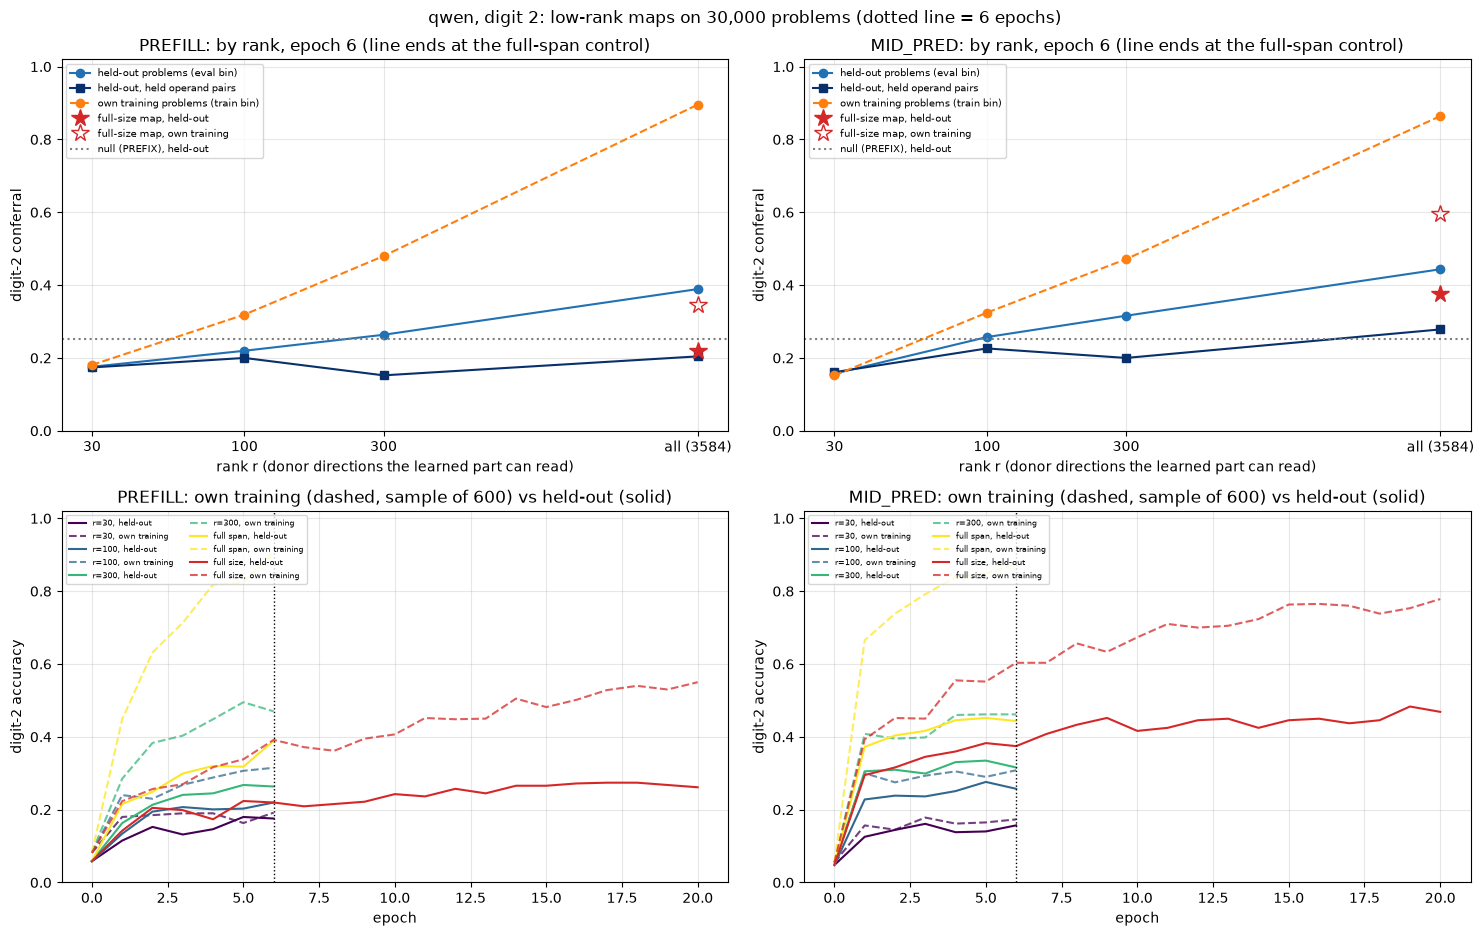

  [plot saved digitk30k_qwen_plots/LR30K_digit2.png]


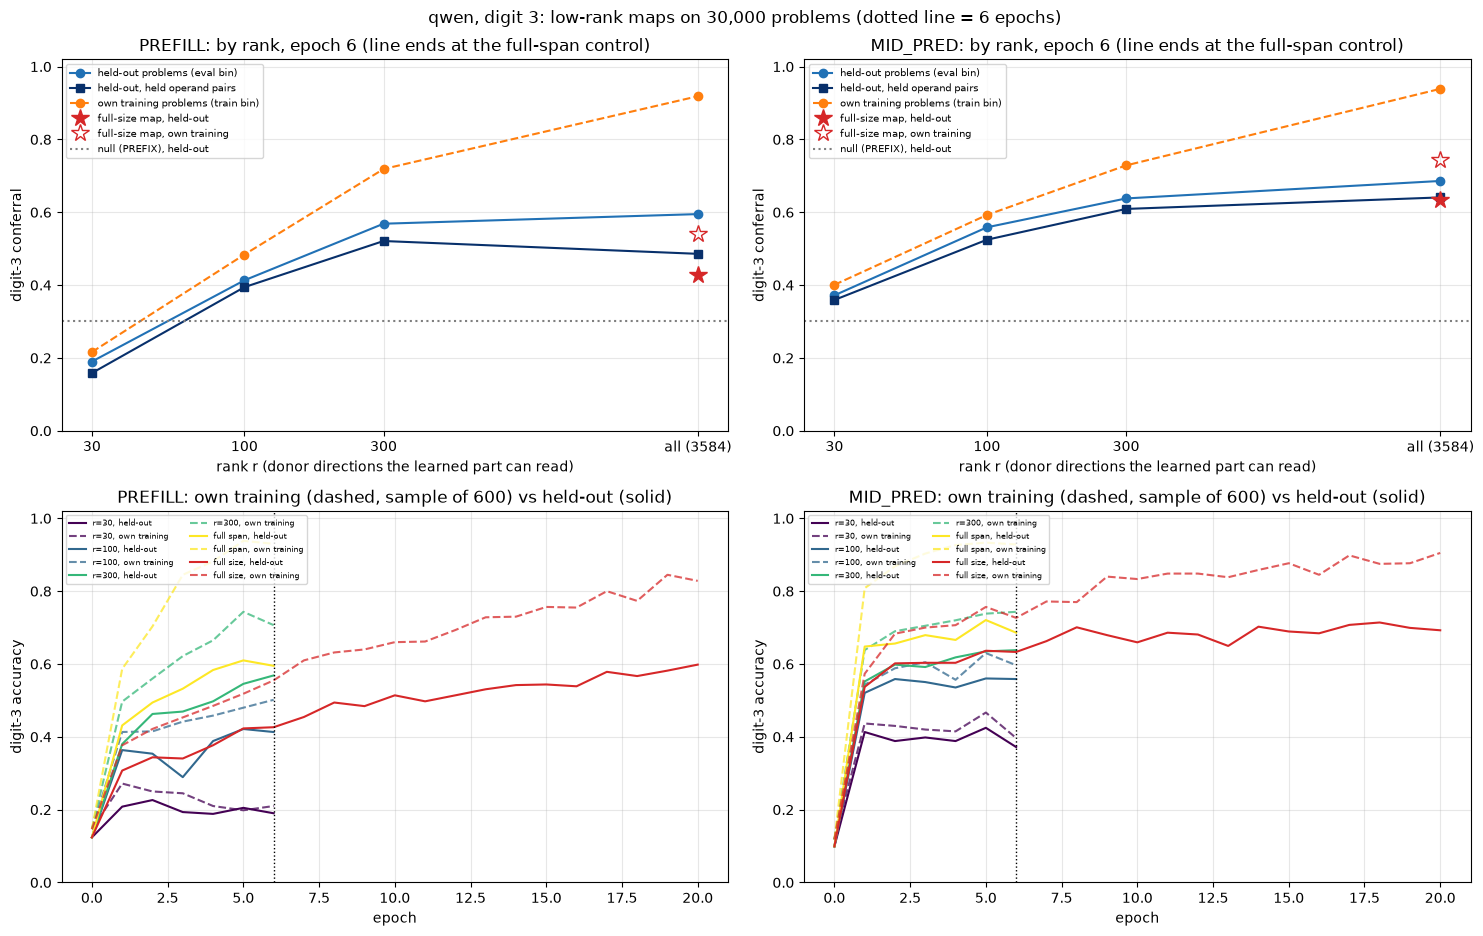

  [plot saved digitk30k_qwen_plots/LR30K_digit3.png]
  [6713s]
  [saved digitk30k_qwen.json after low-rank]

saved digitk30k_qwen.json -> DOWNLOAD it and the plots folder before terminating the pod


In [25]:

# %%
# === CELL 21: LOW-RANK maps on 30,000 problems — does the full-size map's memorising cost held-out accuracy? ===
# Why. The full-size map has 3,584 x d_R numbers (about 3.2M for Qwen, 8.3M for Gemma), so even on 30,000 problems
# it fits its own training problems better than new ones. If that memorising crowds out a general solution, a map
# with little room to memorise should do BETTER on held-out problems.
# The maps are A1's input-limited maps (the add-on to the 3,000-problem run), trained on the 30,000 problems:
#     graft = (x - mu) W0 + b + ((x - mu) P_r) B
# W0 = the ridge map the full-size map starts from (fixed); P_r = the top-r principal directions of this source's
# training states (fixed); trained: B (r x d_R, from 0) and b (from the recipient mean). At epoch 0 this IS the
# full-size map's starting point. Same problems, order, batch, loss and epochs as the full-size map. B's learning rate
# is scaled as in A1 (by how much less the graft moves when only r directions are read).
# THE CONTROL. That scaling is not neutral: in A1, this parametrisation with ALL directions trained much faster than
# the full-size map (own training problems 0.99 vs 0.56-0.63 at epoch 6) and did about 0.03 better on held-out
# problems, on both pairs. So each rank is compared with the same parametrisation using all directions ("full span":
# r = 3,584, same scaling rule), where only the number of directions differs. That comparison decides the verdict
# (Holm over all of them). The comparison with the full-size map is reported too, as description.
# A rank only informs the verdict if it (a) memorises clearly less than the full-span map (train-minus-held-out gap at
# least SESOI smaller, and a lower own-training fit) and (b) keeps the information (retention probes: the top-r
# directions keep at least RETAIN_MIN of the full state's above-majority probe accuracy for digit k and for the a*b
# digit). A gain counts only if it clears Holm, the training-order noise yardstick (the full-size map's seed 1 minus
# seed 0), the null and SHUF_PFX. The verdict is about input-limited linear maps, not every way to limit memorising.
# Also per map: held / seen operand pairs, and A1's 3,000-problem map of the same rank on the same eval problems.
# Pasting: this cell only uses what a finished run leaves in memory, so it can be added at the end of a finished
# run's notebook and run in the same kernel. Maps are cached like every other map.
# Time: (3 ranks + full span) x 2 sources x 2 digits = 16 maps, each costing about what a full-size map costs, plus
# probes and scoring (an estimate prints first). LR30K_EPOCHS = LONG_EPOCHS also gives 20-epoch maps (~3.3x the time).
t0 = time.time()
LR30K_RANKS = [30, 100, 300]          # A1 on 3,000 problems used 10, 30, 100 (r = 30 here is already more limited
                                      # per training problem than r = 10 was there)
LR30K_SOURCES = ["PREFILL", "MID_PRED"]
LR30K_EPOCHS = TASK_EPOCHS            # LONG_EPOCHS: also 20-epoch maps (the 6-epoch snapshot is kept)
RETAIN_MIN = 0.8                      # a rank "keeps the information" if its probes keep >= this share of the full state's
if SMOKE_TEST: LR30K_RANKS = [4, 8]
LRK = {"ranks": LR30K_RANKS, "epochs": LR30K_EPOCHS, "sources": LR30K_SOURCES, "retain_min": RETAIN_MIN,
       "design": "A1's input-limited map: graft = (x - mu) W0 + b + ((x - mu) P_r) B; W0 (the full-size map's ridge start) "
                 "and P_r (top-r principal directions of the training states) fixed; B and b trained on all training problems; "
                 "control = the same with all directions (full span)"}
RESULTS["LR30K_lowrank"] = LRK
_nsrc = {k: [s for s in LR30K_SOURCES if s in MAPS[k]] for k in K_LIST}
_fpc = RESULTS.get("fast_path_check") or {}
_sec = _fpc.get("sec_per_step_fast") if FAST_TRAIN else _fpc.get("sec_per_step_full")
_steps = sum(math.ceil(len(DS[k]["tr"]) / BATCH) * len(_nsrc[k]) for k in K_LIST) * (len(LR30K_RANKS) + 1) * LR30K_EPOCHS
print(f"LOW-RANK MAPS: ranks {LR30K_RANKS} + full span, x {LR30K_SOURCES} x digits {K_LIST}, {LR30K_EPOCHS} epochs: about "
      f"{_steps / 1000:.0f}k optimiser steps" + (f" -> about {_steps * _sec / 3600:.1f} h of training" if _sec else "")
      + ", plus about 10-20 min of probes and scoring (maps already in the cache are loaded instead)")

_LRB = {}
def _full_rank30k(k, src):
    n_, d_ = DS[k]["IN"]["tr"][src].shape; return min(n_ - 1, d_)
def _pca_basis30k(k, src, r):
    """The top-r principal directions (orthonormal columns, CPU) of this source's training states, from their
    covariance; at most min(n - 1, d) of them exist."""
    if (k, src) not in _LRB:
        X = DS[k]["IN"]["tr"][src]; n_, d_ = X.shape
        mu = sum(X[i:i + 4096].double().sum(0) for i in range(0, n_, 4096)) / n_
        C = torch.zeros(d_, d_, dtype=torch.float64)
        for i in range(0, n_, 4096):
            Xc = X[i:i + 4096].double() - mu; C += Xc.T @ Xc
        ev, V = torch.linalg.eigh(C)
        _LRB[(k, src)] = V[:, torch.argsort(ev, descending=True)[:_full_rank30k(k, src)]].float().contiguous()
        del C, V
    assert _LRB[(k, src)].shape[1] >= r, f"only {_LRB[(k, src)].shape[1]} directions available, asked for {r}"
    return _LRB[(k, src)][:, :r]

def train_lowrank30k(tag, k, src, r, epochs, snapshot_epochs=()):
    """A1's train_inputlimited on all training problems, with the fast training path like every other map here."""
    D = DS[k]; items = D["tr"]; S_tr = D["IN"]["tr"][src]; X2f = D["X2tr"]
    base = MAPS[k][src][0]
    if base.get("W0") is not None:
        W0 = base["W0"].float().to(DEVICE); mu = base["mu"].float().to(DEVICE)
    else:                                                  # (not expected: every linear map keeps its ridge start)
        _mu, _m2, W0 = fit_ridge(S_tr.float(), X2f.float()); W0 = W0.float().to(DEVICE); mu = _mu.float().to(DEVICE)
    P = _pca_basis30k(k, src, r).to(DEVICE)
    with torch.no_grad():                                  # A1's learning-rate scale, on training states only
        num = den = 0.0
        for i in range(0, S_tr.shape[0], 4096):
            xc = S_tr[i:i + 4096].to(DEVICE).float() - mu
            num += float(xc.abs().sum()); den += float((xc @ P).abs().sum())
        lr_scale = num / max(den, 1e-12)
    fp = dict(v=CODE_VERSION + "-lowrank30k", r=r, epochs=epochs, n=len(items), base=str(base.get("fp")), lr_scale=round(lr_scale, 4),
              targets=f"{sum((i + 1) * it['tgt'] for i, it in enumerate(items))}", snaps=list(snapshot_epochs),
              L_R=L_R, L_D=L_D, batch=BATCH, fast=bool(FAST_TRAIN))
    path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", f"{tag}_e{epochs}") + ".pt")
    if CACHE_MAPS and os.path.exists(path):
        try:
            M = torch.load(path, map_location=DEVICE)
            if M.get("fp") == fp:
                print(f"    [{tag}] loaded from {path}"); return M
            print(f"    [{tag}] cached map has a different fingerprint: retraining")
        except Exception as e:
            print(f"    [{tag}] cache unreadable ({e}): retraining")
    t1 = time.time()
    Bm = torch.zeros(r, X2f.shape[1], device=DEVICE, requires_grad=True)
    b = X2f.float().mean(0).to(DEVICE).clone().requires_grad_(True)
    opt = torch.optim.Adam([{"params": [Bm], "lr": 1e-3 * lr_scale}, {"params": [b], "lr": 1e-3}])
    print(f"    [{tag}] r={r}: B's learning rate = 1e-3 x {lr_scale:.2f}")
    view = lambda: dict(kind=f"inputlimited_r{r}", W=W0 + P @ Bm.detach(), b=b.detach(), mu=mu, W1=None)
    mon = make_monitor(k, src)
    idx = list(range(len(items))); ce, step_loss, snaps, steps = [], [], {}, 0
    curve = [{"epoch": 0, **mon(view())}]
    fast = fast_cache(items) if FAST_TRAIN else None      # this item list's layer-L_R outputs (training only)
    for ep in range(epochs):
        random.Random(ep).shuffle(idx)                     # = the seed-0 maps' order
        with fast_layers(fast is not None):
            hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch); run, nb = 0.0, 0
            try:
                for s in range(0, len(idx), BATCH):
                    sub = idx[s:s + BATCH]; xc = S_tr[sub].to(DEVICE).float() - mu
                    _graft["vec"] = xc @ W0 + b + (xc @ P) @ Bm
                    ids, m = left_pad([items[j]["ctx"] for j in sub], tokenizer.pad_token_id)
                    if fast is not None: fast.inject(sub, ids.shape[1])
                    lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE), **_FWD_KW).logits[:, -1, :].float()
                    loss = F.cross_entropy(lg, torch.tensor([items[j]["tgt"] for j in sub], device=DEVICE))
                    opt.zero_grad(); loss.backward(); opt.step()
                    lv = float(loss.detach()); run += lv; nb += 1; steps += 1; step_loss.append(float(f"{lv:.4g}"))
            finally:
                hk.remove(); _graft["vec"] = None; _inject["h"] = None
        ce.append(float(f"{run / max(1, nb):.4g}"))
        curve.append({"epoch": ep + 1, **mon(view())})     # full forward pass (outside the fast path)
        if ep + 1 in snapshot_epochs: snaps[ep + 1] = {"W": (W0 + P @ Bm.detach()).clone(), "b": b.detach().clone()}
        print(f"    {tag} epoch {ep + 1}: mean CE {ce[-1]:.4g} | {curve[-1]}")
    M = dict(kind=f"inputlimited_r{r}", rank=r, lr_scale=lr_scale, W=W0 + P @ Bm.detach(), b=b.detach(), mu=mu, W0=None, W1=None,
             ce=ce, curve=curve, step_loss=step_loss, steps=steps, n_train=len(items), fp=fp, snapshots=snaps,
             steps_per_epoch=math.ceil(len(items) / BATCH))
    if CACHE_MAPS:
        torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
    print(f"    [{tag}] input-limited r={r}: {steps} steps  [{time.time()-t1:.0f}s]")
    del opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return M

def _retention30k(k, src):
    """= A1: linear probes (trained on all training problems, tested on the eval bin) on the full donor state and on its
    top-r projections, for digit k and for the a*b digit at digit k's place, with the majority baseline."""
    D = DS[k]; B = D["BIN"]; Xtr = D["IN"]["tr"][src].float().cpu(); Xev = D["IN"]["ev"][src][B].float().cpu(); mu = Xtr.mean(0)
    out = {}
    for field, nm in (("dk", "digit k"), ("pdig", "a*b intermediate digit")):
        ytr = labels(k, "tr", field=field); yev = labels(k, "ev", field=field)[B]
        acc = lambda Ztr, Zev: rate((lin_probe_logits(lin_probe_fit(Ztr, ytr), Zev).argmax(1) == yev).tolist())
        row = {"majority": rate(_lookup_vec(k, lambda it: 0, field)), "full state": acc(Xtr, Xev)}
        for r in LR30K_RANKS:
            Pr = _pca_basis30k(k, src, r); row[f"r={r}"] = acc((Xtr - mu) @ Pr, (Xev - mu) @ Pr)
        out[nm] = row
    del Xtr, Xev
    return out
def _retained(ret, r):
    """Per probe: the share of the full state's above-majority accuracy the top-r directions keep (None where the full
    state is within SESOI of the majority baseline: nothing to keep)."""
    out = {}
    for nm, rw in ret.items():
        f_, m_, v_ = rw.get("full state"), rw.get("majority"), rw.get(f"r={r}")
        out[nm] = None if None in (f_, m_, v_) or f_ - m_ < SESOI else round((v_ - m_) / (f_ - m_), 3)
    return out

def _nulls_for30k(k, epochs):
    """The trained nulls trained for the same number of epochs, when they exist (and a cache tag for them)."""
    if epochs > TASK_EPOCHS and f"CONST_ep{epochs}" in MAPS[k] and f"PREFIX_ep{epochs}" in MAPS[k]:
        return (f"CONST_ep{epochs}", f"PREFIX_ep{epochs}"), f"_ep{epochs}"
    return ("CONST", "PREFIX"), ""

_LR_VEC = {}
def _vec(k, name, split):
    """Per-item outcomes (eval bin or training bin, in bin order) of map `name`, cached for this cell."""
    if (k, name, split) not in _LR_VEC:
        D = DS[k]; _LR_VEC[(k, name, split)] = [float(x) for x in conf(k, name, split, D["BIN"] if split == "ev" else D["TRBIN"])[0]]
    return _LR_VEC[(k, name, split)]
def _lr_eval(k, name, refs, nulls=("CONST", "PREFIX"), tag=""):
    """= A1's addon_eval: `name` on held-out problems (eval bin) and on its own training problems (train bin). The
    reference null is the stronger trained null ON THE TRAINING BIN (never picked on the items it is tested on);
    SHUF_PFX on held-out problems; `name` minus each reference map in refs {label: map} on the same problems (paired);
    and the held-out results split by held / seen operand pairs."""
    global TRAINED_NULLS
    D = DS[k]; B = D["BIN"]
    for q in [q for q in list(_NULLS) if q[:2] == (k, name)]: _NULLS.pop(q)      # never reuse stale null vectors
    ev_ok, _, ev_ce = conf(k, name, "ev", B, want_ce=True); tr_ok, _, tr_ce = conf(k, name, "tr", D["TRBIN"], want_ce=True)
    evf, trf = [float(x) for x in ev_ok], [float(x) for x in tr_ok]
    _LR_VEC[(k, name, "ev")], _LR_VEC[(k, name, "tr")] = evf, trf
    used = tuple(n_ for n_ in nulls if n_ in MAPS[k])
    assert used, f"none of the nulls {nulls} is trained for digit {k}"
    old = TRAINED_NULLS; TRAINED_NULLS = used
    try:
        nv_ev = null_vectors(k, name, "ev", B, f"eval_bin_lr30k{tag}")
    finally:
        TRAINED_NULLS = old
    nv_tr = {}
    for n_ in used:                                                               # trained nulls on the training bin
        key = (k, n_, "tr", f"train_bin_lr30k{tag}")
        if key not in _TNULL: _TNULL[key] = [float(x) for x in conf(k, n_, "tr", D["TRBIN"])[0]]
        nv_tr[n_] = _TNULL[key]
    st = max(used, key=lambda n_: rate(nv_tr[n_]))                              # chosen on the training bin
    p_ev, p_tr, p_sh = paired(nv_ev[st], evf), paired(nv_tr[st], trf), paired(nv_ev["SHUF_PFX"], evf)
    lab = _fit_label(p_tr, p_ev)
    if above(p_ev) and not above(p_sh): lab += " (held-out gain NOT above SHUF_PFX: it does not need this problem's own state)"
    out = {"eval_bin": R(ev_ok), "train_bin": R(tr_ok), "eval_bin_CE": round(float(np.mean(ev_ce)), 4),
           "train_bin_CE": round(float(np.mean(tr_ce)), 4), "gap_train_minus_eval": round(rate(tr_ok) - rate(ev_ok), 4),
           "steps": MAPS[k][name][0].get("steps"), "nulls_used": list(used) + ["SHUF_PFX"],
           "nulls_eval": {n_: rate(v) for n_, v in nv_ev.items()}, "nulls_train": {n_: rate(v) for n_, v in nv_tr.items()},
           "eval_minus_null": {**p_ev, "null": st, "null_chosen_on": "training bin", "label": effect_label(p_ev, "gain over the null")},
           "train_minus_null": {**p_tr, "null": st},
           "eval_minus_SHUF_PFX": {**p_sh, "label": effect_label(p_sh, "gain over SHUF_PFX")},
           "label": lab, "by_operand_pair": {}}
    for L, ref in refs.items():
        rf_ev, rf_tr = _vec(k, ref, "ev"), _vec(k, ref, "tr"); p_rf = paired(rf_ev, evf)
        out.update({f"{L}_map": ref, f"{L}_eval_bin": rate(rf_ev), f"{L}_train_bin": rate(rf_tr),
                    f"{L}_gap_train_minus_eval": round(rate(rf_tr) - rate(rf_ev), 4),
                    f"eval_minus_{L}": {**p_rf, "label": effect_label(p_rf, f"gain over the {L.replace('_', '-')} map")},
                    f"train_minus_{L}": paired(rf_tr, trf)})
    for g, pos in (("held", D["HELD_POS"]), ("seen", D["SEEN_POS"])):
        row = {"n": len(pos), "eval_bin": rate([evf[n_] for n_ in pos]),
               "minus_null": paired([nv_ev[st][n_] for n_ in pos], [evf[n_] for n_ in pos])}
        for L, ref in refs.items():
            rf_ev = _vec(k, ref, "ev")
            row[L] = rate([rf_ev[n_] for n_ in pos]); row[f"minus_{L}"] = paired([rf_ev[n_] for n_ in pos], [evf[n_] for n_ in pos])
        out["by_operand_pair"][g] = row
    for split, v in (("eval_bin", ev_ok), ("train_bin", tr_ok)): PER_ITEM[f"d{k}/{name}/{split}"] = [int(x) for x in v]
    return out

def _aligned3k(k):
    """Same eval bin as the 3,000-problem run: same size, answer lengths, and the training-independent bin numbers."""
    if REF3K is None: return False
    b3 = ref3k_get("bins", f"d{k}") or {}; b30 = (RESULTS.get("bins", {}).get(f"d{k}") or {})
    same = lambda key: {str(a_): v_ for a_, v_ in (b3.get(key) or {}).items()} == {str(a_): v_ for a_, v_ in (b30.get(key) or {}).items()}
    ok = b3.get("n_eval_bin") == len(DS[k]["BIN"]) and same("eval_bin_answer_lengths")
    for key in ("recipient_native_digit_k_eval", "donor_teacher_forced_digit_k_eval", "n_S4_population_recipient_wrong"):
        if key in b3 and key in b30: ok = ok and b3[key] == b30[key]
    return ok
def _vs_a1(k, src, r, ep, v30):
    """A1's map of the same rank on 3,000 problems, on the same eval problems: paired when the bins line up."""
    a1 = ref3k_get("ADDON", "inputlimited", f"d{k}", f"{src}_in{r}", f"epoch_{ep}")
    if not a1: return None
    v3 = ref3k_get("per_item", f"d{k}/{src}_in{r}" + ("" if ep == TASK_EPOCHS else f"_ep{ep}") + "/eval_bin")
    hp = DS[k]["HELD_POS"]
    out = {"eval_bin_3k": a1["eval_bin"]["rate"], "train_bin_3k": a1["train_bin"]["rate"], "gap_3k": a1.get("gap_train_minus_eval"),
           "eval_minus_full_size_3k": (a1.get("eval_minus_reference") or {}).get("ci"), "eval_bin_30k": rate(v30)}
    if _aligned3k(k) and v3 is not None and len(v3) == len(v30):
        out.update({"eval_bin_3k_held_operand_pairs": rate([v3[n] for n in hp]),
                    "eval_bin_30k_held_operand_pairs": rate([v30[n] for n in hp]),
                    "eval_30k_minus_3k (paired 95%)": paired(v3, v30)["ci"],
                    "eval_30k_minus_3k_held_operand_pairs (paired 95%)": paired([v3[n] for n in hp], [v30[n] for n in hp])["ci"]})
    else:
        p3, n3, p30, n30 = a1["eval_bin"]["rate"], a1["eval_bin"]["n"], rate(v30), len(v30)
        if None not in (p3, p30) and n3 and n30:
            d = p30 - p3; se = math.sqrt(max(p3 * (1 - p3), 0) / n3 + max(p30 * (1 - p30), 0) / n30)
            out["eval_30k_minus_3k (unpaired 95%)"] = f"{d:+.3f} [{d - 1.96 * se:+.3f}, {d + 1.96 * se:+.3f}]"
    return out

# ---- train, evaluate, compare ----
snap = LR30K_EPOCHS > TASK_EPOCHS
_f3 = lambda v: "n/a" if v is None else f"{v:.3f}"
_yn = lambda v: "yes" if v else "no"
for k in K_LIST:
    D = DS[k]; LRK[f"d{k}"] = {}
    for src in _nsrc[k]:
        rt = _retention30k(k, src); LRK[f"d{k}"][src] = {"retention_probes": rt, "full_span_rank": _full_rank30k(k, src)}
        print(f"\n  RETENTION (digit {k}, {src}): held-out linear-probe accuracy on the full state vs its top-r directions")
        for nm, row in rt.items(): print(f"     {nm:24s} " + " | ".join(f"{c} {v:.3f}" for c, v in row.items() if v is not None))
    for src in _nsrc[k]:
        for nm, r in [(f"{src}_fullspan", _full_rank30k(k, src))] + [(f"{src}_in{r}", r) for r in LR30K_RANKS]:
            M = train_lowrank30k(f"d{k}_{nm}_lowrank30k", k, src, r, LR30K_EPOCHS, snapshot_epochs=(TASK_EPOCHS,) if snap else ())
            MAPS[k][nm] = (snapshot_map(M, TASK_EPOCHS) if snap else M, src)
            if snap: MAPS[k][f"{nm}_ep{LR30K_EPOCHS}"] = (M, src)
        save(f"low-rank trained d{k} {src}")
    fast_cache_clear()
    print(f"\n  DIGIT {k}: low-rank maps vs the full-span control and the full-size map (same problems, paired)")
    for src in _nsrc[k]:
        G = LRK[f"d{k}"][src]
        if f"{src}_s1" in MAPS[k]:                    # training-order noise: the full-size map, seed 1 minus seed 0, held-out
            G["seed_noise_yardstick"] = {**paired(_vec(k, src, "ev"), _vec(k, f"{src}_s1", "ev")),
                                         "what": "full-size map, seed 1 (another training order) minus seed 0, held-out (6 epochs)"}
        eps = [TASK_EPOCHS] + ([LR30K_EPOCHS] if snap else [])
        for ep in eps:
            sfx = "" if ep == TASK_EPOCHS else f"_ep{ep}"
            nl, tg = _nulls_for30k(k, ep) if ep > TASK_EPOCHS else (("CONST", "PREFIX"), "")
            fsz = f"{src}{sfx}" if f"{src}{sfx}" in MAPS[k] else src
            G.setdefault("full_span", {})[f"epoch_{ep}"] = _lr_eval(k, f"{src}_fullspan{sfx}", {"full_size": fsz}, nulls=nl, tag=tg)
            for r in LR30K_RANKS:
                row = G.setdefault(f"r={r}", {})
                row[f"epoch_{ep}"] = _lr_eval(k, f"{src}_in{r}{sfx}", {"full_span": f"{src}_fullspan{sfx}", "full_size": fsz}, nulls=nl, tag=tg)
                row[f"epoch_{ep}"]["vs_3k_A1"] = _vs_a1(k, src, r, ep, PER_ITEM[f"d{k}/{src}_in{r}{sfx}/eval_bin"])
        for nm, key in [(f"{src}_fullspan", "full_span")] + [(f"{src}_in{r}", f"r={r}") for r in LR30K_RANKS]:
            Mc = MAPS[k][f"{nm}_ep{LR30K_EPOCHS}" if snap else nm][0]
            G[key]["curve"] = Mc["curve"]; G[key]["lr_scale"] = round(float(Mc["lr_scale"]), 4)
            G[key]["plateau (training-bin CE)"] = plateau_readout([c["train_bin_CE"] for c in Mc["curve"][1:]])
        for ep in eps:
            ek = f"epoch_{ep}"; fs = G["full_span"][ek]; e0 = G[f"r={LR30K_RANKS[0]}"][ek]
            print(f"\n     d{k} {src}, epoch {ep}: rank | held-out | held pairs | own training | gap | minus full span (paired) | "
                  f"held pairs minus full span | minus full size | minus {e0['eval_minus_null']['null']} | 3,000-problem A1 held-out")
            for r in LR30K_RANKS:
                x = G[f"r={r}"][ek]; a1 = x.get("vs_3k_A1") or {}
                print(f"       r={r:<6} {_f3(x['eval_bin']['rate'])} | {_f3(x['by_operand_pair']['held']['eval_bin'])} | {_f3(x['train_bin']['rate'])} | "
                      f"{x['gap_train_minus_eval']:+.3f} | {x['eval_minus_full_span']['ci']} | {x['by_operand_pair']['held']['minus_full_span']['ci']} | "
                      f"{x['eval_minus_full_size']['ci']} | {x['eval_minus_null']['ci']} | {_f3(a1.get('eval_bin_3k'))}")
            print(f"       span   {_f3(fs['eval_bin']['rate'])} | {_f3(fs['by_operand_pair']['held']['eval_bin'])} | {_f3(fs['train_bin']['rate'])} | "
                  f"{fs['gap_train_minus_eval']:+.3f} | (the control: r = {G['full_span_rank']}) | | {fs['eval_minus_full_size']['ci']} | "
                  f"{fs['eval_minus_null']['ci']}")
            print(f"       size   {_f3(fs['full_size_eval_bin'])} | {_f3(fs['by_operand_pair']['held']['full_size'])} | {_f3(fs['full_size_train_bin'])} | "
                  f"{fs['full_size_gap_train_minus_eval']:+.3f} | (the full-size map: {fs['full_size_map']})")
        if G.get("seed_noise_yardstick"): print(f"       training-order noise (full-size seed 1 minus seed 0, held-out): {G['seed_noise_yardstick']['ci']}")
    save(f"low-rank d{k}")

# ---- verdict (epoch 6): does limiting what the map can memorise raise held-out conferral? ----
_pv = {}
for k in K_LIST:
    for src in _nsrc[k]:
        for r in LR30K_RANKS:
            p = LRK[f"d{k}"][src][f"r={r}"][f"epoch_{TASK_EPOCHS}"]["eval_minus_full_span"]
            if p.get("p_boot") is not None: _pv[f"d{k}/{src}/r={r}"] = p["p_boot"]
_adj = holm(_pv) if _pv else {}
LRK["holm_low_rank_minus_full_span_epoch6"] = _adj
print(f"\n  VERDICT (epoch {TASK_EPOCHS}; each rank vs the full-span control; Holm over {len(_pv)} comparisons). A rank informs the verdict "
      f"only if it memorises clearly less (gap >= {SESOI} smaller, lower own-training fit) and keeps >= {RETAIN_MIN:.0%} of the probe "
      f"information; a gain counts only if it clears Holm, the training-order noise, the null and SHUF_PFX.")
for k in K_LIST:
    for src in _nsrc[k]:
        G = LRK[f"d{k}"][src]; nz = G.get("seed_noise_yardstick") or {}
        noise = abs(nz["diff"]) if nz.get("diff") is not None else 0.0
        per = {}
        for r in LR30K_RANKS:
            x = G[f"r={r}"][f"epoch_{TASK_EPOCHS}"]; p = x["eval_minus_full_span"]; t = x["train_minus_full_span"]
            less = (x["gap_train_minus_eval"] <= x["full_span_gap_train_minus_eval"] - SESOI and t.get("hi") is not None and t["hi"] < 0)
            fr = _retained(G["retention_probes"], r); keeps = all(v is None or v >= RETAIN_MIN for v in fr.values())
            hp = _adj.get(f"d{k}/{src}/r={r}")
            better = (above(p) and hp is not None and hp < 0.05 and p["diff"] > noise
                      and above(x["eval_minus_null"]) and above(x["eval_minus_SHUF_PFX"]))
            per[r] = {"eval_minus_full_span": p["ci"], "holm_p": hp, "memorises_less": less, "retention_share": fr,
                      "keeps_information": keeps, "informative": less and keeps, "better": better}
        G["verdict_by_rank"] = per
        better = [r for r in LR30K_RANKS if per[r]["better"]]; inf = [r for r in LR30K_RANKS if per[r]["informative"]]
        his = [G[f"r={r}"][f"epoch_{TASK_EPOCHS}"]["eval_minus_full_span"]["hi"] for r in inf]
        his = [h for h in his if h is not None]
        if better:
            v = (f"LOW RANK BETTER (r = {better}): an input-limited map reaches higher held-out conferral than the same map with all "
                 f"directions, above the null and SHUF_PFX: here the unrestricted map's memorising costs held-out conferral")
        elif not inf:
            v = ("UNINFORMATIVE: no rank both memorises clearly less than the full-span map and keeps the digit information, "
                 "so this cannot say whether memorising costs held-out conferral")
        elif his and max(his) < SESOI:
            v = (f"NO GAIN: none of the informative ranks (r = {inf}) beats the full-span map by {SESOI} or more (largest upper bound "
                 f"{max(his):+.3f}); for input-limited maps, memorising is not holding held-out conferral down")
        else:
            v = (f"no informative rank (r = {inf}) is clearly better, but a gain of {SESOI} or more is not ruled out "
                 f"(largest upper bound {max(his):+.3f})" if his else "n/a")
        G["verdict"] = v
        print(f"     d{k} {src}: {v}")
        for r in LR30K_RANKS:
            q = per[r]
            print(f"        r={r}: minus full span {q['eval_minus_full_span']} (Holm p {q['holm_p']}) | memorises less: {_yn(q['memorises_less'])} | "
                  f"keeps information: {_yn(q['keeps_information'])} {q['retention_share']}")
        if nz.get("ci"): print(f"        training-order noise yardstick: {nz['ci']}")
LRK["_notes"] = {"held / seen operand pairs": "descriptive: uncorrected 95% intervals on subgroups",
                 "full size vs full span": "the full-span control uses A1's scaled learning rate with all directions; its difference "
                                           "from the full-size map is an optimiser effect, not a capacity effect",
                 "scope": "input-limited linear maps only; RETAIN_MIN and the 'memorises less' rule are choices made before the run"}

# ---- one figure per digit: conferral by rank (top) and per-epoch training vs held-out (bottom) ----
for k in K_LIST:
    srcs = _nsrc[k]
    if not srcs: continue
    fig, ax = plt.subplots(2, len(srcs), figsize=(7.5 * len(srcs), 9.5), squeeze=False)
    for j, src in enumerate(srcs):
        G = LRK[f"d{k}"][src]; ek = f"epoch_{TASK_EPOCHS}"; fs = G["full_span"][ek]; e = [G[f"r={r}"][ek] for r in LR30K_RANKS] + [fs]
        rf = G["full_span_rank"]; xs = LR30K_RANKS + [rf]
        a = ax[0][j]
        a.plot(xs, [x["eval_bin"]["rate"] for x in e], "o-", color="#2171b5", label="held-out problems (eval bin)")
        a.plot(xs, [x["by_operand_pair"]["held"]["eval_bin"] for x in e], "s-", color="#08306b", label="held-out, held operand pairs")
        a.plot(xs, [x["train_bin"]["rate"] for x in e], "o--", color="#ff7f0e", label="own training problems (train bin)")
        a.plot([rf], [fs["full_size_eval_bin"]], "*", ms=13, color="#d62728", label="full-size map, held-out")
        a.plot([rf], [fs["full_size_train_bin"]], "*", ms=13, mfc="none", color="#d62728", label="full-size map, own training")
        nl = fs["eval_minus_null"]["null"]
        if fs["nulls_eval"].get(nl) is not None:
            a.axhline(fs["nulls_eval"][nl], color="#7f7f7f", ls=":", label=f"null ({nl}), held-out")
        a1x = [r for r in (ref3k_get("ADDON", "inputlimited", "ranks") or [])
               if ref3k_get("ADDON", "inputlimited", f"d{k}", f"{src}_in{r}", ek, "eval_bin", "rate") is not None]
        if a1x:
            a.plot(a1x, [ref3k_get("ADDON", "inputlimited", f"d{k}", f"{src}_in{r}", ek, "eval_bin", "rate") for r in a1x], "x:",
                   color="#9ecae1", label="3,000 problems (A1), held-out")
        ticks = sorted(set(xs + a1x)); a.set_xscale("log"); a.minorticks_off(); a.set_xticks(ticks)
        a.set_xticklabels([f"all ({x})" if x == rf else str(x) for x in ticks])
        a.set_ylim(0, 1.02); a.set_xlabel("rank r (donor directions the learned part can read)"); a.set_ylabel(f"digit-{k} conferral")
        a.set_title(f"{src}: by rank, epoch {TASK_EPOCHS} (line ends at the full-span control)"); a.legend(fontsize=7, loc="upper left"); a.grid(alpha=0.3)
        b_ = ax[1][j]; cm = plt.get_cmap("viridis")
        for i, (key, lab) in enumerate([(f"r={r}", f"r={r}") for r in LR30K_RANKS] + [("full_span", "full span")]):
            cv = G[key]["curve"]; col = cm(i / max(1, len(LR30K_RANKS)))
            b_.plot([c["epoch"] for c in cv], [c["eval_bin"] for c in cv], "-", color=col, label=f"{lab}, held-out")
            b_.plot([c["epoch"] for c in cv], [c["train_bin"] for c in cv], "--", color=col, alpha=0.75, label=f"{lab}, own training")
        cv = MAPS[k].get(f"{src}_ep{LONG_EPOCHS}", MAPS[k][src])[0].get("curve") or []
        if cv:
            b_.plot([c["epoch"] for c in cv], [c["eval_bin"] for c in cv], "-", color="#d62728", label="full size, held-out")
            b_.plot([c["epoch"] for c in cv], [c["train_bin"] for c in cv], "--", color="#d62728", alpha=0.75, label="full size, own training")
        b_.axvline(TASK_EPOCHS, ls=":", c="k", lw=1); b_.set_ylim(0, 1.02); b_.set_xlabel("epoch"); b_.set_ylabel(f"digit-{k} accuracy")
        b_.set_title(f"{src}: own training (dashed, sample of {len(DS[k]['TRBIN_MON'])}) vs held-out (solid)")
        b_.legend(fontsize=6, ncol=2, loc="upper left"); b_.grid(alpha=0.3)
    fig.suptitle(f"{PAIR}, digit {k}: low-rank maps on {len(train):,} problems (dotted line = {TASK_EPOCHS} epochs)")
    fig.tight_layout(); _p = os.path.join(PLOT_DIR, f"LR30K_digit{k}.png"); fig.savefig(_p, dpi=130); plt.show(); plt.close(fig)
    print(f"  [plot saved {_p}]")
print(f"  [{time.time()-t0:.0f}s]"); save("low-rank")
print("\nsaved", OUT_JSON, "-> DOWNLOAD it and the plots folder before terminating the pod")


SELF-MAP NULL: ['SELF', 'SELF_s1', 'SELF_MLP'] x digits [2, 3] (SELF to 20 epochs): about 116k optimiser steps -> about 0.9 h of training, plus a few minutes of scoring (maps already in the cache are loaded instead)

  DIGIT 2: training ['SELF', 'SELF_s1', 'SELF_MLP'] on the recipient's own layer-17 state
    [fast path] cached layer-17 outputs for 29997 contexts (4.0 GB on cuda)  [47s]
    d2_SELF epoch 1: mean CE 1.42 | {'epoch': 1, 'train_bin': 0.555, 'eval_bin': 0.4205, 'train_bin_CE': 1.0965, 'eval_bin_CE': 1.4888}
    d2_SELF epoch 2: mean CE 1.043 | {'epoch': 2, 'train_bin': 0.635, 'eval_bin': 0.4749, 'train_bin_CE': 0.8795, 'eval_bin_CE': 1.3226}
    d2_SELF epoch 3: mean CE 0.8943 | {'epoch': 3, 'train_bin': 0.6117, 'eval_bin': 0.4916, 'train_bin_CE': 0.857, 'eval_bin_CE': 1.2936}
    d2_SELF epoch 4: mean CE 0.8032 | {'epoch': 4, 'train_bin': 0.71, 'eval_bin': 0.4916, 'train_bin_CE': 0.7026, 'eval_bin_CE': 1.2854}
    d2_SELF epoch 5: mean CE 0.7301 | {'epoch': 5, 'train_bin'

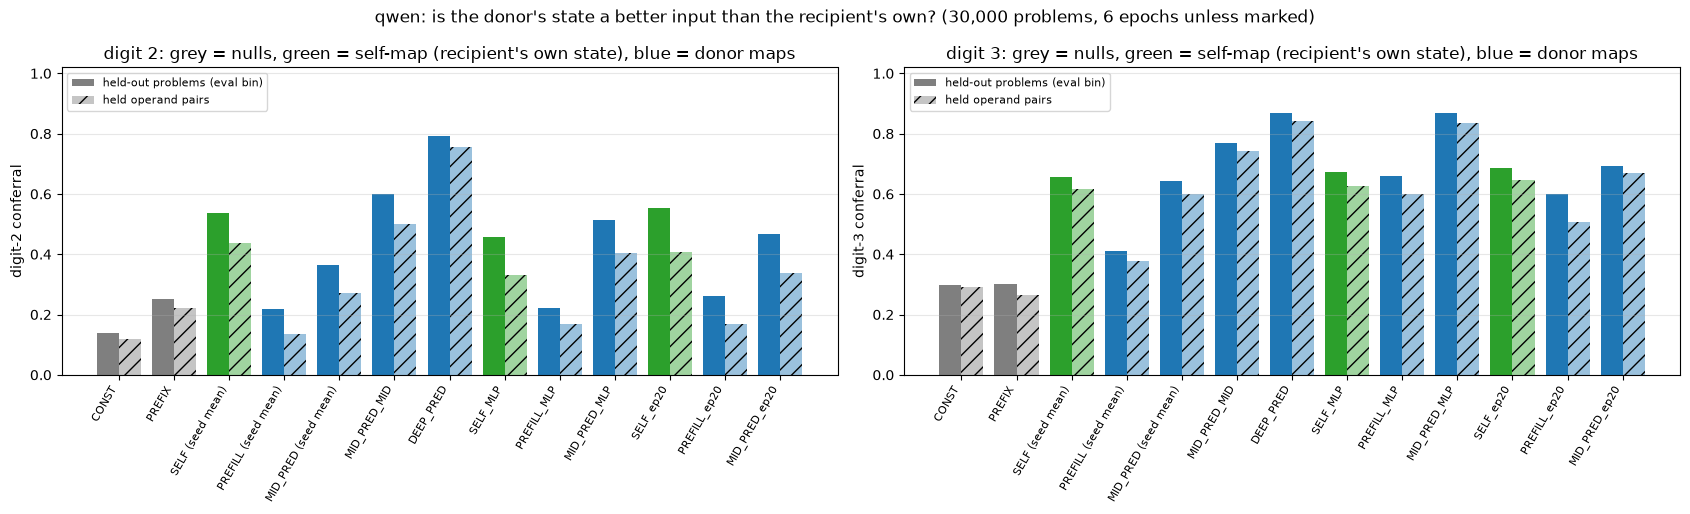

  [plot saved digitk30k_qwen_plots/SELF_null.png]
  [3589s]
  [saved digitk30k_qwen.json after self-map]

saved digitk30k_qwen.json -> DOWNLOAD it and the plots folder before terminating the pod


In [26]:
# %%
# === CELL 22: SELF-MAP null — is the donor's state a better input than the recipient's OWN state, for the same map? ===
# Why. With 30,000 training problems, trained readouts do part of the arithmetic themselves: an MLP probe on the
# recipient's own layer-L_R state reads digit k on many eval-bin problems the recipient itself gets wrong (Part P's
# 'recipient_mlp' baseline: Qwen 0.47 for digit 2, 0.57 for digit 3, up from 0.25 / 0.32 on 3,000 problems). So a
# donor map above CONST / PREFIX could be the trained map (with the recipient's frozen upper layers) solving part of the
# problem from what the recipient already represents. CONST and PREFIX cannot catch that: they carry no information
# about the problem.
# The SELF map is the donor map's recipe with the donor state replaced by the recipient's OWN layer-L_R state at the
# graft position (the state the graft replaces): ridge start (here close to the identity, so epoch 0 ~ the recipient's
# own answer, wrong on the bin), b from the recipient mean, Adam 1e-3, batch 16, CE on digit k, the same problems,
# order and epochs. SELF_s1 = the second training order (with RUN_EXTRA_SEED); SELF_MLP = the MLP map's recipe.
# Read: donor map minus SELF on the eval bin (paired; seed means when both have a second seed, else seed 0 vs seed 0),
# overall and by operand pair.
#   SELF not above the fair nulls -> UNINFORMATIVE: the self-map sets no higher bar than Part 2's nulls
#   above SELF (Holm, and more than the training-order noise) -> the donor's state is the better input for this map.
#        Caveat: the eval bin is selected for the recipient's own answer being wrong and the donor's being right, which
#        favours the donor here; the same difference on all eval items and on the donor-right items (no recipient
#        filter) is printed next to it
#   within SESOI of SELF -> the donor's state is no better an input than the recipient's own; this level of conferral
#        does not need information the recipient lacks (robust to the selection, which works against SELF)
#   below SELF -> the recipient's own state is the better input
# Primary: PREFILL and MID_PRED x digits, Holm over those cells (the BELOW / within-SESOI calls use uncorrected 95%
# intervals). MID_PRED_MID / DEEP_PRED vs SELF and the MLP maps vs SELF_MLP are descriptive. With RUN_LONG (and the
# 20-epoch donor maps present), SELF also runs to LONG_EPOCHS (the 6-epoch snapshot is the map used above) and is set
# next to PREFILL / MID_PRED at 20 epochs (descriptive, one seed), because the 6-epoch maps are still training.
# Pasting: this cell only uses what a finished run leaves in memory (DS, MAPS, PER_ITEM and the map machinery), so it
# can be added at the end of a finished run's notebook and run in the same kernel. Maps are cached like every other map.
# If the kernel was restarted: run cells 2-9, Part T (cell 11: maps load from the cache) and Part 1 (cell 12), then this.
t0 = time.time()
SELF_RUN_LONG = True                  # False: SELF only to TASK_EPOCHS (saves about half of this cell's training)
SELF_LONG = bool(SELF_RUN_LONG and RUN_LONG and LONG_EPOCHS > TASK_EPOCHS and all(f"{s}_ep{LONG_EPOCHS}" in MAPS[k] for k in K_LIST
                                                                for s in ("PREFILL", "MID_PRED", "CONST", "PREFIX")))
SELF_PLAN = ([("SELF", "linear", 0)] + ([("SELF_s1", "linear", 1)] if RUN_EXTRA_SEED else [])
             + ([("SELF_MLP", "mlp", 0)] if RUN_MLP_MAP else []))
SN = {"design": "donor map minus the same recipe fed the recipient's own layer-L_R state at the graft position",
      "plan": [p[0] for p in SELF_PLAN], "long": SELF_LONG, "epochs": TASK_EPOCHS, "long_epochs": LONG_EPOCHS if SELF_LONG else None}
RESULTS["SELF_null"] = SN
_fpc = RESULTS.get("fast_path_check") or {}
_sec = _fpc.get("sec_per_step_fast") if FAST_TRAIN else _fpc.get("sec_per_step_full")
_steps = sum(math.ceil(len(DS[k]["tr"]) / BATCH) * sum(LONG_EPOCHS if (SELF_LONG and nm == "SELF") else TASK_EPOCHS
                                                       for nm, _, _ in SELF_PLAN) for k in K_LIST)
print(f"SELF-MAP NULL: {[p[0] for p in SELF_PLAN]} x digits {K_LIST}" + (f" (SELF to {LONG_EPOCHS} epochs)" if SELF_LONG else "")
      + f": about {_steps / 1000:.0f}k optimiser steps" + (f" -> about {_steps * _sec / 3600:.1f} h of training" if _sec else "")
      + ", plus a few minutes of scoring (maps already in the cache are loaded instead)")

_SELF_NAMES = [p[0] for p in SELF_PLAN] + ([f"SELF_ep{LONG_EPOCHS}"] if SELF_LONG else [])
for k in K_LIST:                                         # never reuse outcomes of an earlier SELF run (maps may have changed)
    for nm in _SELF_NAMES:
        for lab in ("eval_bin", "train_bin"): PER_ITEM.pop(f"d{k}/{nm}/{lab}", None)
    for q in [q for q in list(_NULLS) if q[0] == k and q[1] in _SELF_NAMES]: _NULLS.pop(q)
_SV2 = {}

def _sv(k, name, split):
    """Per-item outcomes of map `name` on the eval bin ('ev') or the training bin ('tr'), in bin order (from PER_ITEM
    when Part 1 or this cell already scored it)."""
    D = DS[k]; key = f"d{k}/{name}/{'eval_bin' if split == 'ev' else 'train_bin'}"
    if key not in PER_ITEM:
        PER_ITEM[key] = [int(x) for x in conf(k, name, split, D["BIN"] if split == "ev" else D["TRBIN"])[0]]
    return [float(x) for x in PER_ITEM[key]]
def _pops(k):
    """Eval populations: the bin (recipient wrong, donor right: the primary), every eval item, and the items the donor
    gets right (no recipient filter)."""
    D = DS[k]; ev = D["ev"]
    return {"all eval items": list(range(len(ev))), "donor-right items": [i for i in range(len(ev)) if ev[i]["tf"][k - 1]]}
def _svp(k, name, pop):
    if pop == "bin": return _sv(k, name, "ev")
    if (k, name, pop) not in _SV2: _SV2[(k, name, pop)] = [float(x) for x in conf(k, name, "ev", _pops(k)[pop])[0]]
    return _SV2[(k, name, pop)]
def _matched(k, S, pop="bin"):
    """Donor map S and SELF with matched seeds: both seed means when both have a seed-1 map, else seed 0 vs seed 0."""
    both = f"{S}_s1" in MAPS[k] and "SELF_s1" in MAPS[k]
    if both:
        dv = ((np.asarray(_svp(k, S, pop)) + np.asarray(_svp(k, f"{S}_s1", pop))) / 2).tolist()
        sv = ((np.asarray(_svp(k, "SELF", pop)) + np.asarray(_svp(k, "SELF_s1", pop))) / 2).tolist()
    else:
        dv, sv = _svp(k, S, pop), _svp(k, "SELF", pop)
    return dv, sv, 2 if both else 1
def _split(k, a, b):
    """b minus a, paired, on all eval-bin problems and by held / seen operand pair."""
    D = DS[k]; out = {"all": paired(a, b)}
    for lab, pos in (("held", D["HELD_POS"]), ("seen", D["SEEN_POS"])):
        out[lab] = paired([a[n] for n in pos], [b[n] for n in pos])
    return out
def _fair_null(k, S, tag="eval_bin"):
    """= Part 2's PRIMARY null for map S: CONST, PREFIX and SHUF_PFX (averaged over S and its seed-1 map when that exists);
    the strongest on the eval bin. Returns (name, per-item vector) and S's own vector (seed mean when it exists)."""
    B = DS[k]["BIN"]; nv = dict(null_vectors(k, S, "ev", B, tag)); mv = np.asarray(_sv(k, S, "ev"), float)
    if f"{S}_s1" in MAPS[k]:
        nv["SHUF_PFX"] = _nanavg(nv["SHUF_PFX"], null_vectors(k, f"{S}_s1", "ev", B, tag)["SHUF_PFX"])
        mv = (mv + np.asarray(_sv(k, f"{S}_s1", "ev"), float)) / 2
    st = strongest(nv); return st, nv[st], mv.tolist()
_r = lambda v, pos=None: rate(v if pos is None else [v[n] for n in pos])
_f3 = lambda v: "n/a" if v is None else f"{v:.3f}"

# ---- train ----
for k in K_LIST:
    D = DS[k]
    if "TRBIN_MON" not in D: D["TRBIN_MON"] = _sample(D["TRBIN"], MONITOR_SAMPLE)
    assert D["X2tr"].shape[0] == len(D["tr"]) and D["X2ev"].shape[0] == len(D["ev"]), "recipient states misaligned"
    D["IN"]["tr"]["SELF"], D["IN"]["ev"]["SELF"] = D["X2tr"], D["X2ev"]
    print(f"\n  DIGIT {k}: training {[p[0] for p in SELF_PLAN]} on the recipient's own layer-{L_R} state")
    for nm, kind, seed in SELF_PLAN:
        long_ = SELF_LONG and nm == "SELF"
        M = train_map(f"d{k}_{nm}", kind, D["tr"], D["IN"]["tr"]["SELF"], D["X2tr"], seed=seed,
                      monitor=make_monitor(k, "SELF") if nm == "SELF" else None,
                      epochs=LONG_EPOCHS if long_ else None, snapshot_epochs=(TASK_EPOCHS,) if long_ else ())
        if long_:
            MAPS[k][nm] = (snapshot_map(M, TASK_EPOCHS), "SELF"); MAPS[k][f"{nm}_ep{LONG_EPOCHS}"] = (M, "SELF")
        else:
            MAPS[k][nm] = (M, "SELF")
    fast_cache_clear(); save(f"self-map trained d{k}")

# ---- compare ----
DONORS = [s for s in ("PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED")]
_pv = {}
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; G = SN[f"d{k}"] = {"maps": {}, "donor_minus_SELF": {}, "mlp_minus_SELF_MLP": {}, "long": {}}
    _pb = ((RESULTS.get("P_presence") or {}).get(f"d{k}") or {}).get("digit_k", {}).get("baselines") or {}
    G["Part_P_probes_on_the_recipient_state (eval bin)"] = {n_: _pb.get(n_) for n_ in ("recipient_linear", "recipient_mlp")}
    # the SELF maps themselves: held-out, own training, vs the fair nulls (Part 2's rule)
    for nm in [n for n in _SELF_NAMES if n in MAPS[k]]:
        ev_, tr_ = _sv(k, nm, "ev"), _sv(k, nm, "tr")
        row = {"eval_bin": R(ev_), "eval_bin_held_operand_pairs": _r(ev_, D["HELD_POS"]), "eval_bin_seen_operand_pairs": _r(ev_, D["SEEN_POS"]),
               "train_bin": R(tr_), "gap_train_minus_eval": round(rate(tr_) - rate(ev_), 4), "curve": MAPS[k][nm][0].get("curve")}
        if re.search(r"_ep\d+$", nm):                    # the 20-epoch run: the 20-epoch trained nulls and SHUF_PFX
            _old = TRAINED_NULLS; TRAINED_NULLS = (f"CONST_ep{LONG_EPOCHS}", f"PREFIX_ep{LONG_EPOCHS}")
            try:
                nv = null_vectors(k, nm, "ev", B, f"eval_bin_self_ep{LONG_EPOCHS}")
            finally:
                TRAINED_NULLS = _old
        else:
            nv = null_vectors(k, nm, "ev", B, "eval_bin_self")
        st = strongest(nv)
        row.update({"nulls": {n_: rate(v) for n_, v in nv.items()}, "strongest_null": st, "minus_strongest_null": _split(k, nv[st], ev_)})
        G["maps"][nm] = row
    # SELF as a null: the seed mean (as the donor's PRIMARY map) against Part 2's fair nulls
    if "SELF" in MAPS[k]:
        st, nvec, smv = _fair_null(k, "SELF", "eval_bin_self")
        G["SELF_vs_fair_nulls"] = {"SELF": rate(smv), "seeds": 2 if "SELF_s1" in MAPS[k] else 1, "strongest_null": st,
                                   "null": rate(nvec), **_split(k, nvec, smv)}
        G["SELF_informative"] = above(G["SELF_vs_fair_nulls"]["all"])
    if "SELF_s1" in MAPS[k]:
        G["SELF_seed_noise (seed 1 minus seed 0, eval bin)"] = paired(_sv(k, "SELF", "ev"), _sv(k, "SELF_s1", "ev"))
    for S in [s for s in DONORS if s in MAPS[k]]:
        dm, sm, ns = _matched(k, S); dtr = _sv(k, S, "tr"); str_ = _sv(k, "SELF", "tr")
        row = {"donor": rate(dm), "SELF": rate(sm), "seeds": ns,
               "donor_held_operand_pairs": _r(dm, D["HELD_POS"]), "SELF_held_operand_pairs": _r(sm, D["HELD_POS"]),
               "donor_minus_SELF": _split(k, sm, dm), "donor_minus_SELF_train_bin (seed 0)": paired(str_, dtr)}
        if S in ("PREFILL", "MID_PRED"):
            nst, nvec, dmv = _fair_null(k, S)
            row["donor_minus_fair_null (= Part 2 PRIMARY)"] = {"null": nst, **paired(nvec, dmv)}
            row["other_populations"] = {}
            for pop in _pops(k):
                a_, b_, _ = _matched(k, S, pop)
                row["other_populations"][pop] = {"n": len(a_), "donor": rate(a_), "SELF": rate(b_), "donor_minus_SELF": paired(b_, a_)}
            if f"{S}_s1" in MAPS[k]:
                row["donor_seed_noise (seed 1 minus seed 0, eval bin)"] = paired(_sv(k, S, "ev"), _sv(k, f"{S}_s1", "ev"))
            if row["donor_minus_SELF"]["all"].get("p_boot") is not None: _pv[f"d{k}/{S}"] = row["donor_minus_SELF"]["all"]["p_boot"]
        G["donor_minus_SELF"][S] = row
    if "SELF_MLP" in MAPS[k]:
        smv_ = _sv(k, "SELF_MLP", "ev")
        for S in [s for s in ("PREFILL_MLP", "MID_PRED_MLP") if s in MAPS[k]]:
            dv = _sv(k, S, "ev")
            G["mlp_minus_SELF_MLP"][S] = {"donor": rate(dv), "SELF_MLP": rate(smv_), "donor_minus_SELF_MLP": _split(k, smv_, dv)}
    if SELF_LONG:
        sl = _sv(k, f"SELF_ep{LONG_EPOCHS}", "ev"); sltr = _sv(k, f"SELF_ep{LONG_EPOCHS}", "tr")
        for S in ("PREFILL", "MID_PRED"):
            nm = f"{S}_ep{LONG_EPOCHS}"; dv = _sv(k, nm, "ev"); dtr = _sv(k, nm, "tr")
            G["long"][S] = {"donor": rate(dv), "donor_train_bin": rate(dtr), "SELF": rate(sl), "SELF_train_bin": rate(sltr),
                            "donor_minus_SELF": _split(k, sl, dv), "what": f"seed 0, {LONG_EPOCHS} epochs (descriptive)"}
_adj = holm(_pv) if _pv else {}
SN["holm_donor_minus_SELF"] = _adj

# ---- print ----
for k in K_LIST:
    D = DS[k]; G = SN[f"d{k}"]
    print(f"\n  DIGIT {k} (eval bin n={len(D['BIN'])}: held operand pairs {len(D['HELD_POS'])}, seen {len(D['SEEN_POS'])})")
    _pp = G["Part_P_probes_on_the_recipient_state (eval bin)"]
    print(f"     for reference, Part P's probes on the recipient's own state (eval bin): linear {_pp['recipient_linear']} | MLP {_pp['recipient_mlp']}")
    print(f"     {'map':14s} held-out | held pairs | own training | gap | minus strongest null (all; held pairs)")
    for nm, row in G["maps"].items():
        ms = row["minus_strongest_null"]
        print(f"     {nm:14s} {_f3(row['eval_bin']['rate'])} | {_f3(row['eval_bin_held_operand_pairs'])} | {_f3(row['train_bin']['rate'])} | "
              f"{row['gap_train_minus_eval']:+.3f} | minus {row['strongest_null']} {row['nulls'][row['strongest_null']]}: "
              f"{ms['all']['ci']}; held {ms['held']['ci']}")
    if G.get("SELF_vs_fair_nulls"):
        x = G["SELF_vs_fair_nulls"]
        print(f"     SELF ({'seed mean' if x['seeds'] == 2 else 'seed 0'}) {x['SELF']} minus {x['strongest_null']} {x['null']}: {x['all']['ci']} "
              f"(held pairs {x['held']['ci']}) -> " + ("ABOVE the fair nulls: the bar 'the donor helps' has to clear is SELF, not CONST / PREFIX"
                                                       if G["SELF_informative"] else "NOT above the fair nulls: SELF sets no higher bar here"))
    if G.get("SELF_seed_noise (seed 1 minus seed 0, eval bin)"):
        print(f"     SELF training-order noise (seed 1 minus seed 0): {G['SELF_seed_noise (seed 1 minus seed 0, eval bin)']['ci']}")
    print(f"     {'donor map':14s} donor | SELF | donor minus SELF: all / held pairs / seen pairs | own training (seed 0): donor minus SELF")
    for S, row in G["donor_minus_SELF"].items():
        d_ = row["donor_minus_SELF"]
        print(f"     {S:14s} {_f3(row['donor'])} | {_f3(row['SELF'])} | {d_['all']['ci']} / {d_['held']['ci']} / {d_['seen']['ci']} | "
              f"{row['donor_minus_SELF_train_bin (seed 0)']['ci']}   ({'seed means' if row['seeds'] == 2 else 'seed 0'})")
        for pop, x in (row.get("other_populations") or {}).items():
            print(f"        {pop} (n={x['n']}, no bin selection{'' if pop == 'all eval items' else ' on the recipient'}): donor {_f3(x['donor'])} | "
                  f"SELF {_f3(x['SELF'])} | {x['donor_minus_SELF']['ci']}")
        if row.get("donor_seed_noise (seed 1 minus seed 0, eval bin)"):
            print(f"        {S} training-order noise (seed 1 minus seed 0): {row['donor_seed_noise (seed 1 minus seed 0, eval bin)']['ci']}")
    for S, row in G["mlp_minus_SELF_MLP"].items():
        d_ = row["donor_minus_SELF_MLP"]
        print(f"     {S:14s} {_f3(row['donor'])} | SELF_MLP {_f3(row['SELF_MLP'])} | {d_['all']['ci']} / {d_['held']['ci']} / {d_['seen']['ci']}")
    for S, row in G["long"].items():
        d_ = row["donor_minus_SELF"]
        print(f"     {S + '_ep' + str(LONG_EPOCHS):14s} {_f3(row['donor'])} | SELF_ep{LONG_EPOCHS} {_f3(row['SELF'])} | {d_['all']['ci']} / "
              f"{d_['held']['ci']} / {d_['seen']['ci']} | own training {_f3(row['donor_train_bin'])} vs {_f3(row['SELF_train_bin'])}")

print(f"\n  VERDICT (PRIMARY: donor map minus SELF on the eval bin; Holm over {len(_pv)} cells for 'above'; uncorrected 95% intervals "
      f"for 'below' and 'within {SESOI}')")
for k in K_LIST:
    G = SN[f"d{k}"]
    for S in [s for s in ("PREFILL", "MID_PRED") if s in G["donor_minus_SELF"]]:
        row = G["donor_minus_SELF"][S]; p = row["donor_minus_SELF"]["all"]; h = row["donor_minus_SELF"]["held"]
        hp = _adj.get(f"d{k}/{S}"); dn = row["donor_minus_fair_null (= Part 2 PRIMARY)"]
        nz = [abs(x["diff"]) for x in (G.get("SELF_seed_noise (seed 1 minus seed 0, eval bin)"), row.get("donor_seed_noise (seed 1 minus seed 0, eval bin)"))
              if x and x.get("diff") is not None]
        noise = max(nz) if nz else 0.0
        op = row.get("other_populations") or {}
        unsel = "; ".join(f"{pop}: {x['donor_minus_SELF']['ci']}" for pop, x in op.items())
        if p.get("lo") is None: v = "n/a"
        elif not G.get("SELF_informative"):
            v = (f"UNINFORMATIVE: SELF is not above the fair nulls ({G['SELF_vs_fair_nulls']['all']['ci']}), so it sets no higher bar "
                 f"than Part 2's nulls; Part 2's verdict stands (donor minus SELF {p['ci']})")
        elif above(p) and hp is not None and hp < 0.05 and p["diff"] > noise:
            v = (f"DONOR ADDS: the donor's state is a better input than the recipient's own, by {p['ci']} (Holm p {hp}; training-order "
                 f"noise {noise:.3f})" + (f", though by less than {SESOI} (upper bound {p['hi']:+.3f})" if p["hi"] < SESOI else "")
                 + f"; held pairs {h['ci']}. The bin favours the donor; unselected: {unsel}")
        elif above(p):
            v = (f"above the self-map but not counted: it needs Holm p < 0.05 and a difference larger than the training-order noise "
                 f"({p['ci']}; Holm p {hp}; noise {noise:.3f}); unselected: {unsel}")
        elif p["hi"] < 0:
            v = f"BELOW THE SELF-MAP ({p['ci']}): the recipient's own state is the better input for this map; held pairs {h['ci']}"
        elif p["hi"] < SESOI:
            v = (f"NO DETECTABLE ADDITION (within {SESOI}: {p['ci']}): the donor's state is no better an input than the recipient's "
                 f"own; this level of conferral does not need information the recipient lacks; held pairs {h['ci']}")
        else:
            v = f"inconclusive: not above the self-map ({p['ci']}; Holm p {hp}), and a gain of {SESOI} or more is not ruled out"
        if not above(dn): v += f" [note: the donor map is not above its fair null (Part 2's PRIMARY): minus {dn['null']} {dn['ci']}]"
        row["verdict"] = v
        print(f"     d{k} {S}: {v}")
SN["_notes"] = {"by operand pair": "descriptive: uncorrected 95% intervals on subgroups",
                "selection": "the eval bin requires the recipient's own answer wrong and the donor's right: it favours the donor in "
                             "donor-minus-SELF; 'all eval items' and 'donor-right items' are printed without that selection",
                "scope": "the self-map reads the recipient's layer-L_R state at the graft position; it bounds what this map "
                         "recipe extracts from the recipient alone, not everything the recipient could compute"}

# ---- one figure: held-out conferral (all / held operand pairs) per map, per digit ----
def _rows(k):
    rows = [("CONST", _sv(k, "CONST", "ev")), ("PREFIX", _sv(k, "PREFIX", "ev"))]
    sm2 = "SELF_s1" in MAPS[k]
    rows.append(("SELF (seed mean)" if sm2 else "SELF", ((np.asarray(_sv(k, "SELF", "ev")) + np.asarray(_sv(k, "SELF_s1", "ev"))) / 2).tolist()
                 if sm2 else _sv(k, "SELF", "ev")))
    for S in [s for s in DONORS if s in MAPS[k]]:
        two = f"{S}_s1" in MAPS[k]
        rows.append((f"{S} (seed mean)" if two else S, ((np.asarray(_sv(k, S, "ev")) + np.asarray(_sv(k, f"{S}_s1", "ev"))) / 2).tolist()
                     if two else _sv(k, S, "ev")))
    rows += ([("SELF_MLP", _sv(k, "SELF_MLP", "ev"))] if "SELF_MLP" in MAPS[k] else [])
    rows += [(S, _sv(k, S, "ev")) for S in ("PREFILL_MLP", "MID_PRED_MLP") if S in MAPS[k]]
    rows += ([(f"{S}_ep{LONG_EPOCHS}", _sv(k, f"{S}_ep{LONG_EPOCHS}", "ev")) for S in ("SELF", "PREFILL", "MID_PRED")] if SELF_LONG else [])
    return rows
fig, ax = plt.subplots(1, len(K_LIST), figsize=(8.5 * len(K_LIST), 5.2), squeeze=False)
for j, k in enumerate(K_LIST):
    rows = _rows(k); hp = DS[k]["HELD_POS"]; x = np.arange(len(rows)); a = ax[0][j]
    cols = ["#7f7f7f" if n.startswith(("CONST", "PREFIX")) else "#2ca02c" if n.startswith("SELF") else "#1f77b4" for n, _ in rows]
    a.bar(x - 0.2, [rate(v) for _, v in rows], 0.4, color=cols, label="held-out problems (eval bin)")
    a.bar(x + 0.2, [_r(v, hp) for _, v in rows], 0.4, color=cols, alpha=0.45, hatch="//", label="held operand pairs")
    a.set_xticks(x); a.set_xticklabels([n for n, _ in rows], rotation=60, ha="right", fontsize=8)
    a.set_ylim(0, 1.02); a.set_ylabel(f"digit-{k} conferral"); a.grid(axis="y", alpha=0.3); a.legend(fontsize=8, loc="upper left")
    a.set_title(f"digit {k}: grey = nulls, green = self-map (recipient's own state), blue = donor maps")
fig.suptitle(f"{PAIR}: is the donor's state a better input than the recipient's own? ({len(train):,} problems, {TASK_EPOCHS} epochs unless marked)")
fig.tight_layout(); _p = os.path.join(PLOT_DIR, "SELF_null.png"); fig.savefig(_p, dpi=130); plt.show(); plt.close(fig)
print(f"  [plot saved {_p}]")
print(f"  [{time.time()-t0:.0f}s]"); save("self-map")
print("\nsaved", OUT_JSON, "-> DOWNLOAD it and the plots folder before terminating the pod")


In [27]:
# %%
# === CELL 23 (optional): two follow-ups to CELL 22. Run it in the same kernel, right after CELL 22 ===
# A. Scoring only. CELL 22 printed the unselected populations (every eval item; the donor-right items, with no recipient
#    filter) only for PREFILL and MID_PRED. This scores its other comparisons on them too: MID_PRED_MID and DEEP_PRED vs
#    SELF, and the MLP maps vs SELF_MLP.
# B. The self-map at 3,000 problems (RUN_3K). The paper's numbers come from the 3,000-problem maps, so this trains SELF
#    (and SELF_s1) on the original 3,000 problems only, with the same recipe, next to PREFILL and MID_PRED retrained on the
#    same 3,000. Those two should land close to the 3,000-problem run's maps (same problems, order and seed; the
#    fast path adds bf16-level noise).
#    Each map is about a tenth of a 30,000-problem map: roughly 10 minutes in all on Qwen, 20-30 on Gemma.
RUN_3K = True
assert "SELF_null" in RESULTS and "_svp" in globals() and all("SELF" in MAPS[k] for k in K_LIST), \
    "run CELL 22 first, in this kernel"
SNX = RESULTS["SELF_null"]["unselected_extra"] = {
    "what": "donor map minus self-map on the eval bin, every eval item, and the donor-right items; seed 0 vs seed 0 "
            "(these donor maps have one seed), plus the SELF seed-mean for the linear maps; descriptive"}
for k in K_LIST:
    print(f"\n  DIGIT {k}")
    rows = [(S, "SELF") for S in ("MID_PRED_MID", "DEEP_PRED") if S in MAPS[k]]
    if "SELF_MLP" in MAPS[k]: rows += [(S, "SELF_MLP") for S in ("PREFILL_MLP", "MID_PRED_MLP") if S in MAPS[k]]
    for S, base in rows:
        r = SNX.setdefault(f"d{k}", {}).setdefault(S, {"vs": base})
        for pop in ("bin", "all eval items", "donor-right items"):
            dv, s0 = _svp(k, S, pop), _svp(k, base, pop)
            e = r[pop] = {"n": len(dv), "donor": rate(dv), base: rate(s0), f"donor_minus_{base} (seed 0)": paired(s0, dv)}
            line = (f"    {S:13s} {pop:18s} n={len(dv):5d}  donor {rate(dv):.3f}  {base} {rate(s0):.3f}  "
                    f"minus {base} {e[f'donor_minus_{base} (seed 0)']['ci']}")
            if base == "SELF" and "SELF_s1" in MAPS[k]:
                s1 = _svp(k, "SELF_s1", pop); sm = ((np.asarray(s0, float) + np.asarray(s1, float)) / 2).tolist()
                e["SELF_s1"] = rate(s1); e["donor_minus_SELF_seed_mean"] = paired(sm, dv)
                line += f" | SELF_s1 {rate(s1):.3f}, minus SELF seed-mean {e['donor_minus_SELF_seed_mean']['ci']}"
            print(line)
print("\n  Read: the eval bin requires the donor to be right, which favours the donor here. 'donor-right items' keeps that"
      "\n  condition but drops the recipient-wrong filter; 'all eval items' drops both, so there the donor's state also"
      "\n  carries the donor's wrong answers.")
save("self-map extra")

if RUN_3K:
    t0 = time.time(); T3 = RESULTS["SELF_null"]["at_3k"] = {
        "what": "maps trained on the original 3,000 problems only (same recipe, items, order and seeds as the 3,000-problem "
                "run); donor map minus SELF on the same eval bin; descriptive"}
    for k in K_LIST:
        D = DS[k]; idx = [i for i, it in enumerate(D["tr"]) if it["expr"] in TRAIN3K_EXPRS]
        assert all(s_ in D["IN"]["tr"] for s_ in ("SELF", "PREFILL", "MID_PRED")), "training states missing: re-run from cell 2"
        it3 = [D["tr"][i] for i in idx]                # one list object, so the fast-path cache is built once per digit
        tb3 = [i for i in D["TRBIN"] if D["tr"][i]["expr"] in TRAIN3K_EXPRS]
        plan3 = ([("SELF_3k", "SELF", 0)] + ([("SELF_3k_s1", "SELF", 1)] if RUN_EXTRA_SEED else [])
                 + [("PREFILL_3k", "PREFILL", 0), ("MID_PRED_3k", "MID_PRED", 0)])
        print(f"\n  DIGIT {k}: {len(idx)} training items from the 3,000 problems (training bin {len(tb3)}); maps {[p[0] for p in plan3]}")
        for nm, src, seed in plan3:
            for d_ in (PER_ITEM, globals().get("_SV2", {})):
                for key in [x for x in d_ if (isinstance(x, str) and x.startswith(f"d{k}/{nm}/")) or (isinstance(x, tuple) and x[:2] == (k, nm))]: d_.pop(key)
            MAPS[k][nm] = (train_map(f"d{k}_{nm}", "linear", it3, D["IN"]["tr"][src][idx], D["X2tr"][idx], seed=seed), src)
        r = T3[f"d{k}"] = {"n_train_items": len(idx), "maps": {}, "donor_minus_SELF_3k": {}}
        for nm, _, _ in plan3:
            v = _sv(k, nm, "ev"); vt = [float(x) for x in conf(k, nm, "tr", tb3)[0]]
            r["maps"][nm] = {"eval_bin": rate(v), "held": rate([v[n] for n in D["HELD_POS"]]),
                             "seen": rate([v[n] for n in D["SEEN_POS"]]), "train_bin_3k": rate(vt)}
            print(f"    {nm:12s} eval bin {rate(v):.3f} (held {r['maps'][nm]['held']:.3f}, seen {r['maps'][nm]['seen']:.3f}) | own training bin {rate(vt):.3f}")
        s0 = _sv(k, "SELF_3k", "ev")
        sm = (((np.asarray(s0, float) + np.asarray(_sv(k, "SELF_3k_s1", "ev"), float)) / 2).tolist()
              if "SELF_3k_s1" in MAPS[k] else None)
        if sm is not None: r["SELF_3k_seed_noise (seed 1 minus seed 0)"] = paired(s0, _sv(k, "SELF_3k_s1", "ev"))
        for S in ("PREFILL_3k", "MID_PRED_3k"):
            dv = _sv(k, S, "ev"); x = r["donor_minus_SELF_3k"][S] = {"seed 0 vs seed 0": _split(k, s0, dv)}
            line = f"    {S} minus SELF_3k: {x['seed 0 vs seed 0']['all']['ci']} (held {x['seed 0 vs seed 0']['held']['ci']})"
            if sm is not None:
                x["vs SELF_3k seed-mean"] = _split(k, sm, dv)
                line += f" | minus SELF_3k seed-mean {x['vs SELF_3k seed-mean']['all']['ci']} (held {x['vs SELF_3k seed-mean']['held']['ci']})"
            print(line)
        if sm is not None: print(f"    SELF_3k seed noise (seed 1 minus seed 0): {r['SELF_3k_seed_noise (seed 1 minus seed 0)']['ci']}")
    fast_cache_clear()
    print("\n  Held / seen for the _3k maps: the 3,000 problems include both halves alike, so for these maps the split is just"
          "\n  half the bin each; it matters only when setting them next to the 30,000-problem maps on the same items.")
    print(f"\n  3,000-problem nulls, and the check that PREFILL_3k / MID_PRED_3k reproduce the 3,000-problem run, are done offline"
          f"\n  from this JSON and the 3,000-problem JSON (same eval bin).  [{time.time()-t0:.0f}s]")
    save("self-map 3k")



  DIGIT 2
    MID_PRED_MID  bin                n=  478  donor 0.598  SELF 0.498  minus SELF +0.100 [+0.052, +0.149] | SELF_s1 0.577, minus SELF seed-mean +0.061 [+0.014, +0.106]
    MID_PRED_MID  all eval items     n= 1681  donor 0.492  SELF 0.509  minus SELF -0.017 [-0.046, +0.011] | SELF_s1 0.553, minus SELF seed-mean -0.039 [-0.065, -0.014]
    MID_PRED_MID  donor-right items  n=  805  donor 0.673  SELF 0.571  minus SELF +0.102 [+0.066, +0.138] | SELF_s1 0.640, minus SELF seed-mean +0.068 [+0.034, +0.103]
    DEEP_PRED     bin                n=  478  donor 0.793  SELF 0.498  minus SELF +0.295 [+0.245, +0.345] | SELF_s1 0.577, minus SELF seed-mean +0.255 [+0.211, +0.299]
    DEEP_PRED     all eval items     n= 1681  donor 0.660  SELF 0.509  minus SELF +0.151 [+0.121, +0.178] | SELF_s1 0.553, minus SELF seed-mean +0.129 [+0.104, +0.153]
    DEEP_PRED     donor-right items  n=  805  donor 0.840  SELF 0.571  minus SELF +0.268 [+0.231, +0.306] | SELF_s1 0.640, minus SELF seed-mean +0.23